# DiaGnostix-ECG: prediabetes and diabetes risk from a single-lead ECG and a user profile, on an ESP32-S3 N16R8
### Training, validation and export of the risk models for the ESP32-S3 N16R8 firmware

**Data.** Koga *et al.* 2025 (Zenodo 16416031, CC BY 4.0), Tokyo: 16,766 health check-up ECGs, plus an external cohort of 2,456 ECGs from another hospital and ECG vendor. The data are not part of the repository; the notebook reads them from `data/koga2025/` or from the folder set in the `DGX_DATA_DIR` environment variable.

**Hardware** (`docs/wiring-diagram.svg`):
- ESP32-S3-DevKitC-1 **N16R8**: 16 MB flash, 8 MB octal PSRAM;
- AD8232: OUTPUT → GPIO4 (ADC1), LO+ → GPIO5, LO− → GPIO6;
- MAX30102 and BME280 on I²C (SDA GPIO8, SCL GPIO9);
- 10 kΩ NTC on GPIO1;
- alert LED on GPIO15.

The ECG is sampled at **500 Hz** by the ESP32-S3's own ADC (no external ADC). The 500 Hz rate is the same as in the clinical training data.

**Clinical question.** In adults, can a 10-second lead-I ECG from a low-cost AD8232 front-end, together with information the user can type in, identify people who should have a laboratory blood test (FPG or HbA1c) for prediabetes or diabetes?

**Intended use.** The output is a referral flag, not a diagnosis. A high-risk result lights the LED, and the dashboard (later the Flutter app) tells the user to visit a clinic or hospital for a fasting glucose or HbA1c test.

**Workflow of this notebook**
1. Read and check every file of the dataset, including the published DiaCardia models, and reproduce the published benchmark (Sections 1–4).
2. Re-compute all ECG features with a micro-controller-portable extractor, after simulating the device's signal chain: AD8232 analogue filters → ESP32-S3 ADC at 500 Hz in integer millivolts (Section 5).
3. Choose the model inputs with a pre-specified rule: ECG; + age, sex, BMI; + blood pressure; + lifestyle (Section 6).
4. Choose the model family with a pre-specified rule, under the micro-controller budget, and check that the data are large enough (Section 7).
5. Fix three deployed models, their thresholds and their calibration on development data only (Section 8).
6. Validate:
   - on the untouched internal test set (Section 9);
   - on an external cohort with a different hospital and ECG vendor (Section 10);
   - in clinical subgroups (Section 11);
   - under hardware failure modes: gain, ADC noise, motion noise, blood-pressure error (Section 12).
7. Explain the model (Section 13) and decide how to deploy it on the ESP32-S3 N16R8 (Section 14).
8. Export the C models for the firmware, plus the Keras `.h5` → TFLite path, and verify parity by compiling the C code (Section 15).

## 0. Study design (TRIPOD+AI items in brackets)

| Item | Choice | Rationale |
|---|---|---|
| Source of data [5a] | Retrospective health check-up records, Koganei Tsurukame Clinic, Tokyo: 16,766 ECGs from 16,339 adults (Fukuda Denshi VaSera VS-3000E). External cohort: Nakano Kyoritsu Hospital Health Checkup Center, Tokyo: 2,456 ECGs (Nihon Kohden Cardiofax M) | Public, labelled, raw 500 Hz waveforms |
| Outcome [6a] | `prediabetes_diabetes`: FPG ≥ 110 mg/dL **or** HbA1c ≥ 6.0 % **or** diabetes treatment | Original study definition; the ADA definition is a sensitivity analysis |
| Candidate predictors [7a] | Only what the device can obtain: 32 lead-I ECG features computed on the ESP32-S3; age, sex and BMI (profile); systolic and diastolic BP (cuffless estimate or a home cuff); smoking and drinking (two questions) | The model must never need an input the device cannot provide |
| Sample size [8] | 1,300 development events; ≥ 30 events per candidate predictor for every input set; Riley criteria checked in Section 7 | |
| Data split [10b] | Published participant-disjoint split: development 90 %, internal test 10 %. Inside development: 10-fold stratified **grouped** CV. The external cohort is never used for any decision | No person in two partitions; results comparable with DiaCardia |
| Missing data [9] | Median imputation fitted on training data | One constant per input in C |
| Input selection [10a] | Pre-specified and ordered by burden on the user: ECG → + profile → + BP → + lifestyle. A larger set is kept only if it raises development OOF AUROC by ≥ 0.005. BP is judged with a simulated 10 mmHg measurement error | Parsimony; no reliance on inputs the device measures poorly |
| Model selection [10c] | Highest OOF AUROC among micro-controller families (compact LightGBM, logistic regression, MLP); ties (< 0.005) go to the smallest flash footprint. XGBoost, random forest and unconstrained LightGBM are references | No test-set peeking |
| Thresholds [10d] | From development OOF predictions: Youden point = high-risk tier; 90 %-sensitivity point = elevated tier | The test set is touched once |
| Performance [10d] | AUROC (DeLong CI), AUPRC, sensitivity, specificity, PPV, NPV, LR±, F1, MCC (participant-cluster bootstrap), calibration intercept and slope, Brier, decision curves, NRI/IDI | |
| Fairness [14] | Sex, age and BMI subgroups; prediabetes range vs diabetes range; ADA label | Screening must work at the *pre*diabetic stage |
| Deployment [21] | Features and model run on the ESP32-S3 in plain C. Three models: primary, gain-invariant fallback, ECG-only. Compiled parity tests | Privacy; a result needs no network |

**How to run**
- Kernel: the `diagnostix` conda environment (Python 3.11, TensorFlow 2.15, LightGBM 4.7, scikit-learn 1.5).
- A full run takes about 1.5 h on an Apple M1 Pro, mostly hyper-parameter tuning. Results are cached in `cache/`, so a re-run takes minutes.
- `DGX_FAST=1` runs a smoke test with tiny searches and writes to `outputs_fast/`.
- Outputs:
  - `outputs/figures/`: PNG 300 dpi, PDF, and a CSV of the plotted data;
  - `outputs/tables/`;
  - `outputs/models/`: Python models, `.h5`, `.keras`, `.tflite`;
  - `outputs/deploy/`: C headers and golden test vectors.

  The C headers are also copied into `firmware/DiaGnostixECG/` and the golden vectors into `firmware/test/golden/`.

In [1]:
import os, sys, json, time, platform, warnings, subprocess, shutil, logging
from pathlib import Path
from importlib import metadata as importlib_metadata

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
PROJECT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(PROJECT))
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, scipy, sklearn, lightgbm, xgboost, optuna, shap
import tensorflow as tf
from joblib import Parallel, delayed
from scipy import stats as st
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import train_test_split
from IPython.display import display, Markdown

from dgx import config as C, data, edge_features as ef, stats as S, models as M, plotting as P, export as E

P.set_style()
pd.set_option("display.max_columns", 60, "display.width", 220, "display.precision", 3)
logging.getLogger("tensorflow").setLevel(logging.ERROR)
logging.getLogger("fontTools").setLevel(logging.ERROR)   # PDF font subsetting chatter
tf.get_logger().setLevel("ERROR")
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)

FAST = os.environ.get("DGX_FAST", "0") == "1"
RUN = {"n_trials": {"lgbm_compact": 60, "lgbm_full": 40, "lr": 30, "xgb": 40, "rf": 20},
       "n_boot": 2000,          # participant-cluster bootstrap resamples
       "min_gain": 0.005,       # pre-specified minimum OOF AUROC gain for a larger input set or model family
       "bp_error_sd": 10.0}     # mmHg: assumed SD of the device's blood-pressure error (Section 6)
TAG = ""
if FAST:
    RUN.update(n_trials={k: 4 for k in RUN["n_trials"]}, n_boot=100)
    M.MLP_GRID = [dict(gr, max_epochs=10, patience=3) for gr in M.MLP_GRID[:2]]
    TAG = "fast_"
    C.OUT_DIR = PROJECT / "outputs_fast"
    C.FIG_DIR, C.TAB_DIR, C.MODEL_DIR, C.DEPLOY_DIR = (C.OUT_DIR / s for s in ("figures", "tables", "models", "deploy"))
SKETCH = C.SKETCH_DIR if not FAST else C.OUT_DIR / "sketch_copy"
FW_GOLDEN = C.FIRMWARE_TEST_DIR / "golden" if not FAST else C.OUT_DIR / "golden_copy"
for d_ in (C.FIG_DIR, C.TAB_DIR, C.MODEL_DIR, C.DEPLOY_DIR, C.CACHE_DIR, SKETCH, FW_GOLDEN):
    d_.mkdir(parents=True, exist_ok=True)
TUNE_DIR = C.MODEL_DIR / "tuning"
TUNE_DIR.mkdir(exist_ok=True)


def cached(name, fn):
    # Run fn() once and keep the result in cache/ (the notebook resumes after an interruption).
    path = C.CACHE_DIR / f"{TAG}{name}.joblib"
    if path.exists():
        return joblib.load(path)
    out = fn()
    joblib.dump(out, path)
    return out


def save_table(df, name, index=True):
    df.to_csv(C.TAB_DIR / f"{name}.csv", index=index)
    return df


def ci_str(a):
    return f"{a[0]:.3f} ({a[1]:.3f}–{a[2]:.3f})"


def wilson(k, n):
    if n == 0:
        return np.nan, np.nan, np.nan
    p, z = k / n, 1.96
    den = 1 + z ** 2 / n
    c, h = (p + z ** 2 / (2 * n)) / den, z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n * n)) / den
    return p, c - h, c + h


def package_version(module, *names):
    v = getattr(module, "__version__", None)
    if v is not None:
        return v
    for n in names:
        try:
            return importlib_metadata.version(n)
        except importlib_metadata.PackageNotFoundError:
            pass
    return "unknown"


versions = {"python": platform.python_version(), "numpy": package_version(np), "pandas": package_version(pd),
            "scipy": package_version(scipy), "scikit-learn": package_version(sklearn), "lightgbm": package_version(lightgbm),
            "xgboost": package_version(xgboost), "optuna": package_version(optuna), "shap": package_version(shap),
            "tensorflow": package_version(tf, "tensorflow"), "machine": f"{platform.machine()} / {platform.platform()}"}
print("FAST smoke-test mode" if FAST else "FULL run", "| seed", C.SEED, "| device sampling rate", C.FS_DEVICE, "Hz")
pd.Series(versions).to_frame("version")

tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


FULL run | seed 42 | device sampling rate 500 Hz


,version
python,3.11.17
numpy,1.26.4
pandas,3.0.6
scipy,1.17.1
scikit-learn,1.5.2
lightgbm,4.7.0
xgboost,3.4.2
optuna,5.0.0
shap,0.48.0
tensorflow,2.15.1


In [2]:
# Human-readable names for figures and tables
_NK = {"rr_interval": "RR interval", "r_peak": "R amplitude", "pp_interval": "PP interval", "p_peak": "P amplitude",
       "tt_interval": "TT interval", "t_peak": "T amplitude", "qq_interval": "QQ interval", "q_peak": "Q amplitude",
       "ss_interval": "SS interval", "s_peak": "S amplitude"}
_FIXED = {"qrs_mean_ms": "QRS width (Q–S), mean", "qrs_sd_ms": "QRS width (Q–S), SD", "rmssd_ms": "RMSSD",
          "hr_sd_bpm": "Heart rate, SD", "hr_median_bpm": "Heart rate, median", "hr_min_bpm": "Heart rate, min",
          "hr_max_bpm": "Heart rate, max", "hr_mean_bpm": "Heart rate, mean", "pr_peak_ms": "P–R (peak) interval",
          "qt_peak_ms": "Q–T-peak interval", "qtc_peak_ms": "Q–T-peak, Bazett-corrected", "t_r_ratio": "T/R amplitude ratio",
          "age": "Age", "male_sex": "Male sex", "BMI": "BMI", "sBP": "Systolic BP", "dBP": "Diastolic BP",
          "smoking": "Smoking", "drinking": "Alcohol drinking",
          "qrs_mean_I": "QRS duration, mean", "qrs_std_I": "QRS duration, SD", "RMSSD_I": "'RMSSD' (= mean HR²)",
          "R_HR_STD_I": "Heart rate, SD", "R_HR_median_I": "Heart rate, median", "R_HR_min_I": "Heart rate, min",
          "R_HR_max_I": "Heart rate, max", "mean_heartrate_r_I": "Heart rate, mean"}


def pretty(name):
    if name in _FIXED:
        return _FIXED[name]
    stat = "mean" if name.startswith("mean_") else "SD"
    core = name.split("_", 1)[1]
    for k, v in _NK.items():
        if core.startswith(k):
            return f"{v}, {stat}"
    for k, v in {"rr": "RR interval", "r": "R amplitude", "pp": "PP interval", "p": "P amplitude", "tt": "TT interval",
                 "t": "T amplitude", "qq": "QQ interval", "q": "Q amplitude", "ss": "SS interval", "s": "S amplitude"}.items():
        if core in (f"{k}_s", f"{k}_uv"):
            return f"{v}, {stat}"
    return name

## 1. Data inventory and integrity checks
The Zenodo record contains four kinds of file, and every one is read here:
- clinical tables;
- pre-computed NeuroKit2 ECG features;
- raw 12-lead ECGs (500 Hz);
- the published DiaCardia LightGBM models (`model_1-lead/`, `model_12-lead/`).

The models are *trained models, not data*. They serve as the published benchmark.

In [3]:
pc = data.load_participants()
ext_all = data.load_external()
nk1 = data.load_feature_table(C.FEAT_1LEAD_CSV)
nk12 = data.load_feature_table(C.FEAT_12LEAD_CSV)
nkx = data.load_feature_table(C.FEAT_EXT_CSV)
feat28 = data.feature_list_1lead()
feat269 = pd.read_csv(C.FEATURE_LIST_12LEAD)["feature"].tolist()
raw_files_int = sorted(p.stem for p in C.RAW_INTERNAL_DIR.glob("*.csv"))
raw_files_ext = sorted(p.stem for p in C.RAW_EXTERNAL_DIR.glob("*.csv"))
pub1 = [joblib.load(C.PUBLISHED_1LEAD_MODEL_DIR / f"model_fold_{k}.pkl") for k in range(1, 11)]
pub1_thr = float(joblib.load(C.PUBLISHED_1LEAD_MODEL_DIR / "average_threshold.pkl"))
pub12 = [joblib.load(C.PUBLISHED_12LEAD_MODEL_DIR / f"model_fold_{k}.pkl") for k in range(1, 11)]
pub12_thr = float(joblib.load(C.PUBLISHED_12LEAD_MODEL_DIR / "average_threshold.pkl"))

inventory = pd.DataFrame([
    ("participant_characteristics.csv", "Internal cohort: demographics, vitals, FPG, HbA1c, label, development/test flag", *pc.reset_index().shape),
    ("external_cohort_characteristics.csv", "External cohort: label, FPG, HbA1c, diabetes treatment", *ext_all.reset_index().shape),
    ("ecg_feature_data/ecg_features_1-lead.csv", "28 NeuroKit2 lead-I features (internal)", *nk1.shape),
    ("ecg_feature_data/ecg_features_12-leads.csv", "269 NeuroKit2 12-lead features (internal)", *nk12.shape),
    ("ecg_feature_data/ecg_features_12-leads_external_cohort.csv", "269 NeuroKit2 12-lead features (external)", *nkx.shape),
    ("feature_list/feature_list_28_1-lead.csv", "Names of the 28 lead-I features", len(feat28), 1),
    ("feature_list/feature_list_269_12-lead.csv", "Names of the 269 12-lead features", len(feat269), 1),
    ("raw_ecg_data/*.csv", "Internal raw 12-lead ECG, 500 Hz", len(raw_files_int), 12),
    ("external_ecg_data/*.csv", "External raw 12-lead ECG, 500 Hz", len(raw_files_ext), 12),
    ("model_1-lead/*.pkl", "Published DiaCardia lead-I LightGBM: 10 fold models + threshold", 11, np.nan),
    ("model_12-lead/*.pkl", "Published DiaCardia 12-lead LightGBM: 10 fold models + threshold", 11, np.nan),
], columns=["file", "content", "rows / files", "columns"])
save_table(inventory, "data_inventory", index=False)

,file,content,rows / files,columns
0,participant_characteristics.csv,"Internal cohort: demographics, vitals, FPG, Hb...",16766,17.0
1,external_cohort_characteristics.csv,"External cohort: label, FPG, HbA1c, diabetes t...",2598,5.0
2,ecg_feature_data/ecg_features_1-lead.csv,28 NeuroKit2 lead-I features (internal),16766,28.0
3,ecg_feature_data/ecg_features_12-leads.csv,269 NeuroKit2 12-lead features (internal),16766,269.0
4,ecg_feature_data/ecg_features_12-leads_externa...,269 NeuroKit2 12-lead features (external),2456,269.0
5,feature_list/feature_list_28_1-lead.csv,Names of the 28 lead-I features,28,1.0
6,feature_list/feature_list_269_12-lead.csv,Names of the 269 12-lead features,269,1.0
7,raw_ecg_data/*.csv,"Internal raw 12-lead ECG, 500 Hz",16766,12.0
8,external_ecg_data/*.csv,"External raw 12-lead ECG, 500 Hz",2456,12.0
9,model_1-lead/*.pkl,Published DiaCardia lead-I LightGBM: 10 fold m...,11,NaN


In [4]:
rng = np.random.default_rng(C.SEED)


def einthoven_error(path):
    a = pd.read_csv(path, skiprows=1, header=None, usecols=[0, 1, 2], encoding="latin1").values
    return np.abs(a[:, 0] + a[:, 2] - a[:, 1]).max()


ein = [einthoven_error(C.RAW_INTERNAL_DIR / f"{i}.csv") for i in rng.choice(raw_files_int, 100, replace=False)]
ein += [einthoven_error(C.RAW_EXTERNAL_DIR / f"{i}.csv") for i in rng.choice(raw_files_ext, 100, replace=False)]
lab_int = (pc.FPG >= 110) | (pc.HbA1c >= 6.0) | pc.dm_under_treatment
lab_ext = (ext_all.FPG >= 110) | (ext_all.HbA1c >= 6.0) | ext_all.dm_under_treatment
span = pc.groupby("participant_id")["development_data"].nunique()
checks = {
    "internal label == FPG ≥ 110 | HbA1c ≥ 6.0 | treatment": bool((lab_int == pc[C.LABEL]).all()),
    "external label recomputes identically": bool((lab_ext == ext_all[C.LABEL]).all()),
    "1-lead feature file == lead-I columns of the 12-lead file": bool(np.allclose(nk1[feat28].values, nk12.loc[nk1.index, feat28].values, equal_nan=True)),
    "feature columns follow feature_list order": list(nk1.columns) == feat28 and list(nk12.columns) == feat269,
    "every internal record has features and a raw ECG": set(pc.index) == set(nk1.index) == set(raw_files_int),
    "every external feature row has a raw ECG": set(nkx.index) <= set(raw_files_ext),
    "no participant in both development and test set": bool((span == 1).all()),
    "column 0 is lead I (|I + III − II| ≤ 2 LSB, 200 random files)": max(ein) <= 2,
}
display(pd.Series(checks).to_frame("passed"))
assert all(checks.values()), "integrity check failed"
print(f"external records without an ECG (excluded): {len(ext_all) - len(nkx)} of {len(ext_all)}")

,passed
internal label == FPG ≥ 110 | HbA1c ≥ 6.0 | treatment,True
external label recomputes identically,True
1-lead feature file == lead-I columns of the 12-lead file,True
feature columns follow feature_list order,True
every internal record has features and a raw ECG,True
every external feature row has a raw ECG,True
no participant in both development and test set,True
"column 0 is lead I (|I + III − II| ≤ 2 LSB, 200 random files)",True


external records without an ECG (excluded): 142 of 2598


In [5]:
def ensemble_size(models):
    t = i = l = 0
    for m in models:
        a, b, c = M.tree_model_size(m.dump_model()["tree_info"])
        t, i, l = t + a, i + b, l + c
    return t, i, l


rows = []
for name, models, thr in [("DiaCardia lead I (model_1-lead)", pub1, pub1_thr), ("DiaCardia 12-lead (model_12-lead)", pub12, pub12_thr)]:
    t, i, l = ensemble_size(models)
    p = models[0].params
    rows.append({"model": name, "fold models": len(models), "features": models[0].num_feature(), "trees (total)": t,
                 "split nodes": i, "leaves": l, "num_leaves (fold 1)": p.get("num_leaves"), "max_depth (fold 1)": p.get("max_depth"),
                 "learning_rate (fold 1)": p.get("learning_rate"), "averaged Youden threshold": thr,
                 "C node table if exported (MB)": M.lgbm_flash_bytes(i, l, t) / 1e6})
pub_info = save_table(pd.DataFrame(rows).set_index("model"), "published_models")
pub_info.T

model,DiaCardia lead I (model_1-lead),DiaCardia 12-lead (model_12-lead)
fold models,1.000e+01,1.000e+01
features,2.800e+01,2.690e+02
trees (total),3.791e+03,1.787e+04
split nodes,2.195e+05,1.062e+06
leaves,2.233e+05,1.080e+06
num_leaves (fold 1),2.370e+02,1.780e+02
max_depth (fold 1),9.000e+00,1.000e+01
learning_rate (fold 1),5.653e-04,1.883e-04
averaged Youden threshold,1.302e-01,1.302e-01
C node table if exported (MB),4.656e+00,2.251e+01


**Reading of the published models.**
- The lead-I DiaCardia model averages 10 LightGBM boosters with hundreds of trees each, up to 237 leaves per tree.
- As a C node table it would need megabytes of flash and thousands of tree traversals per prediction.
- Its 28 NeuroKit2 features come from wavelet delineation in Python and cannot be computed on a micro-controller.

It is therefore the *benchmark* of this work, not the device model.

## 2. Amplitude units, cohort characteristics and endpoint
**Raw waveforms.**
- The raw CSVs are 500 Hz integer recordings. Lead I (column 0) of the first 10 s is cached as `int16`, matching the 10-s analysis window of the device.
- The integer unit is not stated in the dataset. **5 µV per unit** (`config.UV_PER_LSB`) reproduces the millivolt R-wave amplitudes that Koga *et al.* plot for lead I (their Fig. 2c), as the next cell shows.
- The external files use a **4× finer unit** (1.25 µV, `config.UV_PER_LSB_EXTERNAL`); this is shown in Section 5.

Correct units matter here, because the device measures amplitudes in microvolts.

In [6]:
ext = data.add_glycaemic_strata(ext_all.loc[nkx.index])
pc = data.add_glycaemic_strata(pc)
t0 = time.time()
raw_int = data.load_raw_lead_I(pc.index, C.RAW_INTERNAL_DIR, "raw_leadI_internal")
raw_ext = data.load_raw_lead_I(ext.index, C.RAW_EXTERNAL_DIR, "raw_leadI_external")
print(f"lead-I cache: internal {raw_int.shape}, external {raw_ext.shape} ({time.time() - t0:.1f} s)")

dev, test = pc[pc.development_data], pc[~pc.development_data]
idx = {"dev": dev.index, "test": test.index, "ext": ext.index}
y = {"dev": dev[C.LABEL].astype(int).values, "test": test[C.LABEL].astype(int).values, "ext": ext[C.LABEL].astype(int).values}
g = {"dev": dev.participant_id.values, "test": test.participant_id.values, "ext": ext.index.str.split("_").str[0].values}
pos = {"dev": pc.index.get_indexer(idx["dev"]), "test": pc.index.get_indexer(idx["test"])}

# unit check: NeuroKit2 lead-I R amplitude (integer units) converted with 5 uV/unit
r_mv = nk1.loc[pc.index, "mean_r_peak_I"] * C.UV_PER_LSB / 1000
cls = pc[C.LABEL].map({False: "Normoglycaemia", True: "Prediabetes/diabetes"})
unit_chk = r_mv.groupby(cls).quantile([0.25, 0.5, 0.75]).unstack().round(3)
unit_chk.columns = ["Q1 (mV)", "median (mV)", "Q3 (mV)"]
save_table(unit_chk, "table_units_check")
unit_chk

lead-I cache: internal (16766, 5000), external (2456, 5000) (0.1 s)


,Q1 (mV),median (mV),Q3 (mV)
prediabetes_diabetes,,,
Normoglycaemia,0.266,0.412,0.597
Prediabetes/diabetes,0.448,0.621,0.814


**Table 1** compares normoglycaemic records with prediabetes/diabetes records across the whole internal cohort (cf. Table 1 of Koga *et al.*). Tests:
- Mann–Whitney U for continuous variables;
- Fisher's exact test for binary variables;
- χ² for drinking frequency.

In [7]:
def table1(df, by=C.LABEL):
    g0, g1 = df[~df[by]], df[df[by]]
    rows = []
    for v, name in [("age", "Age, years"), ("BMI", "BMI, kg/m²"), ("height", "Height, cm"), ("weight", "Weight, kg"),
                    ("sBP", "Systolic BP, mmHg"), ("dBP", "Diastolic BP, mmHg"), ("pulse_rate", "Pulse rate, /min"),
                    ("FPG", "Fasting plasma glucose, mg/dL"), ("HbA1c", "HbA1c, %")]:
        a, b = g0[v].dropna(), g1[v].dropna()
        rows.append([name, f"{a.mean():.1f} ± {a.std():.1f}", f"{b.mean():.1f} ± {b.std():.1f}",
                     st.mannwhitneyu(a, b).pvalue, int(df[v].isna().sum())])
    for v, name in [("male_sex", "Male sex"), ("smoking", "Smoking"), ("dm_under_treatment", "Diabetes treatment")]:
        a, b = g0[v].astype(bool), g1[v].astype(bool)
        p = st.fisher_exact([[a.sum(), (~a).sum()], [b.sum(), (~b).sum()]])[1] if v != "dm_under_treatment" else np.nan
        rows.append([name, f"{a.sum():,} ({100 * a.mean():.1f} %)", f"{b.sum():,} ({100 * b.mean():.1f} %)", p, 0])
    p_drink = st.chi2_contingency(pd.crosstab(df[by], df["drinking"]))[1]
    for lvl, name in [(1.0, "Drinking: rarely"), (2.0, "Drinking: occasionally"), (3.0, "Drinking: regularly")]:
        a, b = g0.drinking == lvl, g1.drinking == lvl
        rows.append([name, f"{a.sum():,} ({100 * a.mean():.1f} %)", f"{b.sum():,} ({100 * b.mean():.1f} %)",
                     p_drink if lvl == 1.0 else np.nan, int(df.drinking.isna().sum())])
    out = pd.DataFrame(rows, columns=["Characteristic", f"Normoglycaemia (n = {len(g0):,})",
                                      f"Prediabetes/diabetes (n = {len(g1):,})", "P value", "missing (n)"])
    out["P value"] = out["P value"].map(lambda p: "" if pd.isna(p) else ("< 0.0001" if p < 1e-4 else f"{p:.4f}"))
    return out.set_index("Characteristic")


tab1 = save_table(table1(pc), "table1_characteristics")
tab1

,"Normoglycaemia (n = 15,319)","Prediabetes/diabetes (n = 1,447)",P value,missing (n)
Characteristic,,,,
"Age, years",47.1 ± 12.9,58.9 ± 11.6,< 0.0001,0
"BMI, kg/m²",22.5 ± 3.6,25.7 ± 4.6,< 0.0001,0
"Height, cm",163.4 ± 8.5,164.4 ± 9.0,< 0.0001,0
"Weight, kg",60.3 ± 12.4,69.8 ± 15.4,< 0.0001,0
"Systolic BP, mmHg",120.5 ± 17.4,133.4 ± 18.5,< 0.0001,0
"Diastolic BP, mmHg",73.9 ± 12.5,81.1 ± 12.3,< 0.0001,0
"Pulse rate, /min",64.8 ± 9.4,69.8 ± 11.1,< 0.0001,1
"Fasting plasma glucose, mg/dL",86.7 ± 7.8,119.4 ± 31.9,< 0.0001,1530
"HbA1c, %",5.4 ± 0.2,6.5 ± 0.9,< 0.0001,6017


In [8]:
def smd(a, b):
    a, b = a.dropna().astype(float), b.dropna().astype(float)
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)


bal = pd.DataFrame({v: {"development": dev[v].astype(float).mean(), "internal test": test[v].astype(float).mean(),
                        "standardised mean difference": smd(dev[v], test[v])}
                    for v in ["age", "male_sex", "BMI", "sBP", "dBP", "smoking", "pulse_rate", "FPG", "HbA1c", C.LABEL]}).T
save_table(bal, "table_split_balance")
display(bal)
print("All |SMD| < 0.1 →", bool((bal["standardised mean difference"].abs() < 0.1).all()), "(development and test sets are exchangeable)")

,development,internal test,standardised mean difference
age,48.113,47.970,0.011
male_sex,0.414,0.412,0.004
BMI,22.723,22.798,-0.020
sBP,121.646,121.530,0.006
dBP,74.585,74.254,0.026
smoking,0.151,0.146,0.017
pulse_rate,65.269,65.058,0.022
FPG,89.368,89.509,-0.009
HbA1c,5.524,5.522,0.005
prediabetes_diabetes,0.086,0.088,-0.006


All |SMD| < 0.1 → True (development and test sets are exchangeable)


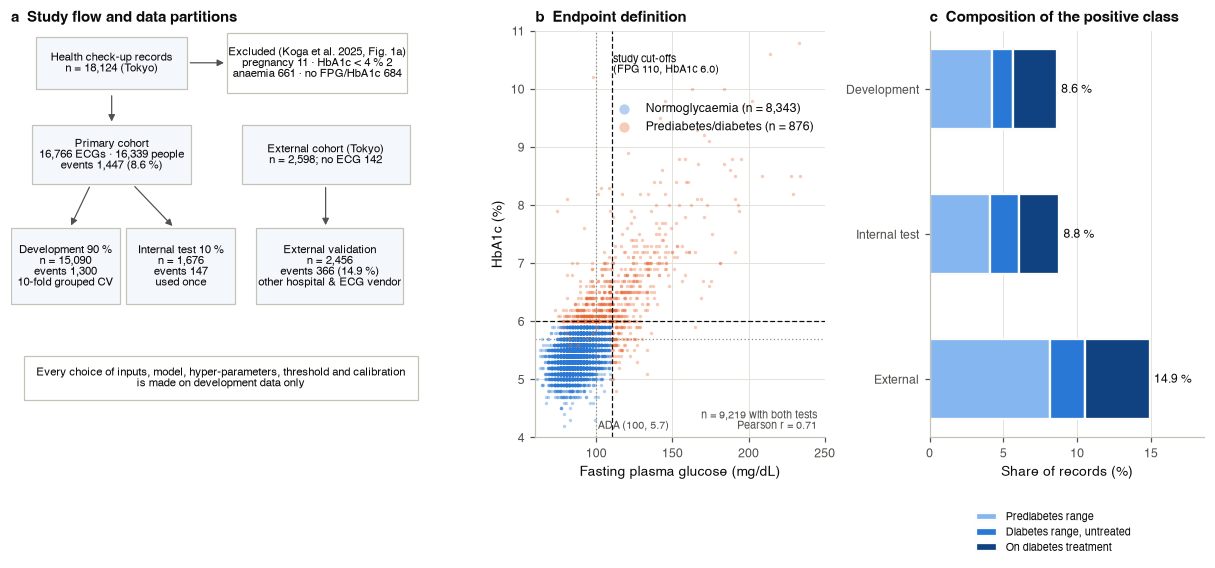

In [9]:
fig = plt.figure(figsize=(14, 4.8))
gs = fig.add_gridspec(1, 3, width_ratios=[1.45, 1, 0.95], wspace=0.32)
ax = fig.add_subplot(gs[0])
ax.axis("off"); ax.set_xlim(0, 10); ax.set_ylim(0, 10.2)


def box(x, yy, text, w=3.6, h=1.3, fc="#f4f8fd"):
    ax.add_patch(plt.Rectangle((x - w / 2, yy - h / 2), w, h, fc=fc, ec=C.INK["axis"], lw=0.8))
    ax.text(x, yy, text, ha="center", va="center", fontsize=7.4, color=C.INK["primary"])


def arrow(x0, y0, x1, y1):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", color=C.INK["secondary"], lw=0.8))


box(2.4, 9.4, "Health check-up records\nn = 18,124 (Tokyo)", w=3.6)
box(7.3, 9.4, "Excluded (Koga et al. 2025, Fig. 1a)\npregnancy 11 · HbA1c < 4 % 2\nanaemia 661 · no FPG/HbA1c 684", w=4.3, h=1.5, fc="white")
arrow(4.2, 9.4, 5.15, 9.4)
box(2.4, 7.1, f"Primary cohort\n{len(pc):,} ECGs · {pc.participant_id.nunique():,} people\n"
              f"events {pc[C.LABEL].sum():,} ({100 * pc[C.LABEL].mean():.1f} %)", w=3.8, h=1.5)
arrow(2.4, 8.65, 2.4, 7.85)
box(1.3, 4.3, f"Development 90 %\nn = {len(dev):,}\nevents {y['dev'].sum():,}\n10-fold grouped CV", w=2.6, h=1.9)
box(4.05, 4.3, f"Internal test 10 %\nn = {len(test):,}\nevents {y['test'].sum():,}\nused once", w=2.6, h=1.9)
arrow(1.9, 6.35, 1.4, 5.25); arrow(2.9, 6.35, 3.9, 5.25)
box(7.5, 7.1, f"External cohort (Tokyo)\nn = {len(ext_all):,}; no ECG {len(ext_all) - len(ext)}", w=4.0, h=1.5)
box(7.6, 4.3, f"External validation\nn = {len(ext):,}\nevents {y['ext'].sum():,} ({100 * y['ext'].mean():.1f} %)\nother hospital & ECG vendor", w=3.5, h=1.9)
arrow(7.5, 6.35, 7.5, 5.25)
box(5.0, 1.5, "Every choice of inputs, model, hyper-parameters, threshold and calibration\nis made on development data only",
    w=9.4, h=1.1, fc="white")
ax.set_title("a  Study flow and data partitions", loc="left")

ax = fig.add_subplot(gs[1])
both = pc.dropna(subset=["FPG", "HbA1c"])
for lab, name in [(False, "Normoglycaemia"), (True, "Prediabetes/diabetes")]:
    d = both[both[C.LABEL] == lab]
    ax.scatter(d.FPG, d.HbA1c, s=5, alpha=0.35, lw=0, color=C.CLASS_COLORS[name], label=f"{name} (n = {len(d):,})", rasterized=True)
ax.axvline(110, color=C.INK["primary"], lw=0.8, ls=(0, (4, 2)))
ax.axhline(6.0, color=C.INK["primary"], lw=0.8, ls=(0, (4, 2)))
ax.axvline(100, color=C.INK["muted"], lw=0.8, ls=(0, (1, 2)))
ax.axhline(5.7, color=C.INK["muted"], lw=0.8, ls=(0, (1, 2)))
ax.text(111, 10.6, "study cut-offs\n(FPG 110, HbA1c 6.0)", fontsize=7, color=C.INK["primary"], va="top")
ax.text(101, 4.15, "ADA (100, 5.7)", fontsize=7, color=C.INK["secondary"])
r = both[["FPG", "HbA1c"]].corr().iloc[0, 1]
ax.text(245, 4.15, f"n = {len(both):,} with both tests\nPearson r = {r:.2f}", ha="right", fontsize=7, color=C.INK["secondary"])
ax.set(xlim=(60, 250), ylim=(4, 11), xlabel="Fasting plasma glucose (mg/dL)", ylabel="HbA1c (%)")
ax.legend(loc="upper right", markerscale=3, bbox_to_anchor=(1.0, 0.85))
ax.set_title("b  Endpoint definition", loc="left")

ax = fig.add_subplot(gs[2])


def composition(df):
    tx = df.dm_under_treatment.astype(bool)
    return pd.Series({"Prediabetes range": df.prediabetes_only.sum(), "Diabetes range, untreated": (df.diabetes_range & ~tx).sum(),
                      "On diabetes treatment": tx.sum()}) / len(df) * 100


comp = pd.DataFrame({"Development": composition(dev), "Internal test": composition(test), "External": composition(ext)}).T
ordinal = ["#86b6ef", "#2a78d6", "#104281"]
left = np.zeros(len(comp))
for c, col in zip(comp.columns, ordinal):
    ax.barh(comp.index, comp[c], left=left, color=col, edgecolor=C.INK["surface"], linewidth=1.5, height=0.55, label=c)
    left += comp[c].values
for i, tot in enumerate(left):
    ax.text(tot + 0.3, i, f"{tot:.1f} %", va="center", fontsize=8, color=C.INK["primary"])
ax.invert_yaxis(); ax.set_xlim(0, max(left) * 1.25)
ax.set_xlabel("Share of records (%)"); ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.16), fontsize=7, ncol=1)
ax.set_title("c  Composition of the positive class", loc="left")
P.savefig(fig, "fig01_study_flow_endpoint", data=comp.reset_index().rename(columns={"index": "partition"}))
plt.show()

**Figure 1.**
- **(a)** Study flow. Exclusions before the primary cohort are as reported by Koga *et al.* (Fig. 1a); every count after that is recomputed from the files.
- **(b)** FPG and HbA1c in records with both tests. Dashed lines show the study cut-offs; dotted lines show the ADA prediabetes cut-offs.
- **(c)** The positive class split into prediabetes-range, untreated diabetes-range and treated records.

The external cohort has a higher prevalence. That is a prevalence shift: it affects PPV and calibration, not AUROC.

## 3. Validation design and pre-specified input sets
**Data split.**
- **Participant-disjoint 90/10 split, as published.** Using the authors' own `development_data` flag makes the internal-test results directly comparable with DiaCardia.
- **10-fold stratified *grouped* CV inside development.** Repeat visits of one person never fall into both the training and the validation folds. Hyper-parameter tuning uses a separate 5-fold grouped split.
- **External cohort.** A different hospital, ECG manufacturer and year; it tests transportability and is never used to choose anything.

**Candidate input sets.** These are fixed *before* any modelling and ordered by the burden they put on the user:

| Set | Inputs | Where the device gets them |
|---|---|---|
| ECG | 32 lead-I features | computed on the ESP32-S3 from the AD8232 |
| ECG + profile | + age, sex, BMI | profile typed on the dashboard (BMI = weight / height²) |
| ECG + profile + BP | + systolic and diastolic BP | cuffless estimate (ECG R peak → MAX30102 pulse arrival time) or a home cuff reading |
| ECG + profile + BP + lifestyle | + smoking, drinking frequency | two extra questions |

**Non-ECG references.** Profile; profile + BP; profile + BP + lifestyle. They measure what the ECG adds. They are not deployment candidates, because the device exists to read the ECG.

The **32 ECG features** are the 28 DiaCardia-equivalent lead-I features plus 4 standard ECG measures fixed in advance from physiology: P→R interval, Q→T-peak interval, its Bazett correction, and the T/R amplitude ratio. The 28-feature subset is reported as a sensitivity analysis.

In [10]:
ECG = list(ef.EDGE_ALL)
NONECG = C.CLINICAL + C.BLOOD_PRESSURE + C.LIFESTYLE
SETS = {   # deployment candidates, ordered by burden on the user (Section 6 selects one)
    "ECG": ECG,
    "ECG + profile": ECG + C.CLINICAL,
    "ECG + profile + BP": ECG + C.CLINICAL + C.BLOOD_PRESSURE,
    "ECG + profile + BP + lifestyle": ECG + C.CLINICAL + C.BLOOD_PRESSURE + C.LIFESTYLE,
}
REFS = {   # non-ECG references: what the ECG must add to
    "Profile": list(C.CLINICAL),
    "Profile + BP": C.CLINICAL + C.BLOOD_PRESSURE,
    "Profile + BP + lifestyle": C.CLINICAL + C.BLOOD_PRESSURE + C.LIFESTYLE,
}

splits10 = M.cv_splits(y["dev"], g["dev"], n_splits=10)
fold_rows = []
for k, (tr, va) in enumerate(splits10, 1):
    fold_rows.append({"fold": k, "training n": len(tr), "validation n": len(va), "validation events": int(y["dev"][va].sum()),
                      "validation prevalence %": 100 * y["dev"][va].mean(),
                      "participants in both": len(set(g["dev"][tr]) & set(g["dev"][va]))})
folds = save_table(pd.DataFrame(fold_rows).set_index("fold"), "cv_folds")
assert folds["participants in both"].sum() == 0


def part(df, yy, gg):
    return {"records": len(df), "participants": len(set(gg)), "events": int(yy.sum()), "prevalence %": 100 * yy.mean(),
            "prediabetes range": int(df.prediabetes_only.sum()), "diabetes range": int(df.diabetes_range.sum()),
            "on treatment": int(df.dm_under_treatment.sum())}


split_tab = save_table(pd.DataFrame({"Development (90 %)": part(dev, y["dev"], g["dev"]),
                                     "Internal test (10 %)": part(test, y["test"], g["test"]),
                                     "External validation": part(ext, y["ext"], g["ext"])}), "table_partitions")
epv = pd.DataFrame({n: {"candidate predictors": len(c), "development events": int(y["dev"].sum()),
                        "events per predictor": y["dev"].sum() / len(c)} for n, c in {**SETS, **REFS}.items()}).T
save_table(epv, "table_events_per_predictor")
display(split_tab, folds, epv)

,Development (90 %),Internal test (10 %),External validation
records,15090.000,1676.000,2456.000
participants,14705.000,1634.000,2456.000
events,1300.000,147.000,366.000
prevalence %,8.615,8.771,14.902
prediabetes range,639.000,69.000,200.000
diabetes range,661.000,78.000,166.000
on treatment,446.000,46.000,107.000


,training n,validation n,validation events,validation prevalence %,participants in both
fold,,,,,
1,13582,1508,118,7.825,0
2,13585,1505,138,9.169,0
3,13575,1515,109,7.195,0
4,13579,1511,134,8.868,0
5,13584,1506,143,9.495,0
6,13580,1510,129,8.543,0
7,13584,1506,134,8.898,0
8,13577,1513,130,8.592,0
9,13574,1516,123,8.113,0


,candidate predictors,development events,events per predictor
ECG,32.0,1300.0,40.625
ECG + profile,35.0,1300.0,37.143
ECG + profile + BP,37.0,1300.0,35.135
ECG + profile + BP + lifestyle,39.0,1300.0,33.333
Profile,3.0,1300.0,433.333
Profile + BP,5.0,1300.0,260.000
Profile + BP + lifestyle,7.0,1300.0,185.714


## 4. Benchmark: reproduction of the published DiaCardia models
1. The published 10-model ensembles (lead I and 12-lead) are applied to the internal test set and the external cohort **without retraining**.
   - They only reproduce the paper when the features are median-imputed and standardised with development-set statistics, as described in the paper's Methods.
   - The released `test.py` skips this step; its AUROC is shown for completeness.
2. A LightGBM is re-tuned on the same 28 published features with the leakage-free grouped CV of this study. It shows what the published *features* achieve under our validation design.

In [11]:
def published_predict(models, X, X_dev):
    # The released models were trained on median-imputed, standard-scaled features (development-set statistics);
    # the released test.py omits this step.
    Z = (X.fillna(X_dev.median()) - X_dev.mean()) / X_dev.std(ddof=0)
    return np.mean([m.predict(Z.values.astype(float)) for m in models], axis=0)


Xnk = {"dev": nk1.loc[idx["dev"], feat28], "test": nk1.loc[idx["test"], feat28], "ext": nkx.loc[idx["ext"], feat28]}
nk12_dev = nk12.loc[idx["dev"], feat269]
pub_pred = {"test": published_predict(pub1, Xnk["test"], Xnk["dev"]), "ext": published_predict(pub1, Xnk["ext"], Xnk["dev"])}
pub12_pred = {"test": published_predict(pub12, nk12.loc[idx["test"], feat269], nk12_dev),
              "ext": published_predict(pub12, nkx.loc[idx["ext"], feat269], nk12_dev)}
raw_auc = roc_auc_score(y["test"], np.mean([m.predict(Xnk["test"].values) for m in pub1], axis=0))
print(f"Published lead-I models fed raw (unscaled) features, as in the released test.py: AUROC {raw_auc:.3f}")
print("Reported by Koga et al.: lead I 0.844 (0.811–0.877) internal test; 12-lead 0.851 internal, 0.785 external")


def run_nk2():
    Xd, Xt, Xe = (Xnk[k].to_numpy(dtype=float) for k in ("dev", "test", "ext"))
    tuned = M.tune("lgbm", Xd, y["dev"], g["dev"], n_trials=RUN["n_trials"]["lgbm_full"], space="full",
                   cache_path=TUNE_DIR / "nk2_lgbm_full.json")
    oof, fa = M.oof_predictions("lgbm", tuned["best_params"], Xd, y["dev"], g["dev"], splits10)
    m = M.fit_final("lgbm", tuned["best_params"], Xd, y["dev"], g["dev"])
    return {"params": tuned["best_params"], "oof": oof, "fold_auc": fa, "thr": S.youden_threshold(y["dev"], oof),
            "test": m.predict_proba(Xt)[:, 1], "ext": m.predict_proba(Xe)[:, 1]}


nk2_lgbm = cached("nk2_lgbm_full", run_nk2)


def bench_row(score_test, thr, score_ext, oof=None):
    tm = S.threshold_metrics(y["test"], score_test, thr)
    return {"CV AUROC (OOF)": f"{roc_auc_score(y['dev'], oof):.3f}" if oof is not None else "—",
            "Internal test AUROC (95 % CI)": ci_str(S.auc_delong_ci(y["test"], score_test)),
            "Sensitivity %": f"{100 * tm['sensitivity']:.1f}", "Specificity %": f"{100 * tm['specificity']:.1f}",
            "External AUROC (95 % CI)": ci_str(S.auc_delong_ci(y["ext"], score_ext))}


tab_bench = save_table(pd.DataFrame({
    "DiaCardia lead I (published models)": bench_row(pub_pred["test"], pub1_thr, pub_pred["ext"]),
    "DiaCardia 12-lead (published models, reference)": bench_row(pub12_pred["test"], pub12_thr, pub12_pred["ext"]),
    "LightGBM, 28 published lead-I features (this study)": bench_row(nk2_lgbm["test"], nk2_lgbm["thr"], nk2_lgbm["ext"], nk2_lgbm["oof"]),
}).T, "table2_benchmark_published")
tab_bench

Published lead-I models fed raw (unscaled) features, as in the released test.py: AUROC 0.417
Reported by Koga et al.: lead I 0.844 (0.811–0.877) internal test; 12-lead 0.851 internal, 0.785 external


,CV AUROC (OOF),Internal test AUROC (95 % CI),Sensitivity %,Specificity %,External AUROC (95 % CI)
DiaCardia lead I (published models),—,0.844 (0.811–0.877),82.3,70.2,0.746 (0.721–0.772)
"DiaCardia 12-lead (published models, reference)",—,0.851 (0.820–0.883),85.7,70.2,0.785 (0.761–0.808)
"LightGBM, 28 published lead-I features (this study)",0.778,0.843 (0.810–0.875),78.2,73.8,0.746 (0.721–0.772)


**Interpretation (Section 4).**
- **Exact reproduction of the published benchmark.** The published DiaCardia lead-I ensemble gives an internal-test AUROC of 0.844 (0.811–0.877), sensitivity 82.3 % and specificity 70.2 %, identical to Koga *et al.* The 12-lead ensemble also matches: 0.851 internal, 0.785 external. This validates the data handling, the units and the split.
- **Preprocessing is part of the published model.** The models reproduce the paper only after median imputation and standardisation with development statistics. Fed raw features, as in the released `test.py`, they give 0.417.
- **The lead-I model transports less well.** Its external AUROC (0.746), which the paper does not report, is clearly below the internal value. This is the realistic expectation for a new hospital and ECG vendor.
- **Cross-validation vs test.** A LightGBM re-tuned on the same 28 features with leakage-free *grouped* CV reaches a CV AUROC of 0.778 but 0.843 on the test set. The 1,676-record test set (147 events, AUROC standard error ≈ 0.017) is better separated than the average development fold. The 10-fold CV over 1,300 events is the more precise estimate of performance, and the external AUROC is the most conservative one. All three are reported throughout.

## 5. From the clinical ECG to the device: simulated ESP32-S3 signal chain and embedded features
The published features cannot be used on the device, for three reasons:
1. **They cannot run on an ESP32.** NeuroKit2 (wavelet delineation, pandas) is a PC pipeline.
2. **The device signal differs from the clinical signal.** The AD8232 board has analogue filters (≈ 0.5–40 Hz) and a gain of ≈ 1100. The ESP32-S3 reads it with a 12-bit SAR ADC as integer millivolts (`analogReadMilliVolts`).
3. **Train/deploy skew.** Any difference between the feature code in training and in firmware silently degrades a TinyML device.

**Solution.** `ml/dgx/edge_features.py` is a micro-controller-portable extractor. It uses only:
- biquad IIR filters and moving averages;
- a gradient-based R-peak detector with T-wave rejection;
- fixed-window P/Q/S/T search.

It is the line-by-line specification of the C++ port `firmware/DiaGnostixECG/ecg_features.h`. Every raw lead-I record is passed through the simulated device before feature extraction:
1. µV conversion;
2. AD8232 2-pole 0.5 Hz high-pass and 2-pole 40 Hz low-pass;
3. ESP32-S3 ADC: offset 1.65 V, gain 1100, 3 mV noise, clipping to 0–3.1 V, integer mV;
4. conversion back to µV.

The model is then trained on exactly these features.

| Condition | AD8232 filters | ESP32-S3 ADC | Meaning |
|---|---|---|---|
| `clinical_500` | no | no | the extractor on the clinical ECG (parity with NeuroKit2) |
| `ad8232_500` | yes | ideal | the analogue front-end alone |
| `esp32s3_500` | yes | yes | **deployment condition** (the device) |

In [12]:
CONDITIONS = {"clinical_500": dict(frontend=False, adc=None),
              "ad8232_500": dict(frontend=True, adc=None),
              "esp32s3_500": dict(frontend=True, adc="esp32s3")}
DEV_COND = "esp32s3_500"


def edge_table(X, ids, name, uv=C.UV_PER_LSB, **kw):
    path = C.CACHE_DIR / f"edge_{name}.parquet"
    if path.exists():
        return pd.read_parquet(path)
    df = pd.DataFrame(ef.extract_batch(X, uv_per_lsb=uv, fs_dev=C.FS_DEVICE, **kw), index=ids)
    df.to_parquet(path)
    return df


t0 = time.time()
EDGE = {}
for cond, kw in CONDITIONS.items():
    EDGE[("int", cond)] = edge_table(raw_int, pc.index, f"int_{cond}", **kw)
    EDGE[("ext", cond)] = edge_table(raw_ext, ext.index, f"ext_{cond}", uv=C.UV_PER_LSB_EXTERNAL, **kw)
EI, EX = EDGE[("int", DEV_COND)], EDGE[("ext", DEV_COND)]
print(f"edge features: {len(CONDITIONS)} conditions × {len(pc) + len(ext):,} records in {time.time() - t0:.0f} s")
_n_i, _n_e = ~pc[C.LABEL].values, ~ext[C.LABEL].values
for f_ in ["mean_r_uv", "mean_t_uv", "mean_s_uv"]:
    print(f"unit harmonisation, normoglycaemic median {f_}: internal {EDGE[('int', 'clinical_500')][f_][_n_i].median():7.1f} µV | "
          f"external {EDGE[('ext', 'clinical_500')][f_][_n_e].median():7.1f} µV")


# ADC headroom: does the AD8232 output (gain 1100 around the 1.65 V reference) stay inside the ADC range?
def _swing_mv(x, uv):
    v = ef.simulate_ad8232(x.astype(float) * uv, C.FS_CLINICAL) * C.AD8232_GAIN / 1000.0
    return float(v.max()), float(v.min())


def headroom():
    return {coh: np.array(Parallel(n_jobs=-1, batch_size=256)(delayed(_swing_mv)(x, uv) for x in X))
            for coh, X, uv in [("internal", raw_int, C.UV_PER_LSB), ("external", raw_ext, C.UV_PER_LSB_EXTERNAL)]}


swing = cached("adc_swing", headroom)
hi_lim, lo_lim = C.ADC_FULL_SCALE_MV - C.ADC_REF_MV, -C.ADC_REF_MV
headroom_tab = save_table(pd.DataFrame({coh: {
    "records": len(s), "positive swing at GPIO4, median (mV)": np.median(s[:, 0]),
    "positive swing, 99th percentile (mV)": np.percentile(s[:, 0], 99), "headroom above REF (mV)": hi_lim,
    "records reaching the ADC limit (%)": 100 * np.mean((s[:, 0] > hi_lim) | (s[:, 1] < lo_lim))} for coh, s in swing.items()}).T,
    "table_adc_headroom")
display(headroom_tab.round(2))
EI.loc[idx["dev"], ef.EDGE_ALL].describe().T[["mean", "std", "min", "50%", "max"]].round(3)

edge features: 3 conditions × 19,222 records in 0 s
unit harmonisation, normoglycaemic median mean_r_uv: internal   396.2 µV | external   385.5 µV
unit harmonisation, normoglycaemic median mean_t_uv: internal   151.3 µV | external   144.0 µV
unit harmonisation, normoglycaemic median mean_s_uv: internal  -113.9 µV | external  -110.5 µV


,records,"positive swing at GPIO4, median (mV)","positive swing, 99th percentile (mV)",headroom above REF (mV),records reaching the ADC limit (%)
internal,16766.0,526.41,1456.22,1450.0,1.06
external,2456.0,527.23,1339.13,1450.0,0.53


,mean,std,min,50%,max
mean_rr_s,0.940,0.138,0.380,0.933,3.226
sd_rr_s,0.036,0.041,0.001,0.026,1.277
mean_r_uv,444.665,235.989,9.551,406.648,1412.586
sd_r_uv,34.229,20.780,1.764,29.941,305.996
mean_pp_s,0.940,0.138,0.379,0.934,3.248
sd_pp_s,0.038,0.044,0.001,0.027,1.278
mean_p_uv,48.827,16.966,-22.533,47.443,151.394
sd_p_uv,10.220,6.459,1.583,8.676,120.133
mean_tt_s,0.940,0.138,0.380,0.933,3.218
sd_tt_s,0.038,0.040,0.003,0.027,1.275


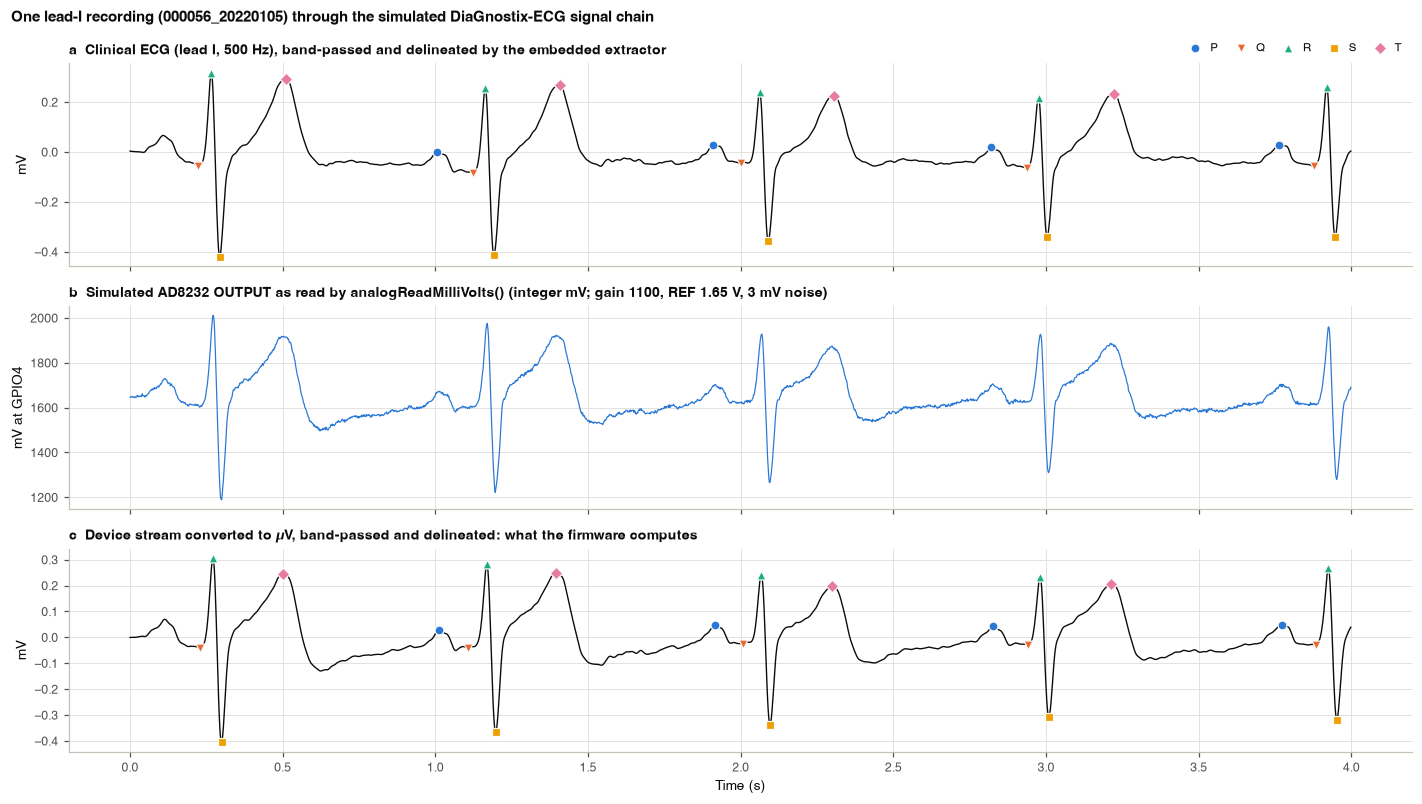

In [13]:
ex_id = next(i for i in idx["test"] if 62 < EI.loc[i, "hr_mean_bpm"] < 72 and EI.loc[i, "sqi_ok"])
k = pc.index.get_loc(ex_id)
_, dbg_c = ef.process_record(raw_int[k], uv_per_lsb=C.UV_PER_LSB, fs_dev=C.FS_DEVICE, seed=k, return_debug=True, **CONDITIONS["clinical_500"])
_, dbg_d = ef.process_record(raw_int[k], uv_per_lsb=C.UV_PER_LSB, fs_dev=C.FS_DEVICE, seed=k, return_debug=True, **CONDITIONS[DEV_COND])
marks = {"P": ("o", C.SERIES[0]), "Q": ("v", C.SERIES[1]), "R": ("^", C.SERIES[2]), "S": ("s", C.SERIES[3]), "T": ("D", C.SERIES[4])}


def fid_plot(ax, dbg, title, t_max=4.0):
    fs, yv = dbg["fs"], dbg["y"] / 1000
    tt = np.arange(len(yv)) / fs
    sel = tt < t_max
    ax.plot(tt[sel], yv[sel], color=C.INK["primary"], lw=0.9)
    for (lab, (mk, col)), fid in zip(marks.items(), dbg["fiducials"]):
        f = fid[(fid >= 0) & (fid / fs < t_max)]
        ax.scatter(f / fs, yv[f], marker=mk, s=34, color=col, edgecolor=C.INK["surface"], linewidth=0.8, zorder=3, label=lab)
    ax.set_ylabel("mV")
    ax.set_title(title, loc="left", fontsize=9)


fig, axes = plt.subplots(3, 1, figsize=(13, 7.4), sharex=True)
fid_plot(axes[0], dbg_c, "a  Clinical ECG (lead I, 500 Hz), band-passed and delineated by the embedded extractor")
pin = C.ADC_REF_MV + dbg_d["x"] * C.AD8232_GAIN / 1000.0
tt = np.arange(len(pin)) / C.FS_DEVICE
axes[1].plot(tt[tt < 4.0], pin[tt < 4.0], color=C.SERIES[0], lw=0.8)
axes[1].set_ylabel("mV at GPIO4")
axes[1].set_title("b  Simulated AD8232 OUTPUT as read by analogReadMilliVolts() (integer mV; gain 1100, REF 1.65 V, 3 mV noise)",
                  loc="left", fontsize=9)
fid_plot(axes[2], dbg_d, "c  Device stream converted to µV, band-passed and delineated: what the firmware computes")
axes[0].legend(ncol=5, loc="lower right", bbox_to_anchor=(1.0, 1.0), fontsize=7.5, handletextpad=0.3, columnspacing=1.0)
axes[-1].set_xlabel("Time (s)")
fig.suptitle(f"One lead-I recording ({ex_id}) through the simulated DiaGnostix-ECG signal chain", x=0.01, ha="left",
             fontsize=10, fontweight="bold")
fig.tight_layout()
P.savefig(fig, "fig02_device_signal_chain")
plt.show()

### 5.1 Is the embedded R-peak detector accurate?
There is no beat-annotated reference, so the check-up **pulse rate**, measured independently of the ECG, is the referee. The two are not simultaneous, so small differences are physiological. Gross errors point to detector failure:
- a heart rate ≈ 2 × pulse means T waves were counted as R peaks;
- a heart rate ≈ ½ × pulse means beats were missed.

,MAE vs pulse (bpm),|HR − pulse| > 15 bpm (%),"double counting, HR/pulse 1.7–2.3 (%)","missed beats, HR/pulse 0.4–0.6 (%)"
source,,,,
NeuroKit2 (published features),1.573,2.201,1.360,0.000
"Embedded extractor, clinical_500",0.418,0.173,0.030,0.018
"Embedded extractor, ad8232_500",0.426,0.215,0.030,0.030
"Embedded extractor, esp32s3_500",0.430,0.209,0.036,0.030


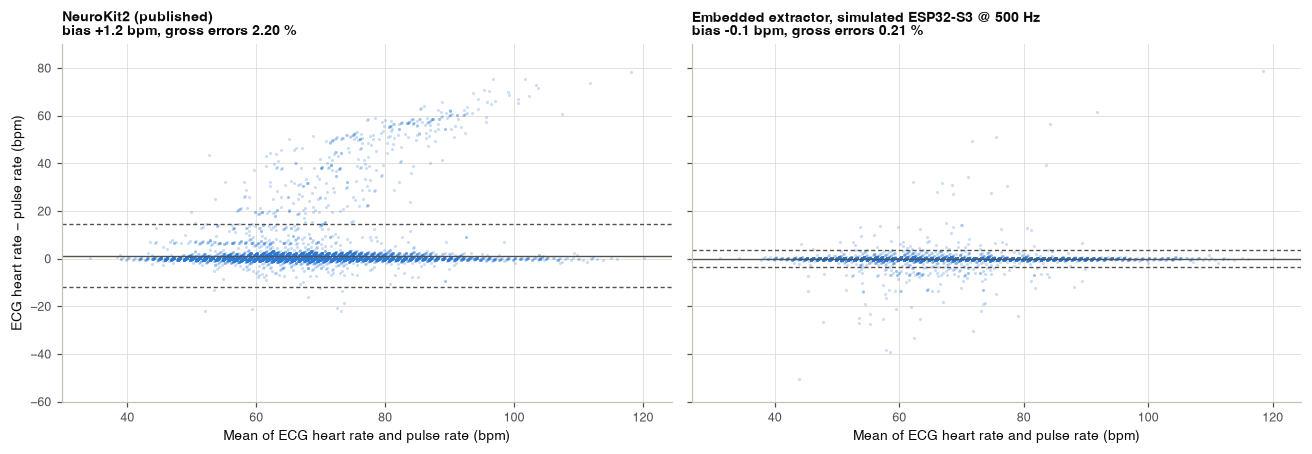

In [14]:
pulse = pc.pulse_rate


def hr_errors(hr, name):
    m = pulse.notna() & hr.notna()
    d, ratio = (hr - pulse)[m], (hr / pulse)[m]
    return {"source": name, "MAE vs pulse (bpm)": d.abs().mean(), "|HR − pulse| > 15 bpm (%)": 100 * (d.abs() > 15).mean(),
            "double counting, HR/pulse 1.7–2.3 (%)": 100 * ratio.between(1.7, 2.3).mean(),
            "missed beats, HR/pulse 0.4–0.6 (%)": 100 * ratio.between(0.4, 0.6).mean()}


hr_tab = [hr_errors(60 / nk1.loc[pc.index, "mean_rr_interval_I"], "NeuroKit2 (published features)")]
hr_tab += [hr_errors(60 / EDGE[("int", c)].mean_rr_s, f"Embedded extractor, {c}") for c in CONDITIONS]
hr_tab = save_table(pd.DataFrame(hr_tab).set_index("source"), "table_rpeak_accuracy_vs_pulse")
display(hr_tab.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, (name, hr) in zip(axes, [("NeuroKit2 (published)", 60 / nk1.loc[pc.index, "mean_rr_interval_I"]),
                                 ("Embedded extractor, simulated ESP32-S3 @ 500 Hz", 60 / EI.mean_rr_s)]):
    m = pulse.notna() & hr.notna()
    mean, diff = ((hr + pulse) / 2)[m], (hr - pulse)[m]
    ax.scatter(mean, diff, s=4, alpha=0.25, lw=0, color=C.SERIES[0], rasterized=True)
    for v, ls in [(diff.mean(), "-"), (diff.mean() + 1.96 * diff.std(), (0, (3, 2))), (diff.mean() - 1.96 * diff.std(), (0, (3, 2)))]:
        ax.axhline(v, color=C.INK["secondary"], lw=0.9, ls=ls)
    ax.set_title(f"{name}\nbias {diff.mean():+.1f} bpm, gross errors {100 * (diff.abs() > 15).mean():.2f} %", loc="left", fontsize=9)
    ax.set_xlabel("Mean of ECG heart rate and pulse rate (bpm)")
axes[0].set_ylabel("ECG heart rate − pulse rate (bpm)"); axes[0].set_ylim(-60, 90)
fig.tight_layout()
P.savefig(fig, "fig03_rpeak_bland_altman")
plt.show()

### 5.2 Feature parity with NeuroKit2, effect of the ESP32-S3 ADC, and the signal-quality index (SQI)
**A naming error in the published features.** In `codes/feature_extractor.py`, the feature called `RMSSD` is computed as `mean((60/RR)²)`, the mean squared instantaneous heart rate. Because mean(x²) = mean(x)² + var(x), `RMSSD_I` is an exact function of two other features (checked below). The embedded extractor computes the true RMSSD.

In [15]:
identity = nk1.mean_heartrate_r_I ** 2 + nk1.R_HR_STD_I ** 2
print(f"max relative difference between RMSSD_I and mean_HR² + SD_HR²: {((identity - nk1.RMSSD_I).abs() / nk1.RMSSD_I).max():.2e}")
ua_nk = S.univariate_auc(Xnk["dev"], y["dev"])
ua_edge = S.univariate_auc(EI.loc[idx["dev"], ef.EDGE_ALL], y["dev"])
E500, EAD = EDGE[("int", "clinical_500")], EDGE[("int", "ad8232_500")]
par = []
for e in ef.EDGE_ALL:
    n = ef.EDGE_TO_NK2.get(e)
    par.append({"embedded feature": e, "published feature": n or "— (new)",
                "ρ vs NeuroKit2 (clinical 500 Hz)": st.spearmanr(E500[e], nk1.loc[pc.index, n], nan_policy="omit").correlation if n else np.nan,
                "ρ ideal ADC vs ESP32-S3 ADC": st.spearmanr(EAD[e], EI[e], nan_policy="omit").correlation,
                "AUROC embedded (device)": ua_edge[e], "AUROC published": ua_nk[n] if n else np.nan})
par = save_table(pd.DataFrame(par).set_index("embedded feature"), "table_feature_parity")
display(par.round(3))

sqi_rows = []
for cond in CONDITIONS:
    for coh, df, yy in [("internal", EDGE[("int", cond)], pc[C.LABEL].values), ("external", EDGE[("ext", cond)], ext[C.LABEL].values)]:
        fail = ~df.sqi_ok.values.astype(bool)
        tab = [[(fail & (yy == 0)).sum(), (~fail & (yy == 0)).sum()], [(fail & (yy == 1)).sum(), (~fail & (yy == 1)).sum()]]
        sqi_rows.append({"condition": cond, "cohort": coh, "SQI fail %": 100 * fail.mean(),
                         "fail % normoglycaemia": 100 * fail[yy == 0].mean(), "fail % prediabetes/diabetes": 100 * fail[yy == 1].mean(),
                         "Fisher P (fail vs label)": st.fisher_exact(tab)[1]})
sqi_tab = save_table(pd.DataFrame(sqi_rows), "table_sqi", index=False)
sqi_tab.round(3)

max relative difference between RMSSD_I and mean_HR² + SD_HR²: 1.03e-15


,published feature,ρ vs NeuroKit2 (clinical 500 Hz),ρ ideal ADC vs ESP32-S3 ADC,AUROC embedded (device),AUROC published
embedded feature,,,,,
mean_rr_s,mean_rr_interval_I,0.909,1.000,0.375,0.392
sd_rr_s,sd_rr_interval_I,0.820,1.000,0.327,0.317
mean_r_uv,mean_r_peak_I,0.977,1.000,0.691,0.699
sd_r_uv,sd_r_peak_I,0.687,0.992,0.639,0.597
mean_pp_s,mean_pp_interval_I,0.926,1.000,0.375,0.387
sd_pp_s,sd_pp_interval_I,0.788,0.994,0.348,0.345
mean_p_uv,mean_p_peak_I,0.871,1.000,0.541,0.534
sd_p_uv,sd_p_peak_I,0.519,0.995,0.574,0.509
mean_tt_s,mean_tt_interval_I,0.924,1.000,0.375,0.390


,condition,cohort,SQI fail %,fail % normoglycaemia,fail % prediabetes/diabetes,Fisher P (fail vs label)
0,clinical_500,internal,0.877,0.901,0.622,0.374
1,clinical_500,external,2.484,2.632,1.639,0.361
2,ad8232_500,internal,1.014,1.058,0.553,0.073
3,ad8232_500,external,2.687,2.871,1.639,0.220
4,esp32s3_500,internal,1.020,1.064,0.553,0.074
5,esp32s3_500,external,2.647,2.823,1.639,0.220


**Interpretation (Section 5).**
- **Units.** After harmonisation, the normoglycaemic median R amplitude is 396 µV internally and 386 µV externally. The external files are indeed stored at 1.25 µV per unit.
- **ADC headroom.**
  - With gain 1100 around the 1.65 V reference, the median positive swing at GPIO4 is 526 mV.
  - 1.06 % of internal records (R waves above ≈ 1.3 mV) reach the 3.1 V limit of the ADC.

  Clipping is part of the simulation, so the models were trained with it. The firmware also reports clipped samples.
- **R-peak detection** (Table, Fig. 3). Against the independently measured pulse rate:

  | Error vs pulse | NeuroKit2 (published) | Embedded extractor, ESP32-S3 chain |
  |---|---|---|
  | Gross errors (\|HR − pulse\| > 15 bpm) | 2.20 % | 0.21 % |
  | T-wave double counting | 1.36 % | 0.04 % |
  | Mean absolute error | 1.57 bpm | 0.43 bpm |

  RR-interval features are among the strongest predictors, and one doubled beat corrupts them.
- **The ESP32-S3 ADC changes almost nothing.** Feature-wise Spearman ρ between an ideal ADC and the ESP32-S3 model (integer mV, 3 mV noise) is ≥ 0.99 for 31 of 32 features; the exception is QRS-width SD at 0.956.
- **Parity with NeuroKit2.**
  - Mean amplitudes agree with ρ 0.87–0.98 and mean intervals with ρ 0.91–0.93.
  - SD features (ρ 0.43–0.83) differ more, because the delineation definitions differ (peak-based vs wavelet onsets).
  - RMSSD differs by design. The published `RMSSD_I` equals mean HR² + SD HR² to 10⁻¹⁵, i.e. it is not an HRV measure; the embedded value is the true RMSSD.
- **Univariate discrimination of the device features** (direction-free AUROC):
  - the new T/R amplitude ratio: 0.71, lower in prediabetes/diabetes;
  - the true RMSSD: 0.69, lower;
  - mean R amplitude: 0.69, higher.
- **SQI.** With the ESP32-S3 chain, the quality gate rejects 1.0 % of internal and 2.6 % of external recordings. Rejection is not related to the label (Fisher P = 0.07 and 0.22; if anything, normoglycaemic recordings fail slightly more often), so abstaining does not bias who is screened.

## 6. Which inputs? Pre-specified input-set selection
Each candidate input set and each non-ECG reference is modelled with the same compact LightGBM family (≤ 300 trees, ≤ 16 leaves, depth ≤ 4), tuned by Optuna on development data. Classic logistic regression on age, sex and BMI is added as the textbook risk-score form.

**Blood pressure needs care.** The dataset's BP is a clinic cuff measurement, but the device estimates BP from the pulse arrival time (or the user types a home-cuff reading). A cuffless estimate carries error. Its size depends on calibration and is assumed here, not measured: SD 10 mmHg after a cuff calibration.

The selection rule therefore judges BP-containing sets on **out-of-fold predictions in which the validation folds' BP has a random error N(0, 10 mmHg)**. The models themselves are trained on cuff BP.

**Rule (fixed before running).** Start from ECG. Move to the next larger set only if its (BP-error-adjusted) OOF AUROC is higher by ≥ 0.005. The last set reached is the primary input set.

In [16]:
FI = EI[ef.EDGE_ALL + ef.SQI_FIELDS].join(pc[NONECG])
FX = EX[ef.EDGE_ALL + ef.SQI_FIELDS]


def mats(cols, F_int=None, F_ext=None):
    F_int = FI if F_int is None else F_int
    out = {p: F_int.loc[idx[p], cols].to_numpy(dtype=float) for p in ("dev", "test")}
    if all(c in ef.EDGE_ALL for c in cols):
        F_ext = FX if F_ext is None else F_ext
        out["ext"] = F_ext.loc[idx["ext"], cols].to_numpy(dtype=float)
    return out


def slug(s):
    return "".join(ch if ch.isalnum() else "_" for ch in s.lower()).strip("_")


def develop(name, cols, kind, space=None):
    # Tune on development data (5-fold grouped CV), then 10-fold grouped OOF predictions. Cached on disk.
    key = f"{slug(name)}_{kind}_{space or 'std'}"
    X = mats(cols)
    budget = RUN["n_trials"].get(f"lgbm_{space}" if kind == "lgbm" else kind, 0)
    tuned = M.tune(kind, X["dev"], y["dev"], g["dev"], n_trials=budget, space=space or "full", cache_path=TUNE_DIR / f"{key}.json")
    oof, fa = cached(f"oof_{key}", lambda: M.oof_predictions(kind, tuned["best_params"], X["dev"], y["dev"], g["dev"], splits10))
    return {"name": name, "cols": list(cols), "kind": kind, "space": space, "key": key, "params": tuned["best_params"],
            "tuning": tuned, "oof": oof, "fold_auc": fa, "cv_auc": roc_auc_score(y["dev"], oof), "X": X}


def footprint(kind, model, n_feat):
    if kind in ("lgbm", "xgb", "rf"):
        clf = model.named_steps["clf"]
        if kind == "lgbm":
            t, i, l = M.tree_model_size(clf.booster_.dump_model()["tree_info"])
        elif kind == "xgb":
            df = clf.get_booster().trees_to_dataframe()
            leaf = (df.Feature == "Leaf").to_numpy()
            t, i, l = int(df.Tree.nunique()), int((~leaf).sum()), int(leaf.sum())
        else:
            t, i, l = M.sklearn_forest_size(clf.estimators_)
        return {"structure": f"{t} trees, {i:,} splits", "flash_bytes": M.lgbm_flash_bytes(i, l, t) + 8 * n_feat,
                "ram_bytes": 8 * n_feat + 64, "ops": f"{t} tree walks"}
    if kind == "mlp":
        n = int(model.model_.count_params())
        widths = [n_feat] + [l.units for l in model.model_.layers if hasattr(l, "units")]
        return {"structure": "-".join(map(str, widths)) + f" ({n:,} weights)", "flash_bytes": 4 * n + 24 * n_feat,
                "ram_bytes": 8 * max(widths) + 8 * n_feat, "ops": f"{sum(a * b for a, b in zip(widths[:-1], widths[1:])):,} MACs"}
    return {"structure": f"{n_feat + 1} coefficients", "flash_bytes": 8 * (n_feat + 1) + 24 * n_feat,
            "ram_bytes": 8 * n_feat, "ops": f"{n_feat} MACs"}


def fit(info):
    # Final model on all development data + test/external scores, OOF thresholds and Platt calibration.
    info = dict(info)
    m = M.fit_final(info["kind"], info["params"], info["X"]["dev"], y["dev"], g["dev"])
    info["model"] = m
    for part_ in ("test", "ext"):
        if part_ in info["X"]:
            info[part_] = m.predict_proba(info["X"][part_])[:, 1]
    info["thr"] = {"youden": S.youden_threshold(y["dev"], info["oof"]),
                   "sens90": S.threshold_for_sensitivity(y["dev"], info["oof"], 0.90)}
    info["platt"] = S.PlattCalibrator().fit(info["oof"], y["dev"])
    info.update(footprint(info["kind"], m, len(info["cols"])))
    return info


t0 = time.time()
dev_sets = {name: develop(name, cols, "lgbm", "compact") for name, cols in {**SETS, **REFS}.items()}
dev_sets["Profile (logistic regression)"] = develop("Profile (logistic regression)", C.CLINICAL, "lr")
ecg28 = develop("ECG 28 DiaCardia-equivalent", list(ef.EDGE_CORE), "lgbm", "compact")
for n, d_ in {**dev_sets, "ECG, 28-feature subset (sensitivity analysis)": ecg28}.items():
    print(f"{n:46s} {len(d_['cols']):2d} inputs | OOF AUROC {d_['cv_auc']:.3f}")
print(f"({(time.time() - t0) / 60:.1f} min)")

ECG                                            32 inputs | OOF AUROC 0.784
ECG + profile                                  35 inputs | OOF AUROC 0.843
ECG + profile + BP                             37 inputs | OOF AUROC 0.844
ECG + profile + BP + lifestyle                 39 inputs | OOF AUROC 0.844
Profile                                         3 inputs | OOF AUROC 0.828
Profile + BP                                    5 inputs | OOF AUROC 0.831
Profile + BP + lifestyle                        7 inputs | OOF AUROC 0.832
Profile (logistic regression)                   3 inputs | OOF AUROC 0.831
ECG, 28-feature subset (sensitivity analysis)  28 inputs | OOF AUROC 0.778
(0.0 min)


In [17]:
BP_SDS = [0, 5, 10, 15, 20]
BP_SETS = [n for n, c in {**SETS, **REFS}.items() if "sBP" in c]


def fold_models(info):
    X = info["X"]["dev"]
    return [M.fit_final(info["kind"], info["params"], X[tr], y["dev"][tr], g["dev"][tr]) for tr, _ in splits10]


def oof_with_bp_error(info, sd, models, seed=C.SEED):
    # OOF predictions when the validation folds' blood pressure carries a random error N(0, sd) mmHg
    cols, X = info["cols"], info["X"]["dev"]
    bp = [cols.index(c) for c in C.BLOOD_PRESSURE if c in cols]
    rng_ = np.random.default_rng(seed)
    oof = np.zeros(len(X))
    for m, (tr, va) in zip(models, splits10):
        Xv = X[va].copy()
        if bp and sd > 0:
            Xv[:, bp] += rng_.normal(0.0, sd, (len(va), len(bp)))
        oof[va] = m.predict_proba(Xv)[:, 1]
    return oof


def bp_curves():
    out = {}
    for n in BP_SETS:
        models = fold_models(dev_sets[n])
        out[n] = {sd: oof_with_bp_error(dev_sets[n], sd, models) for sd in BP_SDS}
    return out


bp_oof = cached("bp_error_oof", bp_curves)


def oof_eff(n):
    # OOF scores used by the selection rule: BP-containing sets carry the assumed device BP error
    return bp_oof[n][RUN["bp_error_sd"]] if n in bp_oof else dev_sets[n]["oof"]


order = list(SETS)
current, steps = order[0], []
for nxt in order[1:]:
    a_cur, a_nxt = roc_auc_score(y["dev"], oof_eff(current)), roc_auc_score(y["dev"], oof_eff(nxt))
    _, p_ = S.delong_test(y["dev"], oof_eff(nxt), oof_eff(current))
    keep = a_nxt - a_cur >= RUN["min_gain"]
    steps.append({"step": f"{current} → {nxt}", "OOF AUROC, current set": a_cur, "OOF AUROC, larger set": a_nxt,
                  "gain": a_nxt - a_cur, "DeLong P (OOF)": p_, "decision": "add" if keep else "do not add"})
    if keep:
        current = nxt
PRIMARY_SET = current
PRIMARY_COLS = list(SETS[PRIMARY_SET])

rows = []
for n, d_ in {**dev_sets, "ECG, 28-feature subset": ecg28}.items():
    rows.append({"input set": n, "role": "candidate" if n in SETS else ("sensitivity analysis" if "28" in n else "reference (no ECG)"),
                 "inputs": len(d_["cols"]), "model": "compact LightGBM" if d_["kind"] == "lgbm" else "logistic regression",
                 "events per predictor": y["dev"].sum() / len(d_["cols"]),
                 "OOF AUROC (95 % CI)": ci_str(S.auc_delong_ci(y["dev"], d_["oof"])),
                 "fold AUROC mean ± SD": f"{d_['fold_auc'].mean():.3f} ± {d_['fold_auc'].std():.3f}",
                 f"OOF AUROC, BP error SD {RUN['bp_error_sd']:g} mmHg": roc_auc_score(y["dev"], bp_oof[n][RUN["bp_error_sd"]]) if n in bp_oof else np.nan,
                 "selected": n == PRIMARY_SET})
set_tab = save_table(pd.DataFrame(rows).set_index("input set"), "table3_input_sets")
step_tab = save_table(pd.DataFrame(steps).set_index("step"), "table3b_input_selection_steps")
display(set_tab, step_tab.round(4))
print(f"Pre-specified rule → primary input set: {PRIMARY_SET} ({len(PRIMARY_COLS)} inputs)")

,role,inputs,model,events per predictor,OOF AUROC (95 % CI),fold AUROC mean ± SD,"OOF AUROC, BP error SD 10 mmHg",selected
input set,,,,,,,,
ECG,candidate,32,compact LightGBM,40.625,0.784 (0.771–0.796),0.784 ± 0.013,NaN,False
ECG + profile,candidate,35,compact LightGBM,37.143,0.843 (0.833–0.853),0.844 ± 0.010,NaN,True
ECG + profile + BP,candidate,37,compact LightGBM,35.135,0.844 (0.834–0.854),0.844 ± 0.011,0.843,False
ECG + profile + BP + lifestyle,candidate,39,compact LightGBM,33.333,0.844 (0.834–0.854),0.844 ± 0.011,0.843,False
Profile,reference (no ECG),3,compact LightGBM,433.333,0.828 (0.818–0.839),0.828 ± 0.014,NaN,False
Profile + BP,reference (no ECG),5,compact LightGBM,260.000,0.831 (0.821–0.842),0.831 ± 0.015,0.830,False
Profile + BP + lifestyle,reference (no ECG),7,compact LightGBM,185.714,0.832 (0.821–0.842),0.832 ± 0.012,0.827,False
Profile (logistic regression),reference (no ECG),3,logistic regression,433.333,0.831 (0.820–0.842),0.831 ± 0.014,NaN,False
"ECG, 28-feature subset",sensitivity analysis,28,compact LightGBM,46.429,0.778 (0.766–0.790),0.779 ± 0.012,NaN,False


,"OOF AUROC, current set","OOF AUROC, larger set",gain,DeLong P (OOF),decision
step,,,,,
ECG → ECG + profile,0.784,0.843,5.940e-02,0.000,add
ECG + profile → ECG + profile + BP,0.843,0.843,-1.000e-04,0.874,do not add
ECG + profile → ECG + profile + BP + lifestyle,0.843,0.843,-1.000e-04,0.886,do not add


Pre-specified rule → primary input set: ECG + profile (35 inputs)


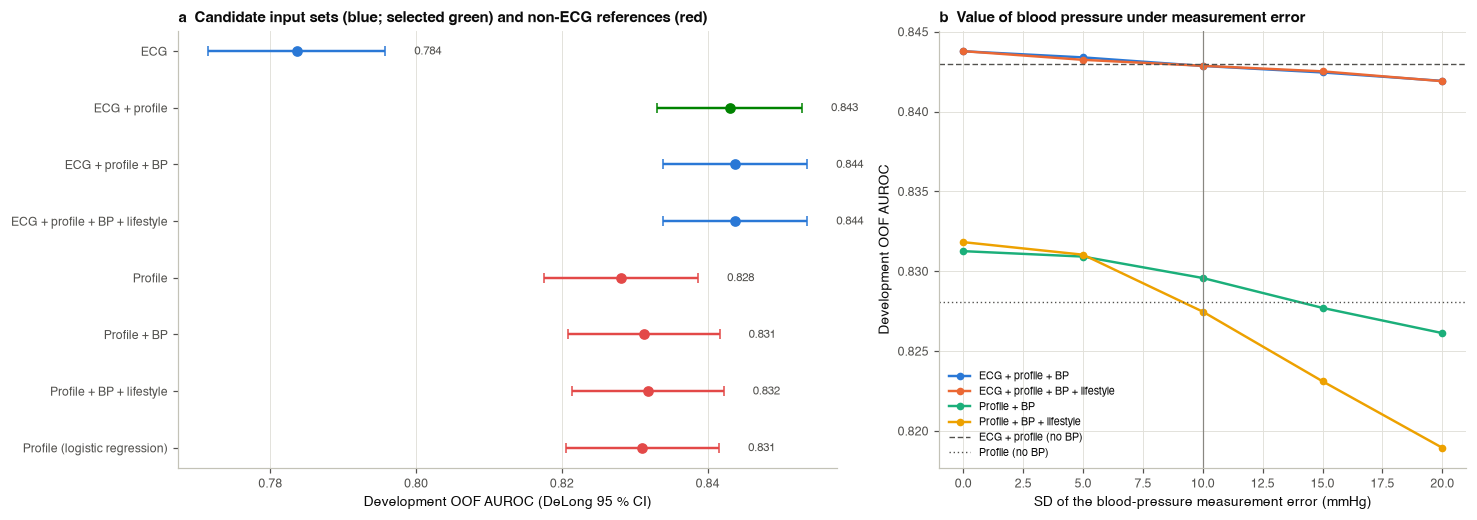

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
names = list(dev_sets)[::-1]
for i, n in enumerate(names):
    a = S.auc_delong_ci(y["dev"], dev_sets[n]["oof"])
    col = C.SERIES[5] if n == PRIMARY_SET else (C.SERIES[0] if n in SETS else C.SERIES[7])
    ax.errorbar(a[0], i, xerr=[[a[0] - a[1]], [a[2] - a[0]]], fmt="o", color=col, ms=6, capsize=3)
    ax.text(a[2] + 0.004, i, f"{a[0]:.3f}", va="center", fontsize=7.5, color=C.INK["secondary"])
ax.set_yticks(range(len(names)), names); ax.grid(axis="y", visible=False)
ax.set_xlabel("Development OOF AUROC (DeLong 95 % CI)")
ax.set_title("a  Candidate input sets (blue; selected green) and non-ECG references (red)", loc="left")
ax = axes[1]
for n, col in zip(BP_SETS, C.SERIES):
    ax.plot(BP_SDS, [roc_auc_score(y["dev"], bp_oof[n][sd]) for sd in BP_SDS], marker="o", ms=4, color=col, label=n)
for n, ls in [("ECG + profile", (0, (4, 2))), ("Profile", (0, (1, 2)))]:
    ax.axhline(dev_sets[n]["cv_auc"], color=C.INK["secondary"], lw=0.9, ls=ls, label=f"{n} (no BP)")
ax.axvline(RUN["bp_error_sd"], color=C.INK["muted"], lw=0.8)
ax.set(xlabel="SD of the blood-pressure measurement error (mmHg)", ylabel="Development OOF AUROC")
ax.legend(fontsize=7, loc="lower left")
ax.set_title("b  Value of blood pressure under measurement error", loc="left")
fig.tight_layout()
P.savefig(fig, "fig04_input_set_selection", data=set_tab.reset_index())
plt.show()

**Interpretation (Section 6): which inputs earn their place.**
- **The profile is the larger single source.**
  - ECG alone: OOF AUROC 0.784.
  - Age, sex and BMI alone: 0.828 (compact LightGBM) and 0.831 (logistic regression).
- **The combination is clearly better than either source.** ECG + profile reaches 0.843: +0.059 over the ECG (DeLong P < 10⁻⁴⁰), and better than the profile alone. The rule therefore adds the profile.
- **Blood pressure and lifestyle add nothing once ECG and profile are present.**
  - ECG + profile + BP: 0.844 with cuff BP, 0.843 with a 10 mmHg device error (gain −0.0001).
  - Adding lifestyle does not change this.

  BP helps a profile-only model a little (0.828 → 0.831), but that information is already carried by the ECG and the profile.
- **Consequences for the device:**
  - the primary model needs only the AD8232 and four typed values (age, sex, height, weight);
  - the MAX30102, the cuffless BP and its cuff calibration are not needed for the risk, and keep their monitoring role;
  - no extra questions burden the user.
- **28 vs 32 ECG features** (sensitivity analysis): 0.778 vs 0.784. The four pre-specified physiological features are kept.

## 7. Which model family? Pre-specified selection under the micro-controller budget, and is the dataset large enough?
On the primary input set, six families are tuned and cross-validated identically:

| Family | Role | Why |
|---|---|---|
| Compact LightGBM (≤ 300 trees, ≤ 16 leaves, depth ≤ 4) | MCU candidate | small node table in C |
| Logistic regression (L1/L2) | MCU candidate | a few hundred bytes; transparent |
| MLP (Keras, 1–3 hidden layers) | MCU candidate | exportable as `.h5` → TFLite or plain C |
| XGBoost | reference | is a stronger booster worth more? |
| Random forest | reference | deep trees, too large for flash |
| Unconstrained LightGBM | reference | the cost of the size limit |

**Rule (fixed before running).** Pick the highest OOF AUROC among the three MCU candidates. If several are within 0.005, the smallest flash footprint wins.

**Is the dataset large enough?**
- **Learning curve:** does more data still help?
- **Riley *et al.* (BMJ 2020) minimum sample size**, with the anticipated Cox–Snell R² estimated from the selected model's OOF predictions.

In [19]:
FAMILIES = {"LightGBM (compact)": ("lgbm", "compact"), "Logistic regression": ("lr", None), "MLP": ("mlp", None),
            "XGBoost": ("xgb", None), "Random forest": ("rf", None), "LightGBM (unconstrained)": ("lgbm", "full")}
MCU = ["LightGBM (compact)", "Logistic regression", "MLP"]
FAM_COLORS = {"LightGBM (compact)": C.MODEL_COLORS["LightGBM"], "Logistic regression": C.MODEL_COLORS["Logistic regression"],
              "MLP": C.MODEL_COLORS["MLP"], "XGBoost": C.MODEL_COLORS["XGBoost"], "Random forest": C.MODEL_COLORS["Random forest"],
              "LightGBM (unconstrained)": C.INK["secondary"]}
fam = {}
for fname, (kind, space) in FAMILIES.items():
    t0 = time.time()
    fam[fname] = fit(develop(PRIMARY_SET, PRIMARY_COLS, kind, space))
    print(f"{fname:26s} OOF AUROC {fam[fname]['cv_auc']:.3f} | flash {fam[fname]['flash_bytes'] / 1024:9.1f} KB | "
          f"{fam[fname]['structure']} | {time.time() - t0:.0f} s")

best = max(fam[n]["cv_auc"] for n in MCU)
tied = [n for n in MCU if best - fam[n]["cv_auc"] < RUN["min_gain"]]
FAMILY = min(tied, key=lambda n: fam[n]["flash_bytes"])
FAM_KIND, FAM_SPACE = FAMILIES[FAMILY]
print(f"\nPre-specified rule → model family: {FAMILY} (MCU families within {RUN['min_gain']} of the best OOF AUROC: {tied})")

fam_tab = pd.DataFrame({n: {"family": f["kind"], "MCU-deployable": n in MCU, "structure": f["structure"],
                            "flash (KB)": f["flash_bytes"] / 1024, "OOF AUROC (95 % CI)": ci_str(S.auc_delong_ci(y["dev"], f["oof"])),
                            "fold AUROC mean ± SD": f"{f['fold_auc'].mean():.3f} ± {f['fold_auc'].std():.3f}",
                            "Δ vs selected (DeLong P, OOF)": "—" if n == FAMILY else
                            "{:+.3f} (P = {:.3g})".format(*S.delong_test(y["dev"], f["oof"], fam[FAMILY]["oof"])),
                            "tuning trials": f["tuning"]["n_trials"], "selected": n == FAMILY} for n, f in fam.items()}).T
save_table(fam_tab, "table4_model_families")
with open(C.MODEL_DIR / "selected_hyperparameters.json", "w") as fh:
    json.dump({n: {"kind": f["kind"], "space": f["space"], "params": f["params"], "inputs": f["cols"]} for n, f in fam.items()},
              fh, indent=1, default=str)
fam_tab

LightGBM (compact)         OOF AUROC 0.843 | flash      16.4 KB | 220 trees, 660 splits | 0 s
Logistic regression        OOF AUROC 0.845 | flash       1.1 KB | 36 coefficients | 0 s


MLP                        OOF AUROC 0.842 | flash      18.1 KB | 35-64-32-1 (4,417 weights) | 6 s


XGBoost                    OOF AUROC 0.842 | flash      33.2 KB | 450 trees, 1,349 splits | 1 s


Random forest              OOF AUROC 0.835 | flash     207.3 KB | 100 trees, 10,036 splits | 2 s


LightGBM (unconstrained)   OOF AUROC 0.843 | flash      60.7 KB | 825 trees, 2,475 splits | 1 s

Pre-specified rule → model family: Logistic regression (MCU families within 0.005 of the best OOF AUROC: ['LightGBM (compact)', 'Logistic regression', 'MLP'])


,family,MCU-deployable,structure,flash (KB),OOF AUROC (95 % CI),fold AUROC mean ± SD,"Δ vs selected (DeLong P, OOF)",tuning trials,selected
LightGBM (compact),lgbm,True,"220 trees, 660 splits",16.387,0.843 (0.833–0.853),0.844 ± 0.010,-0.002 (P = 0.24),60,False
Logistic regression,lr,True,36 coefficients,1.102,0.845 (0.835–0.855),0.845 ± 0.013,—,30,True
MLP,mlp,True,"35-64-32-1 (4,417 weights)",18.074,0.842 (0.832–0.852),0.843 ± 0.011,-0.003 (P = 0.024),4,False
XGBoost,xgb,False,"450 trees, 1,349 splits",33.212,0.842 (0.832–0.852),0.842 ± 0.009,-0.003 (P = 0.0512),40,False
Random forest,rf,False,"100 trees, 10,036 splits",207.262,0.835 (0.824–0.845),0.835 ± 0.012,-0.010 (P = 7.51e-06),20,False
LightGBM (unconstrained),lgbm,False,"825 trees, 2,475 splits",60.698,0.843 (0.833–0.853),0.844 ± 0.010,-0.002 (P = 0.237),40,False


Anticipated Cox–Snell R² from OOF predictions: 0.123; outcome proportion 0.086


,parameters assumed,criterion,records needed,events needed,available (development)
0,35 candidate inputs,(i) global shrinkage ≥ 0.9,2389,206,15090
1,35 candidate inputs,(ii) optimism in R² ≤ 0.05,1460,126,15090
2,35 candidate inputs,(iii) intercept within ± 0.05,121,11,15090
3,3 × 35 (allowance for non-linear terms),(i) global shrinkage ≥ 0.9,7165,618,15090
4,3 × 35 (allowance for non-linear terms),(ii) optimism in R² ≤ 0.05,4378,378,15090
5,3 × 35 (allowance for non-linear terms),(iii) intercept within ± 0.05,121,11,15090


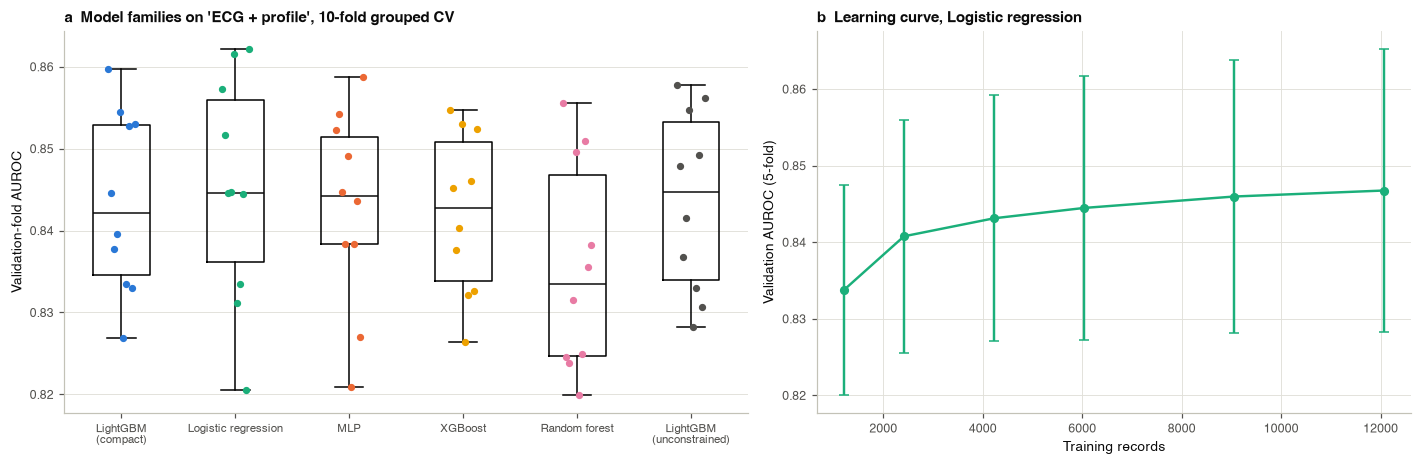

In [20]:
sel = fam[FAMILY]
cv5 = M.cv_splits(y["dev"], g["dev"], n_splits=5)


def learning_curve():
    out = []
    for frac in [0.1, 0.2, 0.35, 0.5, 0.75, 1.0]:
        for f_, (tr, va) in enumerate(cv5):
            sub = tr if frac == 1.0 else train_test_split(tr, train_size=frac, stratify=y["dev"][tr], random_state=f_)[0]
            m = M.fit_final(sel["kind"], sel["params"], sel["X"]["dev"][sub], y["dev"][sub], g["dev"][sub])
            out.append({"fraction": frac, "n_train": len(sub), "events": int(y["dev"][sub].sum()), "fold": f_,
                        "auc": roc_auc_score(y["dev"][va], m.predict_proba(sel["X"]["dev"][va])[:, 1])})
    return pd.DataFrame(out)


lc = cached(f"learning_curve_{sel['key']}", learning_curve)
lc_agg = lc.groupby("fraction").agg(n_train=("n_train", "mean"), events=("events", "mean"), mean=("auc", "mean"), std=("auc", "std")).reset_index()


def riley_sample_size(p, phi, r2cs, shrinkage=0.9, delta=0.05, margin=0.05):
    # Riley et al., BMJ 2020;368:m441, criteria (i)-(iii) for a binary outcome
    max_r2 = 1 - (phi ** phi * (1 - phi) ** (1 - phi)) ** 2
    n1 = p / ((shrinkage - 1) * np.log(1 - r2cs / shrinkage))
    s2 = r2cs / (r2cs + delta * max_r2)
    n2 = p / ((s2 - 1) * np.log(1 - r2cs / s2))
    n3 = (1.96 / margin) ** 2 * phi * (1 - phi)
    return {"(i) global shrinkage ≥ 0.9": n1, "(ii) optimism in R² ≤ 0.05": n2, "(iii) intercept within ± 0.05": n3}


phi = y["dev"].mean()
p_cal = np.clip(sel["platt"].transform(sel["oof"]), 1e-9, 1 - 1e-9)
ll = np.sum(y["dev"] * np.log(p_cal) + (1 - y["dev"]) * np.log(1 - p_cal))
ll0 = np.sum(y["dev"] * np.log(phi) + (1 - y["dev"]) * np.log(1 - phi))
r2cs = 1 - np.exp(-2 * (ll - ll0) / len(y["dev"]))
rows = []
for label, p_ in [(f"{len(PRIMARY_COLS)} candidate inputs", len(PRIMARY_COLS)),
                  (f"3 × {len(PRIMARY_COLS)} (allowance for non-linear terms)", 3 * len(PRIMARY_COLS))]:
    for crit, n_req in riley_sample_size(p_, phi, r2cs).items():
        rows.append({"parameters assumed": label, "criterion": crit, "records needed": int(np.ceil(n_req)),
                     "events needed": int(np.ceil(n_req * phi)), "available (development)": len(y["dev"])})
riley_tab = save_table(pd.DataFrame(rows), "table5_sample_size_riley", index=False)
print(f"Anticipated Cox–Snell R² from OOF predictions: {r2cs:.3f}; outcome proportion {phi:.3f}")
display(riley_tab)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
names = list(fam)
ax.boxplot([fam[n]["fold_auc"] for n in names], widths=0.5, showfliers=False, medianprops=dict(color=C.INK["primary"]))
for i, n in enumerate(names, 1):
    ax.scatter(np.full(10, i) + np.linspace(-0.12, 0.12, 10), fam[n]["fold_auc"], s=14, color=FAM_COLORS[n], zorder=3)
ax.set_xticks(range(1, len(names) + 1), [n.replace(" (", "\n(") for n in names], fontsize=7.5)
ax.set_ylabel("Validation-fold AUROC"); ax.grid(axis="x", visible=False)
ax.set_title(f"a  Model families on '{PRIMARY_SET}', 10-fold grouped CV", loc="left")
ax = axes[1]
ax.errorbar(lc_agg.n_train, lc_agg["mean"], yerr=lc_agg["std"], color=FAM_COLORS[FAMILY], marker="o", ms=5, capsize=3, lw=1.6)
ax.set(xlabel="Training records", ylabel="Validation AUROC (5-fold)")
ax.set_title(f"b  Learning curve, {FAMILY}", loc="left")
fig.tight_layout()
P.savefig(fig, "fig05_model_families_learning_curve", data=lc)
plt.show()

**Interpretation (Section 7).**
- **Model family hardly matters.** The three MCU families are statistically and practically tied: logistic regression 0.845, compact LightGBM 0.843, MLP 0.842 (all within 0.005). The pre-specified rule therefore picks the smallest, **logistic regression**: 36 coefficients, 1.1 KB.
- **Larger models do not help.**
  - The references reach 0.842 (XGBoost), 0.843 (unconstrained LightGBM, 61 KB) and 0.835 (random forest, 207 KB).
  - The micro-controller constraint costs nothing.
  - With profile variables that act almost linearly (age, BMI), a linear model is sufficient. It is also the most transparent model for clinicians.
- **The dataset is large enough.**
  - The learning curve rises from 0.834 (≈ 1,200 training records) to 0.847 (≈ 12,000) and flattens after ≈ 4,000 records.
  - The Riley criteria need at most 2,389 records (206 events) for 35 candidate parameters, or 7,165 with a 3× allowance for non-linear terms. 15,090 records are available, with 37 events per candidate predictor.

  More data of the same kind would add little. Larger gains need new information: other leads, or the raw waveform.

## 8. The three deployed models, thresholds and risk tiers
The firmware carries three models. Each model's family is chosen with the **same pre-specified rule** as in Section 7, applied to its own inputs: the highest OOF AUROC among the three MCU families, with ties (< 0.005) going to the smallest flash footprint. The primary model is the Section 7 result. A good family for ECG + profile is not necessarily good for the ECG alone.

| Model | Inputs | Used when |
|---|---|---|
| **Primary** | primary input set | the profile is entered **and** the AD8232 gain is calibrated |
| **Fallback** | primary set without the ECG *amplitude* features (timing/HRV and the T/R ratio only) | the profile is entered but the gain is **not** calibrated. Amplitudes depend on the exact AD8232 gain and electrode placement; timing does not |
| **ECG-only** | 32 ECG features | no profile entered (privacy mode). It is also the only model that can be validated on the external cohort, which has no age, sex or BMI |

**Thresholds** come from each model's development OOF predictions:
- **high tier:** score ≥ Youden threshold;
- **elevated tier:** 90 %-sensitivity threshold ≤ score < Youden threshold;
- **low tier:** below both.

If the 90 %-sensitivity threshold is above the Youden threshold, the elevated tier is empty.

**Calibration.** The probability shown to the user is Platt-recalibrated on the same OOF predictions. Recalibration is monotone, so it changes no tier.

In [21]:
ECG_COLS = [c for c in PRIMARY_COLS if c in ef.EDGE_ALL]
NON_ECG = [c for c in PRIMARY_COLS if c not in ef.EDGE_ALL]
GI_COLS = [c for c in ECG_COLS if c in ef.GAIN_INVARIANT]
ROLES = {
    "primary": {"set": PRIMARY_SET, "cols": PRIMARY_COLS, "prefix": "DGX_PRI", "header": "dgx_model_primary.h",
                "use": "profile entered and AD8232 gain calibrated"},
    "fallback": {"set": PRIMARY_SET.replace("ECG", "Gain-invariant ECG", 1), "cols": GI_COLS + NON_ECG, "prefix": "DGX_FB",
                 "header": "dgx_model_fallback.h", "use": "profile entered, AD8232 gain not calibrated"},
    "ecg_only": {"set": "ECG", "cols": list(ef.EDGE_ALL), "prefix": "DGX_ECG", "header": "dgx_model_ecg_only.h",
                 "use": "no profile entered (privacy mode), gain calibrated"},
}
ROLE_COLORS = {"primary": C.MODEL_COLORS["Device model"], "fallback": C.SERIES[0], "ecg_only": C.SERIES[1]}
ROLE_LABEL = {"primary": "Primary", "fallback": "Fallback (gain-invariant)", "ecg_only": "ECG-only"}

def select_family(name, cols):
    # Section 7 rule on any input set: best OOF AUROC among the MCU families, ties -> smallest flash
    cands = {fn: fit(develop(name, cols, *FAMILIES[fn])) for fn in MCU}
    top = max(c["cv_auc"] for c in cands.values())
    tie = [fn for fn in MCU if top - cands[fn]["cv_auc"] < RUN["min_gain"]]
    return min(tie, key=lambda fn: cands[fn]["flash_bytes"]), cands


final, fam_rows = {}, []
for role, r in ROLES.items():
    if role == "primary":
        chosen, cands = FAMILY, {fn: fam[fn] for fn in MCU}
    else:
        chosen, cands = select_family(r["set"], r["cols"])
    for fn, c in cands.items():
        fam_rows.append({"model": ROLE_LABEL[role], "family": fn, "OOF AUROC": c["cv_auc"], "flash (KB)": c["flash_bytes"] / 1024,
                         "structure": c["structure"], "selected": fn == chosen})
    final[role] = {**cands[chosen], "role": role, "family": chosen, **{k: v for k, v in r.items() if k != "cols"}}
pri, fb, eo = final["primary"], final["fallback"], final["ecg_only"]
display(save_table(pd.DataFrame(fam_rows).set_index(["model", "family"]), "table6a_family_per_deployed_model").round(4))


def tiers(info):
    t_high = info["thr"]["youden"]
    return min(info["thr"]["sens90"], t_high), t_high


def tier_of(score, info):
    lo, hi = tiers(info)
    return np.where(score >= hi, "High", np.where(score >= lo, "Elevated", "Low"))


rows = {}
for role, f in final.items():
    lo, hi = tiers(f)
    o_hi, o_lo = S.threshold_metrics(y["dev"], f["oof"], hi), S.threshold_metrics(y["dev"], f["oof"], lo)
    rows[ROLE_LABEL[role]] = {
        "inputs": f"{len(f['cols'])}: {f['set']}", "used when": f["use"], "family": f["family"], "OOF AUROC": round(f["cv_auc"], 3),
        "high tier: score ≥": hi, "high tier: calibrated risk ≥": f["platt"].transform(np.array([hi]))[0],
        "elevated tier: score ≥": lo, "elevated tier: calibrated risk ≥": f["platt"].transform(np.array([lo]))[0],
        "OOF sensitivity / specificity at high": f"{100 * o_hi['sensitivity']:.1f} / {100 * o_hi['specificity']:.1f}",
        "OOF sensitivity / specificity at elevated": f"{100 * o_lo['sensitivity']:.1f} / {100 * o_lo['specificity']:.1f}",
        "Platt a, b": f"{f['platt'].a_:.3f}, {f['platt'].b_:.3f}", "structure": f["structure"], "flash (KB)": round(f["flash_bytes"] / 1024, 1)}
final_tab = save_table(pd.DataFrame(rows).T, "table6_deployed_models")
final_tab.T

OOF AUROC  flash (KB)                   structure  selected
model                     family                                                                          
Primary                   LightGBM (compact)       0.843      16.387       220 trees, 660 splits     False
                          Logistic regression      0.845       1.102             36 coefficients      True
                          MLP                      0.842      18.074  35-64-32-1 (4,417 weights)     False
Fallback (gain-invariant) LightGBM (compact)       0.843      16.133       170 trees, 680 splits     False
                          Logistic regression      0.844       0.789             26 coefficients      True
                          MLP                      0.841       2.277       25-16-1 (433 weights)     False
ECG-only                  LightGBM (compact)       0.784      21.812       230 trees, 920 splits      True
                          Logistic regression      0.765       1.008             33 coefficients     False
                          MLP                      0.778       7.004  32-32-16-1 (1,601 weights)     False

,Primary,Fallback (gain-invariant),ECG-only
inputs,35: ECG + profile,25: Gain-invariant ECG + profile,32: ECG
used when,profile entered and AD8232 gain calibrated,"profile entered, AD8232 gain not calibrated","no profile entered (privacy mode), gain calibr..."
family,Logistic regression,Logistic regression,LightGBM (compact)
OOF AUROC,0.845,0.844,0.784
high tier: score ≥,0.523,0.507,0.078
high tier: calibrated risk ≥,0.094,0.09,0.078
elevated tier: score ≥,0.348,0.332,0.044
elevated tier: calibrated risk ≥,0.051,0.049,0.044
OOF sensitivity / specificity at high,78.0 / 77.1,79.3 / 76.1,76.3 / 67.5
OOF sensitivity / specificity at elevated,90.0 / 61.0,90.0 / 60.1,90.0 / 48.5


**Interpretation (Section 8).**
- **Family per deployed model** (Table 6a; same rule as Section 7):
  - **Primary** (ECG + profile): logistic regression, OOF AUROC 0.845.
  - **Fallback** (gain-invariant ECG + profile): logistic regression, 0.844. Logistic regression, LightGBM (0.843) and the MLP (0.841) tie, and the smallest wins.
  - **ECG-only:** compact LightGBM, 0.784, clearly ahead of the MLP (0.778) and logistic regression (0.765). Without the profile, the ECG features interact non-linearly, so forcing one family on all three models would have cost the ECG-only model 0.019 AUROC.
- **The fallback loses almost nothing.** Without amplitude features it reaches 0.844 OOF and 0.876 on the test set, vs 0.878 for the primary (Section 9). With the profile included, the ECG amplitudes contribute little beyond timing, HRV and the T/R ratio. An uncalibrated device is therefore nearly as accurate as a calibrated one.
- **Tiers** (primary, calibrated risk):
  - high from 9.4 %;
  - elevated from 5.1 %.

  In development OOF predictions, the high tier has sensitivity 78.0 % and specificity 77.1 %, and the elevated-or-high tier 90.0 % and 61.0 %.
- **Why Platt recalibration is needed.** The logistic and LightGBM scores are not probabilities, because training used class weighting. The Platt step maps them to the observed risk.

## 9. Internal test set: performance of the primary model
The test set was used for nothing above. Metrics are reported at the two pre-specified operating points:
- the **Youden** (high-tier) threshold;
- the **90 %-sensitivity** (elevated-tier) threshold.

95 % CIs: DeLong for AUROC; percentile bootstrap with 2,000 participant-cluster resamples for everything else.

In [22]:
p_test, pc_test = pri["test"], pri["platt"].transform(pri["test"])
THR = {"youden": pri["thr"]["youden"], "sens90": pri["thr"]["sens90"]}
summ = {k: S.summarize(y["test"], p_test, THR[k], p_prob=pc_test, groups=g["test"], n_boot=RUN["n_boot"]) for k in THR}
oof_pt = {k: S.threshold_metrics(y["dev"], pri["oof"], THR[k]) for k in THR}
METRICS = ["AUROC", "AUPRC", "sensitivity", "specificity", "PPV", "NPV", "PLR", "NLR", "F1", "G-mean", "MCC", "accuracy", "Brier"]
PCT = {"sensitivity", "specificity", "PPV", "NPV", "accuracy"}


def oof_fmt(d, m):
    return f"{100 * d[m]:.1f}" if m in PCT else (f"{d[m]:.3f}" if m in d else "")


tab7 = pd.DataFrame({
    f"Youden / high tier (score ≥ {THR['youden']:.3f})": [S.fmt_ci(summ["youden"].loc[m], pct=m in PCT) for m in METRICS],
    "dev. OOF (Youden)": [oof_fmt(oof_pt["youden"], m) for m in METRICS],
    f"90 %-sensitivity / elevated (score ≥ {THR['sens90']:.3f})": [S.fmt_ci(summ["sens90"].loc[m], pct=m in PCT) for m in METRICS],
    "dev. OOF (90 %-sens.)": [oof_fmt(oof_pt["sens90"], m) for m in METRICS],
}, index=[m + (" %" if m in PCT else "") for m in METRICS])
save_table(tab7, "table7_internal_test_primary")
display(Markdown(f"**Table 7. Primary model ({FAMILY}; {PRIMARY_SET}, {len(PRIMARY_COLS)} inputs) on the internal test set "
                 f"(n = {len(test):,}, {y['test'].sum()} events).** Confusion counts: Youden {summ['youden'].attrs['counts']}, "
                 f"90 %-sensitivity {summ['sens90'].attrs['counts']}."))
tab7

**Table 7. Primary model (Logistic regression; ECG + profile, 35 inputs) on the internal test set (n = 1,676, 147 events).** Confusion counts: Youden {'TP': 121, 'FP': 362, 'TN': 1167, 'FN': 26}, 90 %-sensitivity {'TP': 135, 'FP': 574, 'TN': 955, 'FN': 12}.

,Youden / high tier (score ≥ 0.523),dev. OOF (Youden),90 %-sensitivity / elevated (score ≥ 0.348),dev. OOF (90 %-sens.)
AUROC,0.878 (0.853–0.903),,0.878 (0.853–0.903),
AUPRC,0.426 (0.350–0.516),,0.426 (0.350–0.516),
sensitivity %,82.3 (76.2–88.5),78.0,91.8 (87.2–96.0),90.0
specificity %,76.3 (74.2–78.5),77.1,62.5 (60.0–65.0),61.0
PPV %,25.1 (21.2–28.9),24.3,19.0 (16.1–22.0),17.9
NPV %,97.8 (96.9–98.6),97.4,98.8 (98.0–99.4),98.5
PLR,3.477 (3.099–3.911),3.406,2.446 (2.263–2.651),2.306
NLR,0.232 (0.151–0.312),0.285,0.131 (0.064–0.205),0.164
F1,0.384 (0.336–0.430),0.371,0.315 (0.273–0.356),0.298
G-mean,0.793 (0.761–0.824),0.775,0.757 (0.734–0.780),0.741


In [23]:
REF_KEY = next((n for n, c in REFS.items() if c == NON_ECG), "Profile")
refs_fit = {n: fit(dev_sets[n]) for n in dict.fromkeys([REF_KEY, "Profile", "Profile (logistic regression)"])}
comparators = {f"Fallback ({fb['set']})": fb["test"]}
if PRIMARY_SET != "ECG":
    comparators["ECG-only"] = eo["test"]
comparators.update({f"{n} (no ECG)": r["test"] for n, r in refs_fit.items()})
comparators.update({"DiaCardia lead I (published, NeuroKit2 features)": pub_pred["test"],
                    "LightGBM on the 28 published NeuroKit2 features": nk2_lgbm["test"]})
a_pri = S.auc_delong_ci(y["test"], p_test)
cmp_rows = []
for n, p in comparators.items():
    d, pval = S.delong_test(y["test"], p_test, p)
    cmp_rows.append({"comparator": n, "comparator AUROC (95 % CI)": ci_str(S.auc_delong_ci(y["test"], p)),
                     "ΔAUROC (primary − comparator)": f"{d:+.3f}", "DeLong P": pval})
cmp_tab = save_table(pd.DataFrame(cmp_rows).set_index("comparator"), "table8_delong_internal_test")
print(f"Primary model, internal test AUROC {ci_str(a_pri)}")
display(cmp_tab)


def nri_ci(p_old, p_new):
    point = S.nri_idi(y["test"], p_old, p_new)
    boot = S.bootstrap(lambda yy, a, b: S.nri_idi(yy, a, b), y["test"], p_old, p_new, groups=g["test"], n_boot=RUN["n_boot"])
    return {k: f"{point[k]:+.3f} ({boot[k].quantile(.025):+.3f} to {boot[k].quantile(.975):+.3f})" for k in ["cfNRI", "NRI_events", "NRI_nonevents", "IDI"]}


def calp(f):
    return f["platt"].transform(f["test"])


recl = {f"Primary vs {REF_KEY}: does the ECG add information?": nri_ci(calp(refs_fit[REF_KEY]), pc_test)}
if PRIMARY_SET != "ECG":
    recl["Primary vs ECG-only: do the non-ECG inputs add information?"] = nri_ci(calp(eo), pc_test)
recl["ECG-only vs Profile: ECG alone vs age, sex, BMI alone"] = nri_ci(calp(refs_fit["Profile"]), calp(eo))
recl = save_table(pd.DataFrame(recl).T, "table9_reclassification")
recl

Primary model, internal test AUROC 0.878 (0.853–0.903)


,comparator AUROC (95 % CI),ΔAUROC (primary − comparator),DeLong P
comparator,,,
Fallback (Gain-invariant ECG + profile),0.876 (0.850–0.901),+0.003,2.514e-01
ECG-only,0.845 (0.813–0.878),+0.033,4.168e-03
Profile (no ECG),0.852 (0.826–0.879),+0.026,1.176e-04
Profile (logistic regression) (no ECG),0.851 (0.824–0.878),+0.028,1.505e-05
"DiaCardia lead I (published, NeuroKit2 features)",0.844 (0.811–0.877),+0.034,4.195e-03
LightGBM on the 28 published NeuroKit2 features,0.843 (0.810–0.875),+0.035,2.212e-03


,cfNRI,NRI_events,NRI_nonevents,IDI
Primary vs Profile: does the ECG add information?,+0.278 (+0.120 to +0.442),+0.238 (+0.083 to +0.392),+0.040 (-0.012 to +0.090),+0.053 (+0.035 to +0.072)
Primary vs ECG-only: do the non-ECG inputs add information?,+0.533 (+0.377 to +0.706),+0.224 (+0.068 to +0.384),+0.308 (+0.260 to +0.359),+0.067 (+0.041 to +0.096)
"ECG-only vs Profile: ECG alone vs age, sex, BMI alone",-0.352 (-0.535 to -0.184),-0.116 (-0.282 to +0.051),-0.236 (-0.288 to -0.187),-0.014 (-0.043 to +0.012)


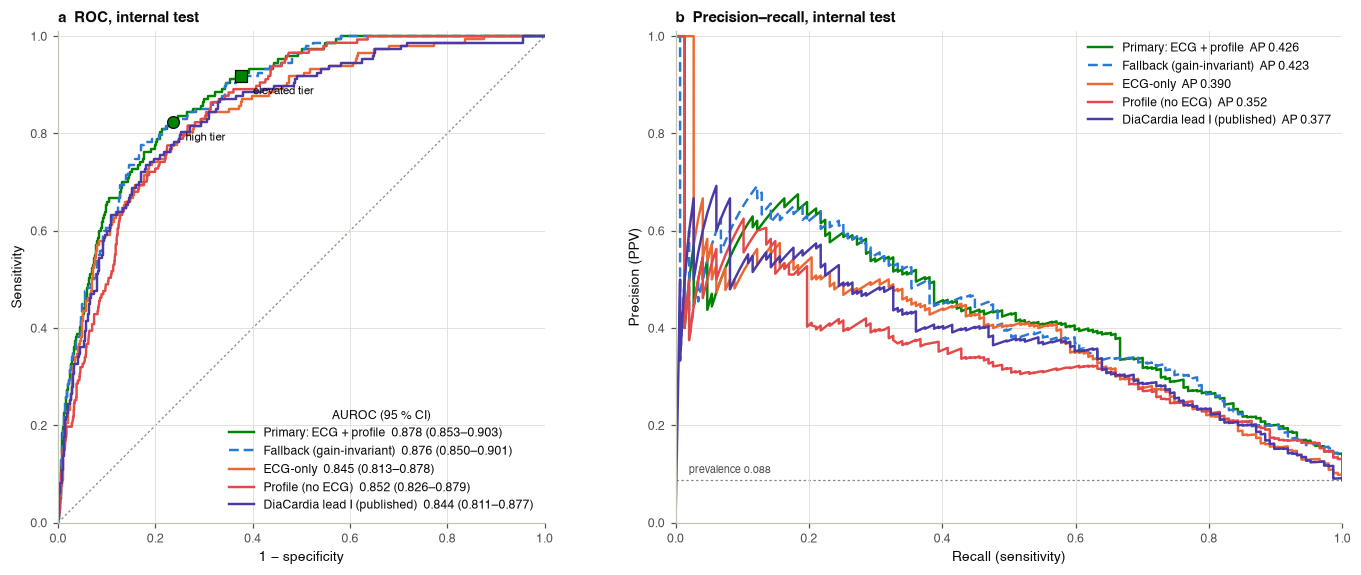

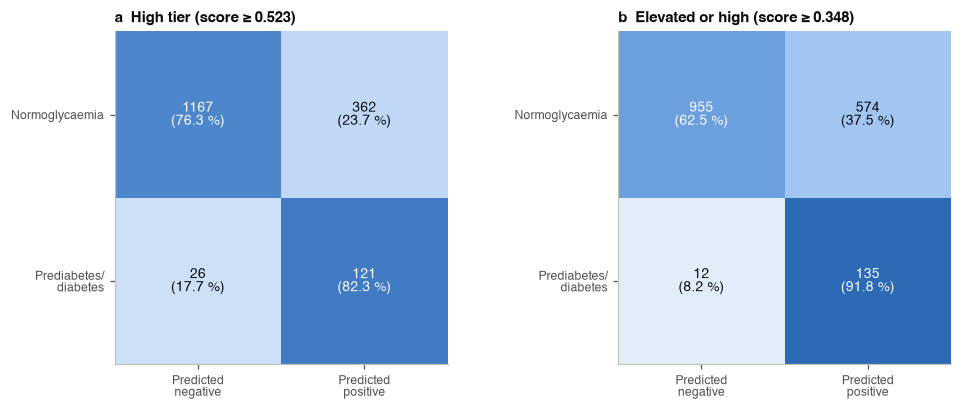

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.3))
curves = [(f"Primary: {PRIMARY_SET}", y["test"], p_test, ROLE_COLORS["primary"]),
          ("Fallback (gain-invariant)", y["test"], fb["test"], ROLE_COLORS["fallback"], (0, (4, 2)))]
if PRIMARY_SET != "ECG":
    curves.append(("ECG-only", y["test"], eo["test"], ROLE_COLORS["ecg_only"]))
curves += [(f"{REF_KEY} (no ECG)", y["test"], refs_fit[REF_KEY]["test"], C.MODEL_COLORS["Clinical-only"]),
           ("DiaCardia lead I (published)", y["test"], pub_pred["test"], C.MODEL_COLORS["DiaCardia (published)"])]
d1 = P.roc_panel(axes[0], curves, "a  ROC, internal test")
for k, mk in [("youden", "o"), ("sens90", "s")]:
    s_ = summ[k]
    xy = (1 - s_.loc["specificity", "estimate"], s_.loc["sensitivity", "estimate"])
    axes[0].scatter(*xy, marker=mk, s=60, zorder=4, color=ROLE_COLORS["primary"], edgecolor=C.INK["primary"], linewidth=0.8)
    axes[0].annotate("high tier" if k == "youden" else "elevated tier", xy, xytext=(8, -12), textcoords="offset points", fontsize=7.5)
d2 = P.pr_panel(axes[1], curves, "b  Precision–recall, internal test")
fig.tight_layout()
P.savefig(fig, "fig06_roc_pr_internal_test", data=pd.concat([d1, d2]))
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8))
P.confusion_panel(axes[0], summ["youden"].attrs["counts"], f"a  High tier (score ≥ {THR['youden']:.3f})")
P.confusion_panel(axes[1], summ["sens90"].attrs["counts"], f"b  Elevated or high (score ≥ {THR['sens90']:.3f})")
fig.tight_layout()
P.savefig(fig, "fig07_confusion_matrices")
plt.show()

,calibration_intercept,calibration_slope,Brier,ECE,mean_predicted,observed_rate
uncalibrated score,-2.452,1.066,0.163,0.269,0.357,0.088
Platt-recalibrated,-0.039,1.159,0.062,0.011,0.090,0.088


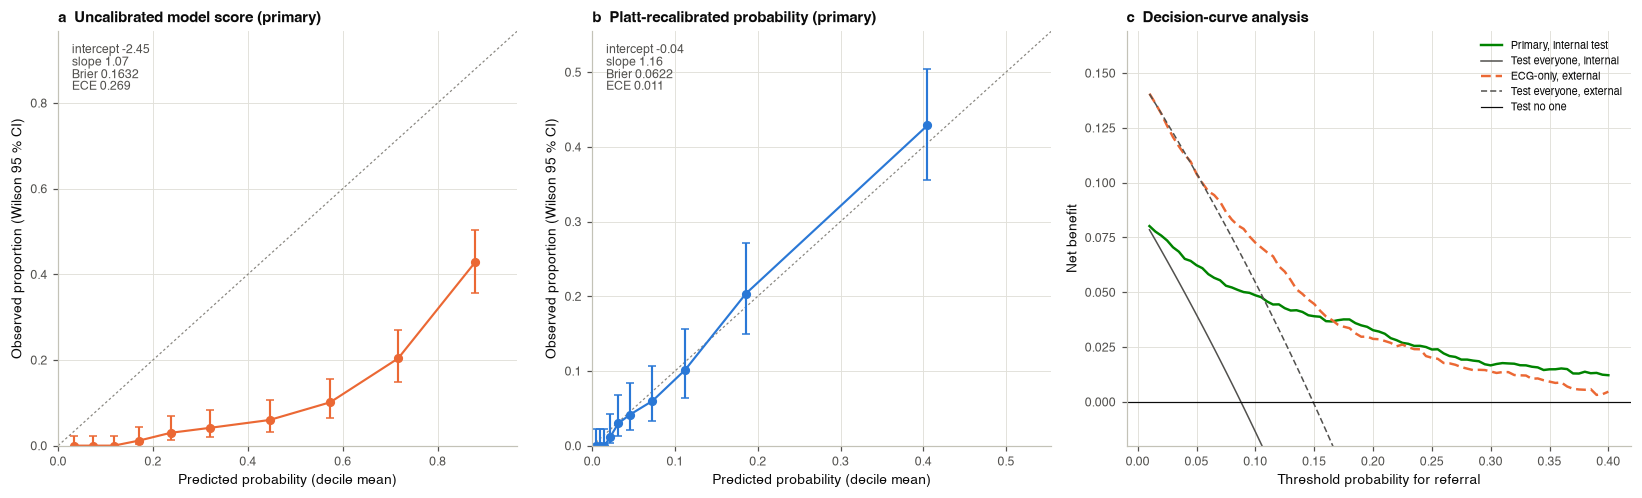

In [25]:
cal = {"uncalibrated score": S.calibration_metrics(y["test"], p_test), "Platt-recalibrated": S.calibration_metrics(y["test"], pc_test)}
cal_tab = save_table(pd.DataFrame(cal).T, "table10_calibration_internal_test")
display(cal_tab.round(4))
p_ext_eo, pc_ext_eo = eo["ext"], eo["platt"].transform(eo["ext"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1, 1, 1.1]})
for ax, (name, pp), col in zip(axes[:2], [("Uncalibrated model score", p_test), ("Platt-recalibrated probability", pc_test)], [C.SERIES[1], C.SERIES[0]]):
    cc = S.calibration_curve_ci(y["test"], pp, n_bins=10)
    lim = max(cc.hi.max(), cc.p_mean.max()) * 1.1
    ax.plot([0, lim], [0, lim], color=C.INK["muted"], lw=0.8, ls=(0, (2, 2)))
    ax.errorbar(cc.p_mean, cc.obs, yerr=[cc.obs - cc.lo, cc.hi - cc.obs], fmt="o-", color=col, ms=5, capsize=2.5, lw=1.4)
    m_ = S.calibration_metrics(y["test"], pp)
    ax.text(0.03, 0.97, f"intercept {m_['calibration_intercept']:+.2f}\nslope {m_['calibration_slope']:.2f}\nBrier {m_['Brier']:.4f}\nECE {m_['ECE']:.3f}",
            transform=ax.transAxes, va="top", fontsize=8, color=C.INK["secondary"])
    ax.set(xlim=(0, lim), ylim=(0, lim), xlabel="Predicted probability (decile mean)", ylabel="Observed proportion (Wilson 95 % CI)")
    ax.set_title(("a  " if ax is axes[0] else "b  ") + name + " (primary)", loc="left")
ax = axes[2]
grid = np.linspace(0.01, 0.40, 79)
dca_i = S.decision_curve(y["test"], pc_test, grid)
dca_e = S.decision_curve(y["ext"], pc_ext_eo, grid)
ax.plot(dca_i.threshold, dca_i.net_benefit, color=ROLE_COLORS["primary"], label="Primary, internal test")
ax.plot(dca_i.threshold, dca_i.treat_all, color=C.INK["secondary"], lw=1, label="Test everyone, internal")
ax.plot(dca_e.threshold, dca_e.net_benefit, color=ROLE_COLORS["ecg_only"], ls=(0, (4, 2)), label="ECG-only, external")
ax.plot(dca_e.threshold, dca_e.treat_all, color=C.INK["secondary"], lw=1, ls=(0, (4, 2)), label="Test everyone, external")
ax.axhline(0, color=C.INK["primary"], lw=0.8, label="Test no one")
ax.set(ylim=(-0.02, max(dca_i.net_benefit.max(), dca_e.net_benefit.max(), y["ext"].mean()) + 0.02),
       xlabel="Threshold probability for referral", ylabel="Net benefit")
ax.legend(fontsize=7); ax.set_title("c  Decision-curve analysis", loc="left")
fig.tight_layout()
P.savefig(fig, "fig08_calibration_dca", data=pd.concat([dca_i.assign(cohort="internal, primary"), dca_e.assign(cohort="external, ECG-only")]))
plt.show()

n  share of people % observed prediabetes/diabetes % (95 % CI)  share of all cases %
model and cohort        tier                                                                                             
Primary, internal test  Low        967               57.7                             1.2 (0.7–2.2)                   8.2
                        Elevated   226               13.5                            6.2 (3.7–10.1)                   9.5
                        High       483               28.8                          25.1 (21.4–29.1)                  82.3
Fallback, internal test Low        937               55.9                             1.3 (0.7–2.2)                   8.2
                        Elevated   227               13.5                             5.7 (3.4–9.6)                   8.8
                        High       512               30.5                          23.8 (20.3–27.7)                  83.0
ECG-only, internal test Low        783               46.7                             1.5 (0.9–2.7)                   8.2
                        Elevated   265               15.8                             4.2 (2.3–7.3)                   7.5
                        High       628               37.5                          19.7 (16.8–23.0)                  84.4
ECG-only, external      Low       1042               42.4                             4.3 (3.2–5.7)                  12.3
                        Elevated   416               16.9                           12.3 (9.4–15.8)                  13.9
                        High       998               40.6                          27.1 (24.4–29.9)                  73.8

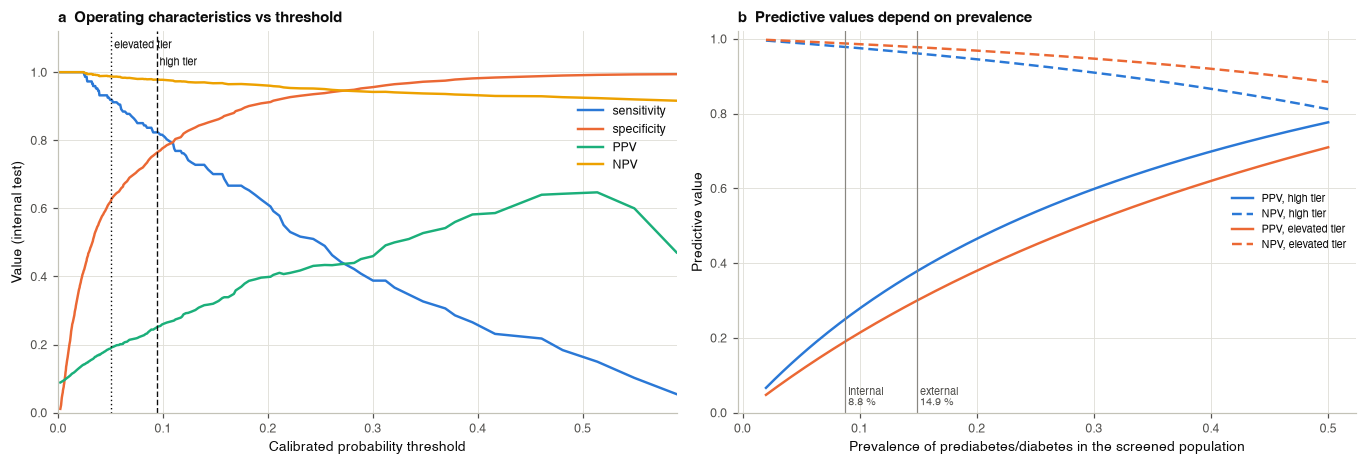

In [26]:
def tier_rows(score, info, yy, label):
    t = tier_of(score, info)
    out = []
    for tier in ["Low", "Elevated", "High"]:
        m = t == tier
        p_, lo, hi = wilson(yy[m].sum(), m.sum())
        out.append({"model and cohort": label, "tier": tier, "n": int(m.sum()), "share of people %": 100 * m.mean(),
                    "observed prediabetes/diabetes % (95 % CI)": f"{100 * p_:.1f} ({100 * lo:.1f}–{100 * hi:.1f})" if m.any() else "—",
                    "share of all cases %": 100 * yy[m].sum() / yy.sum()})
    return out


tier_tab = save_table(pd.DataFrame(tier_rows(p_test, pri, y["test"], "Primary, internal test")
                                   + tier_rows(fb["test"], fb, y["test"], "Fallback, internal test")
                                   + tier_rows(eo["test"], eo, y["test"], "ECG-only, internal test")
                                   + tier_rows(eo["ext"], eo, y["ext"], "ECG-only, external")).set_index(["model and cohort", "tier"]),
                      "table11_risk_tiers")
display(tier_tab.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))
ax = axes[0]
ths = np.quantile(pc_test, np.linspace(0.01, 0.99, 200))
sw = pd.DataFrame([{"threshold": t, **S.threshold_metrics(y["test"], pc_test, t)} for t in ths])
for m_, col in zip(["sensitivity", "specificity", "PPV", "NPV"], C.SERIES[:4]):
    ax.plot(sw.threshold, sw[m_], color=col, label=m_)
for k, ls, lab, yt in [("youden", (0, (4, 2)), " high tier", 1.02), ("sens90", (0, (1, 2)), " elevated tier", 1.07)]:
    xv = pri["platt"].transform(np.array([THR[k]]))[0]
    ax.axvline(xv, color=C.INK["primary"], lw=0.9, ls=ls)
    ax.text(xv, yt, lab, fontsize=7, color=C.INK["primary"])
ax.set(xlabel="Calibrated probability threshold", ylabel="Value (internal test)", ylim=(0, 1.12), xlim=(0, np.quantile(pc_test, 0.99)))
ax.legend(loc="center right", bbox_to_anchor=(1.0, 0.72)); ax.set_title("a  Operating characteristics vs threshold", loc="left")
ax = axes[1]
prev = np.linspace(0.02, 0.5, 200)
for k, col in [("youden", C.SERIES[0]), ("sens90", C.SERIES[1])]:
    se, sp = summ[k].loc["sensitivity", "estimate"], summ[k].loc["specificity", "estimate"]
    ppv, npv = S.ppv_npv_at_prevalence(se, sp, prev)
    lab = "high tier" if k == "youden" else "elevated tier"
    ax.plot(prev, ppv, color=col, label=f"PPV, {lab}")
    ax.plot(prev, npv, color=col, ls=(0, (4, 2)), label=f"NPV, {lab}")
for pv, name in [(y["test"].mean(), "internal"), (y["ext"].mean(), "external")]:
    ax.axvline(pv, color=C.INK["muted"], lw=0.8)
    ax.text(pv, 0.02, f" {name}\n {100 * pv:.1f} %", fontsize=7, color=C.INK["secondary"])
ax.set(xlabel="Prevalence of prediabetes/diabetes in the screened population", ylabel="Predictive value", ylim=(0, 1.02))
ax.legend(loc="center right", fontsize=7); ax.set_title("b  Predictive values depend on prevalence", loc="left")
fig.tight_layout()
P.savefig(fig, "fig09_threshold_prevalence", data=sw)
plt.show()

**Interpretation (Section 9): internal test.**
- **Discrimination.** The primary model reaches an internal-test AUROC of **0.878 (0.853–0.903)**. It is significantly better than:
  - the published DiaCardia lead-I model: +0.034, P = 0.004;
  - LightGBM on the published NeuroKit2 features: +0.035, P = 0.002;
  - age, sex and BMI alone: +0.026, P = 0.0001;
  - the ECG-only model: +0.033, P = 0.004.

  The gain-invariant fallback is equivalent (+0.003, P = 0.25). As in Section 4, the test AUROC is higher than the CV AUROC (0.845) because the test set is better separated.
- **Operating points** (Table 7):
  - **High tier:** sensitivity 82.3 % (76.2–88.5), specificity 76.3 % (74.2–78.5), PPV 25.1 %, NPV 97.8 %.
  - **Elevated or high:** sensitivity 91.8 % (87.2–96.0), specificity 62.5 %, NPV 98.8 %.

  The test values match what the development OOF predictions led us to expect, so the thresholds transfer.
- **Does the ECG add information to the profile?** Yes. Adding the ECG to age, sex and BMI gives:
  - IDI +0.053 (+0.035 to +0.072);
  - category-free NRI +0.278 (+0.120 to +0.442), driven by events (+0.238).

  ECG-DiaNet (Mohsen & Shah) reports the same pattern: ECG plus clinical risk factors beats either source alone.
- **Calibration.**
  - After Platt recalibration: intercept −0.04, slope 1.16, Brier 0.062, ECE 0.011.
  - The uncalibrated, class-weighted score would overstate risk four-fold (mean 0.36 vs 0.09 observed).
  - A slope slightly above 1 means the predictions are slightly *under*-dispersed on this better-separated test set, not over-fitted (over-fitting gives slopes < 1).
- **Risk tiers in practice** (Table 11):

  | Tier | Share of people | Observed prediabetes/diabetes | Share of all cases |
  |---|---|---|---|
  | Low | 57.7 % | 1.2 % | 8.2 % |
  | Elevated | 13.5 % | 6.2 % | 9.5 % |
  | High | 28.8 % | 25.1 % | 82.3 % |

  The tiers separate risk by a factor of about 20.
- **Clinical utility.** The decision curve shows positive net benefit over both "test everyone" and "test no one" at every referral threshold from 1 % to 40 %.
- **Predictive values.** PPV depends on prevalence. At the 8.8 % prevalence of a Japanese check-up population, a positive screen means "get a blood test", not "you have diabetes". In higher-prevalence settings (older adults, ADA criteria) PPV rises (Fig. 9b).

## 10. External validation (different hospital, ECG vendor and year)
The external cohort has no age, sex, BMI or blood pressure. Only the **ECG-only** model can therefore be validated externally, through the identical simulated device chain. This tests the part of the system that is new: whether the ECG signal transports.

Thresholds and calibration are those fixed on internal development data.

In [27]:
summ_eo = {coh: {k: S.summarize(yy, sc, eo["thr"][k], p_prob=eo["platt"].transform(sc), groups=gg, n_boot=RUN["n_boot"])
                 for k in ("youden", "sens90")}
           for coh, yy, sc, gg in [("internal", y["test"], eo["test"], g["test"]), ("external", y["ext"], eo["ext"], g["ext"])]}
tab12 = pd.DataFrame({
    "Internal test, high tier": [S.fmt_ci(summ_eo["internal"]["youden"].loc[m], pct=m in PCT) for m in METRICS],
    "External, high tier": [S.fmt_ci(summ_eo["external"]["youden"].loc[m], pct=m in PCT) for m in METRICS],
    "Internal test, elevated or high": [S.fmt_ci(summ_eo["internal"]["sens90"].loc[m], pct=m in PCT) for m in METRICS],
    "External, elevated or high": [S.fmt_ci(summ_eo["external"]["sens90"].loc[m], pct=m in PCT) for m in METRICS],
}, index=[m + (" %" if m in PCT else "") for m in METRICS])
save_table(tab12, "table12_external_validation_ecg_only")
d_ext, p_ext_delong = S.delong_test(y["ext"], eo["ext"], pub_pred["ext"])
d_ext2, p_ext_delong2 = S.delong_test(y["ext"], eo["ext"], nk2_lgbm["ext"])
cal_ext = S.calibration_metrics(y["ext"], pc_ext_eo)
display(tab12)
print(f"External: ECG-only vs published DiaCardia lead I: ΔAUROC {d_ext:+.3f}, DeLong P = {p_ext_delong:.3f}")
print(f"External: ECG-only vs LightGBM on published NeuroKit2 features: ΔAUROC {d_ext2:+.3f}, DeLong P = {p_ext_delong2:.3f}")
print(f"External calibration (Platt from development): intercept {cal_ext['calibration_intercept']:+.3f}, slope {cal_ext['calibration_slope']:.3f}, "
      f"mean predicted {cal_ext['mean_predicted']:.3f} vs observed {cal_ext['observed_rate']:.3f}")

,"Internal test, high tier","External, high tier","Internal test, elevated or high","External, elevated or high"
AUROC,0.845 (0.813–0.878),0.757 (0.732–0.782),0.845 (0.813–0.878),0.757 (0.732–0.782)
AUPRC,0.390 (0.316–0.477),0.338 (0.296–0.386),0.390 (0.316–0.477),0.338 (0.296–0.386)
sensitivity %,84.4 (78.3–89.8),73.8 (69.1–78.2),91.8 (87.2–96.0),87.7 (84.1–91.0)
specificity %,67.0 (64.7–69.4),65.2 (63.0–67.3),50.4 (47.8–53.0),47.7 (45.5–49.9)
PPV %,19.7 (16.4–22.9),27.1 (24.2–29.8),15.1 (12.7–17.5),22.7 (20.4–24.9)
NPV %,97.8 (96.9–98.6),93.4 (92.1–94.6),98.5 (97.6–99.2),95.7 (94.4–96.9)
PLR,2.559 (2.315–2.833),2.118 (1.942–2.306),1.852 (1.728–1.985),1.677 (1.584–1.774)
NLR,0.233 (0.150–0.323),0.402 (0.333–0.475),0.162 (0.079–0.254),0.258 (0.187–0.332)
F1,0.320 (0.273–0.362),0.396 (0.362–0.428),0.260 (0.223–0.294),0.361 (0.330–0.389)
G-mean,0.752 (0.722–0.780),0.693 (0.669–0.717),0.681 (0.657–0.703),0.647 (0.627–0.666)


External: ECG-only vs published DiaCardia lead I: ΔAUROC +0.010, DeLong P = 0.059
External: ECG-only vs LightGBM on published NeuroKit2 features: ΔAUROC +0.011, DeLong P = 0.039
External calibration (Platt from development): intercept +0.550, slope 0.846, mean predicted 0.098 vs observed 0.149


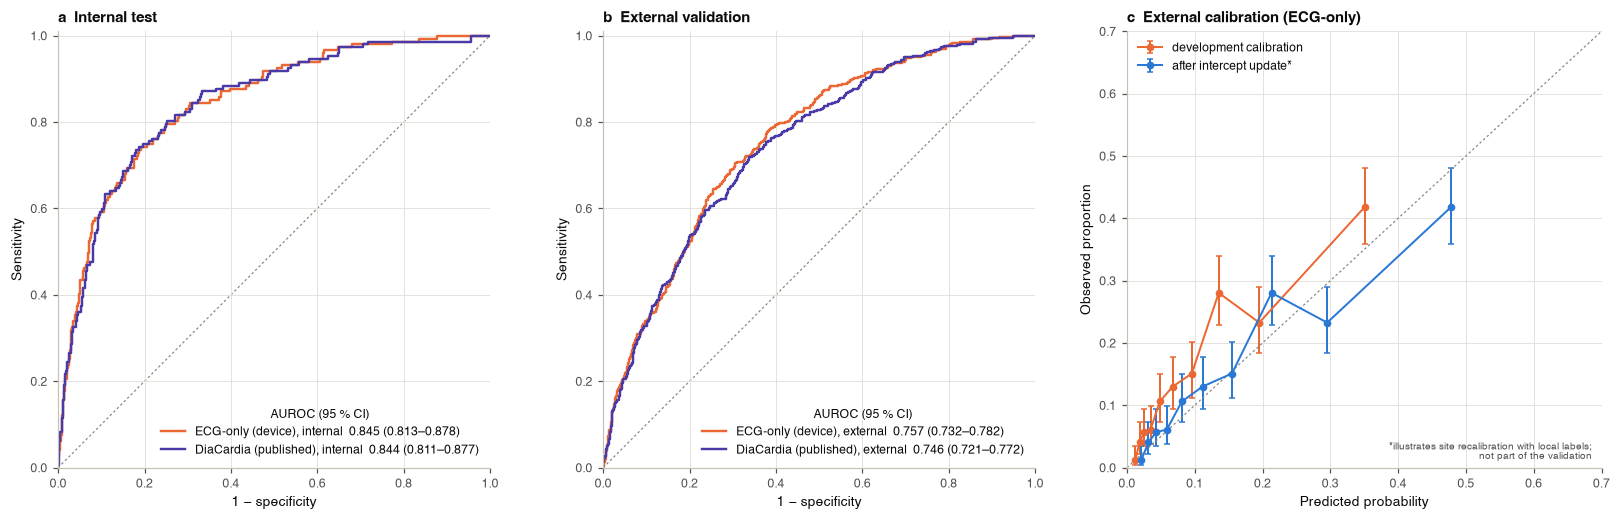

,AUROC,sensitivity %,specificity %,share flagged high %
external input,,,,
harmonised units (correct),0.757,73.770,65.167,40.635
unharmonised: 4× amplitude error,0.720,81.421,46.555,57.614


In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
P.roc_panel(axes[0], [("ECG-only (device), internal", y["test"], eo["test"], ROLE_COLORS["ecg_only"]),
                      ("DiaCardia (published), internal", y["test"], pub_pred["test"], C.MODEL_COLORS["DiaCardia (published)"])],
            "a  Internal test")
d_e = P.roc_panel(axes[1], [("ECG-only (device), external", y["ext"], eo["ext"], ROLE_COLORS["ecg_only"]),
                            ("DiaCardia (published), external", y["ext"], pub_pred["ext"], C.MODEL_COLORS["DiaCardia (published)"])],
                  "b  External validation")
ax = axes[2]
shift = cal_ext["calibration_intercept"]
upd = 1 / (1 + np.exp(-(np.log(pc_ext_eo / (1 - pc_ext_eo)) + shift)))
for name, pp, col in [("development calibration", pc_ext_eo, C.SERIES[1]), ("after intercept update*", upd, C.SERIES[0])]:
    cc = S.calibration_curve_ci(y["ext"], pp, n_bins=10)
    ax.errorbar(cc.p_mean, cc.obs, yerr=[cc.obs - cc.lo, cc.hi - cc.obs], fmt="o-", color=col, ms=4, capsize=2, lw=1.3, label=name)
lim = 0.7
ax.plot([0, lim], [0, lim], color=C.INK["muted"], lw=0.8, ls=(0, (2, 2)))
ax.set(xlim=(0, lim), ylim=(0, lim), xlabel="Predicted probability", ylabel="Observed proportion")
ax.legend(loc="upper left"); ax.set_title("c  External calibration (ECG-only)", loc="left")
ax.text(0.98, 0.02, "*illustrates site recalibration with local labels;\n not part of the validation", transform=ax.transAxes,
        ha="right", fontsize=6.5, color=C.INK["secondary"])
fig.tight_layout()
P.savefig(fig, "fig10_external_validation", data=d_e)
plt.show()

# Natural experiment: the same external ECGs WITHOUT unit harmonisation = a 4x amplitude error at the ADC
EX_raw4 = edge_table(raw_ext, ext.index, f"ext_{DEV_COND}_unharmonised", uv=C.UV_PER_LSB, **CONDITIONS[DEV_COND])
rows = []
for name, F_ in [("harmonised units (correct)", FX), ("unharmonised: 4× amplitude error", EX_raw4)]:
    pe = eo["model"].predict_proba(F_.loc[idx["ext"], eo["cols"]].to_numpy(dtype=float))[:, 1]
    tm = S.threshold_metrics(y["ext"], pe, eo["thr"]["youden"])
    rows.append({"external input": name, "AUROC": roc_auc_score(y["ext"], pe), "sensitivity %": 100 * tm["sensitivity"],
                 "specificity %": 100 * tm["specificity"], "share flagged high %": 100 * np.mean(pe >= eo["thr"]["youden"])})
nat = save_table(pd.DataFrame(rows).set_index("external input"), "table12b_external_unit_natural_experiment")
nat.round(3)

**Interpretation (Section 10): external validation.**
- **The ECG signal transports.** The ECG-only model (compact LightGBM) reaches an external AUROC of **0.757 (0.732–0.782)**:
  - vs the published DiaCardia lead-I model on the same records: +0.010, P = 0.059;
  - vs LightGBM on the published NeuroKit2 features: +0.011, P = 0.039.

  This holds for a different hospital, ECG vendor and year, with features computed through the simulated ESP32-S3 chain. The drop from the internal 0.845 is the expected transportability loss.
- **Fixed thresholds.**
  - High tier: sensitivity 73.8 %, specificity 65.2 %.
  - Elevated or high: 87.7 % and 47.7 %.
  - PPV rises to 27.1 % because external prevalence is higher (14.9 %).
- **Calibration.** The model under-estimates external risk: intercept +0.55, slope 0.85, mean predicted 9.8 % vs 14.9 % observed. This is the expected behaviour when a model moves to a population with higher prevalence. It is why a deployment in Taiwan needs **local recalibration**: an intercept update from a small labelled sample (panel c). The decision curve stays above "test everyone" and "test no one" at referral thresholds of 5–40 %; below 5 %, testing everyone is equally good.
- **Natural experiment.** Feeding the external ECGs in the wrong amplitude unit is exactly what an uncalibrated AD8232 gain does (a 4× gain error):
  - AUROC 0.757 → 0.720;
  - specificity 65.2 % → 46.6 %;
  - share flagged high 41 % → 58 %.

  For the ECG-only model, amplitude calibration matters. The firmware therefore runs the ECG-only model only with a calibrated gain.

## 11. Clinical sub-analyses
1. **Does the model detect *pre*diabetes, or mainly overt diabetes?** We report the detection rate by glycaemic stratum, and the AUROC for prediabetes range vs normoglycaemia with diabetes excluded.
2. **ADA definition** (FPG ≥ 100 mg/dL or HbA1c ≥ 5.7 %), the definition used in Taiwan and the US. It is applied without retraining.
3. **Subgroups:** sex, age band and BMI category.
4. **SQI-passing recordings only**: what the device would actually classify.

In [29]:
def stratum(df):
    tx = df.dm_under_treatment.astype(bool)
    s = pd.Series("Normoglycaemia", index=df.index)
    s[df.prediabetes_only] = "Prediabetes range"
    s[df.diabetes_range & ~tx] = "Diabetes range, untreated"
    s[tx] = "On diabetes treatment"
    return s


STRATA = ["Normoglycaemia", "Prediabetes range", "Diabetes range, untreated", "On diabetes treatment"]
SUBSETS = [("Primary", pri, "Internal test", test, pri["test"], y["test"], EI),
           ("ECG-only", eo, "Internal test", test, eo["test"], y["test"], EI),
           ("ECG-only", eo, "External", ext, eo["ext"], y["ext"], EX)]
rows = []
for mname, info, coh, df, score, yy, E_ in SUBSETS:
    s = stratum(df).values
    lo_t, hi_t = tiers(info)
    for stt in STRATA:
        m = s == stt
        r = {"model": mname, "cohort": coh, "stratum": stt, "n": int(m.sum())}
        for lab, t in [("high tier", hi_t), ("elevated or high", lo_t)]:
            p_, lo, hi = wilson((score[m] >= t).sum(), m.sum())
            r[f"flagged % ({lab})"] = f"{100 * p_:.1f} ({100 * lo:.1f}–{100 * hi:.1f})"
        rows.append(r)
strata_tab = save_table(pd.DataFrame(rows).set_index(["model", "cohort", "stratum"]), "table13_detection_by_stratum")
display(strata_tab)

rows = []
for mname, info, coh, df, score, yy, E_ in SUBSETS:
    m = (~df[C.LABEL] | df.prediabetes_only).values
    ada = df.label_ada.values.astype(int)
    ok = E_.loc[df.index, "sqi_ok"].values.astype(bool)
    rows.append({"model": mname, "cohort": coh,
                 "AUROC prediabetes range vs normoglycaemia": ci_str(S.auc_delong_ci(df.prediabetes_only.values[m].astype(int), score[m])),
                 "n prediabetes range": int(df.prediabetes_only.sum()),
                 "AUROC vs ADA definition": ci_str(S.auc_delong_ci(ada, score)), "ADA prevalence %": 100 * ada.mean(),
                 "AUROC SQI-pass only": ci_str(S.auc_delong_ci(yy[ok], score[ok])), "SQI pass %": 100 * ok.mean()})
sens_tab = save_table(pd.DataFrame(rows).set_index(["model", "cohort"]), "table14_prediabetes_ada_sqi")
sens_tab

n flagged % (high tier) flagged % (elevated or high)
model    cohort        stratum                                                                           
Primary  Internal test Normoglycaemia             1529      23.7 (21.6–25.9)             37.5 (35.1–40.0)
                       Prediabetes range            69      72.5 (61.0–81.6)             85.5 (75.3–91.9)
                       Diabetes range, untreated    32      87.5 (71.9–95.0)             96.9 (84.3–99.4)
                       On diabetes treatment        46      93.5 (82.5–97.8)             97.8 (88.7–99.6)
ECG-only Internal test Normoglycaemia             1529      33.0 (30.7–35.4)             49.6 (47.1–52.1)
                       Prediabetes range            69      73.9 (62.5–82.8)             84.1 (73.7–90.9)
                       Diabetes range, untreated    32      87.5 (71.9–95.0)             96.9 (84.3–99.4)
                       On diabetes treatment        46      97.8 (88.7–99.6)           100.0 (92.3–100.0)
         External      Normoglycaemia             2090      34.8 (32.8–36.9)             52.3 (50.2–54.4)
                       Prediabetes range           200      69.0 (62.3–75.0)             84.5 (78.8–88.9)
                       Diabetes range, untreated    59      88.1 (77.5–94.1)             96.6 (88.5–99.1)
                       On diabetes treatment       107      74.8 (65.8–82.0)             88.8 (81.4–93.5)

AUROC prediabetes range vs normoglycaemia  n prediabetes range AUROC vs ADA definition  ADA prevalence %  AUROC SQI-pass only  SQI pass %
model    cohort                                                                                                                                                 
Primary  Internal test                       0.837 (0.795–0.879)                   69     0.818 (0.794–0.842)            22.613  0.879 (0.854–0.904)      99.344
ECG-only Internal test                       0.796 (0.739–0.853)                   69     0.759 (0.732–0.787)            22.613  0.846 (0.813–0.878)      99.344
         External                            0.727 (0.693–0.761)                  200     0.732 (0.711–0.752)            33.876  0.756 (0.731–0.781)      97.353

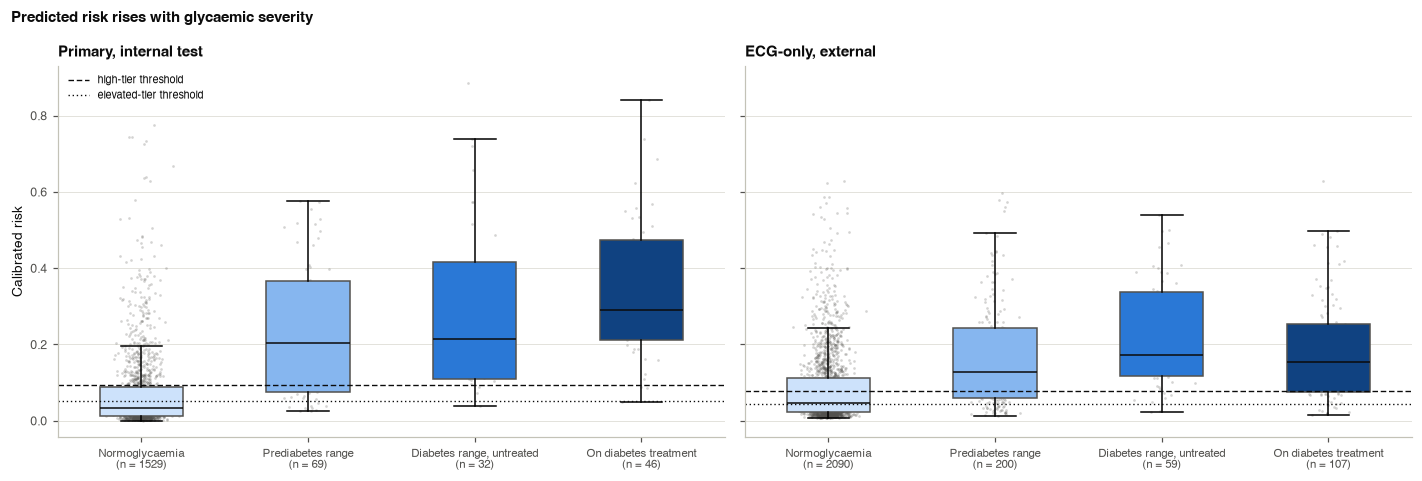

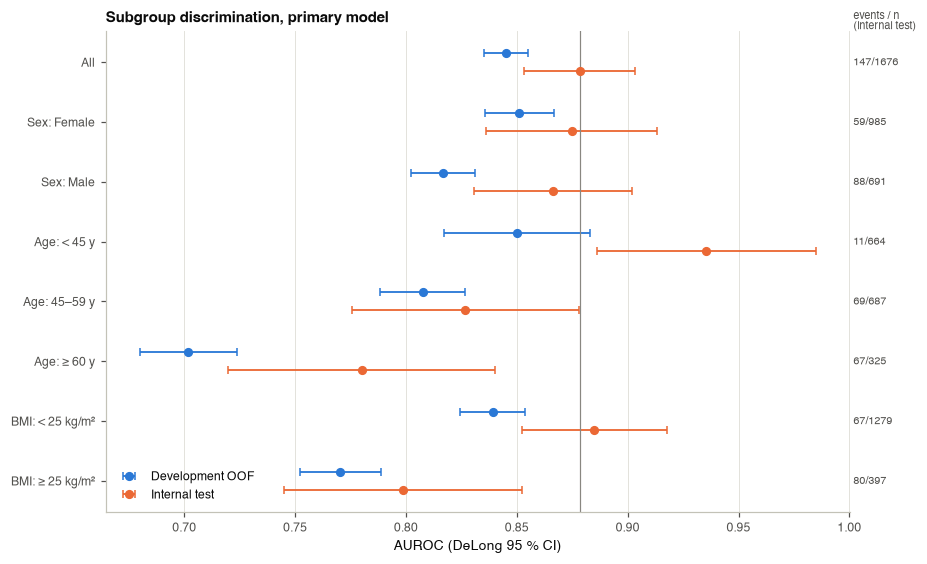

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, (title, df, score, info) in zip(axes, [("Primary, internal test", test, pc_test, pri),
                                                ("ECG-only, external", ext, pc_ext_eo, eo)]):
    s = stratum(df).values
    vals = [score[s == stt] for stt in STRATA]
    bp = ax.boxplot(vals, widths=0.5, showfliers=False, patch_artist=True, medianprops=dict(color=C.INK["primary"]))
    for patch, col in zip(bp["boxes"], ["#cde2fb", "#86b6ef", "#2a78d6", "#104281"]):
        patch.set(facecolor=col, edgecolor=C.INK["secondary"])
    for i, v in enumerate(vals, 1):
        ax.scatter(np.random.default_rng(i).normal(i, 0.06, len(v)), v, s=3, alpha=0.25, color=C.INK["secondary"], lw=0, rasterized=True)
    lo_t, hi_t = tiers(info)
    for t, ls, lab in [(hi_t, (0, (4, 2)), "high-tier threshold"), (lo_t, (0, (1, 2)), "elevated-tier threshold")]:
        ax.axhline(info["platt"].transform(np.array([t]))[0], color=C.INK["primary"], lw=0.9, ls=ls, label=lab)
    ax.set_xticks(range(1, 5), [f"{stt}\n(n = {(s == stt).sum()})" for stt in STRATA], fontsize=7.5)
    ax.grid(axis="x", visible=False); ax.set_title(title, loc="left")
axes[0].set_ylabel("Calibrated risk"); axes[0].legend(loc="upper left", fontsize=7)
fig.suptitle("Predicted risk rises with glycaemic severity", x=0.01, ha="left", fontsize=10, fontweight="bold")
fig.tight_layout()
P.savefig(fig, "fig11_risk_by_glycaemic_stratum")
plt.show()


def subgroup_rows(df, score, yy, label, thr):
    out = []
    defs = [("Sex", "Female", df.male_sex.values == 0), ("Sex", "Male", df.male_sex.values == 1),
            ("Age", "< 45 y", df.age.values < 45), ("Age", "45–59 y", (df.age.values >= 45) & (df.age.values < 60)),
            ("Age", "≥ 60 y", df.age.values >= 60), ("BMI", "< 25 kg/m²", df.BMI.values < 25), ("BMI", "≥ 25 kg/m²", df.BMI.values >= 25)]
    for fam_, name, m in [("All", "All", np.ones(len(df), bool))] + defs:
        if yy[m].sum() < 5 or yy[m].sum() == m.sum():
            continue
        a = S.auc_delong_ci(yy[m], score[m])
        tm = S.threshold_metrics(yy[m], score[m], thr)
        out.append({"set": label, "family": fam_, "subgroup": name, "n": int(m.sum()), "events": int(yy[m].sum()),
                    "AUROC": a[0], "lo": a[1], "hi": a[2], "sensitivity": tm["sensitivity"], "specificity": tm["specificity"]})
    return out


sg = pd.DataFrame(subgroup_rows(test, p_test, y["test"], "Internal test", THR["youden"])
                  + subgroup_rows(dev, pri["oof"], y["dev"], "Development OOF", THR["youden"]))
save_table(sg, "table15_subgroups", index=False)
fig, ax = plt.subplots(figsize=(8.5, 5.2))
sg["label"] = np.where(sg.family == "All", sg.subgroup, sg.family + ": " + sg.subgroup)
labels = list(dict.fromkeys(sg.label))
ymap = dict(zip(labels, np.arange(len(labels))[::-1]))
for off, (sname, col) in zip([0.15, -0.15], [("Development OOF", C.SERIES[0]), ("Internal test", C.SERIES[1])]):
    d = sg[sg.set == sname]
    ax.errorbar(d.AUROC, d.label.map(ymap).values + off, xerr=[d.AUROC - d.lo, d.hi - d.AUROC], fmt="o", color=col, ms=5,
                capsize=2.5, lw=1.2, label=sname)
    if sname == "Internal test":
        for _, r_ in d.iterrows():
            ax.text(1.005, ymap[r_.label], f"{r_.events}/{r_.n}", va="center", fontsize=7, color=C.INK["secondary"],
                    transform=ax.get_yaxis_transform())
ax.axvline(sg[(sg.set == "Internal test") & (sg.family == "All")].AUROC.iloc[0], color=C.INK["muted"], lw=0.8)
ax.set_yticks([ymap[l] for l in labels], labels); ax.set_xlabel("AUROC (DeLong 95 % CI)"); ax.grid(axis="y", visible=False)
ax.legend(loc="lower left"); ax.set_title("Subgroup discrimination, primary model", loc="left")
ax.text(1.005, 1.0, "events / n\n(internal test)", transform=ax.transAxes, fontsize=7, va="bottom", color=C.INK["secondary"])
fig.tight_layout()
P.savefig(fig, "fig12_subgroup_forest", data=sg)
plt.show()

**Interpretation (Section 11).**
- **The device detects the *pre*diabetic stage, not only overt diabetes** (Table 13). The primary model flags as high risk (internal test):

  | Group | High tier | Elevated or high |
  |---|---|---|
  | Normoglycaemia (false positives) | 23.7 % | — |
  | Prediabetes range | 72.5 % (61.0–81.6) | 85.5 % |
  | Untreated diabetes range | 87.5 % | — |
  | On treatment | 93.5 % | — |

  Externally, the ECG-only model flags 69.0 % of the prediabetes range as high risk (84.5 % elevated or high).
- **Headline numbers for "prediabetes detection".** AUROC for prediabetes range vs normoglycaemia, with diabetes excluded:
  - primary: **0.837 (0.795–0.879)**;
  - ECG-only: 0.783 internal and 0.727 (0.693–0.761) external.
- **ADA definition** (not used for training; prevalence 22.6 % internal, 33.9 % external): AUROC 0.818 for the primary and 0.707 for the ECG-only model externally. Milder hyperglycaemia is a harder target. Retraining with ADA labels on a Taiwanese cohort is a natural next step.
- **SQI-passing recordings only:** AUROC unchanged (0.879).
- **Subgroups.**

  | Subgroup | AUROC | Specificity at the high tier |
  |---|---|---|
  | Women / men | 0.875 / 0.866 | — |
  | < 45 y | 0.936 | — |
  | 45–59 y | 0.827 | — |
  | ≥ 60 y | 0.780 | 27 % |
  | BMI < 25 | 0.885 | — |
  | BMI ≥ 25 | 0.799 | 40 % |

  In adults ≥ 60 y and with BMI ≥ 25, the model flags most people because age and BMI raise the baseline risk. These groups are already recommended for glucose testing by the ADA Standards of Care. The device adds most where conventional risk-factor screening is weakest: younger, lean adults.

## 12. Hardware robustness: what can go wrong on a real AD8232 + ESP32-S3?
Each test changes only the *test-time* signal path. The deployed models and thresholds stay fixed unless stated otherwise.

| Test | What is varied | Why |
|---|---|---|
| (a) Acquisition chain | clinical ECG vs AD8232 filters vs full ESP32-S3 ADC, with and without retraining | the cost of the cheap hardware |
| (b) ADC noise | SD 0–20 mV at the ADC pin (3 mV in training) | Wi-Fi bursts, supply ripple, a noisy USB supply |
| (c) Body noise | EMG-like and electrode-motion noise at in-band SNR 30 → 0 dB, plus baseline wander and 60 Hz mains (Taiwan); with the SQI gate | real-world wearable recordings |
| (d) Amplitude gain | 0.5–2 × the assumed gain 1100 | an uncalibrated AD8232 board or a different electrode placement |
| (e) Blood-pressure error | SD 0–20 mmHg, only if BP is a primary input | cuffless BP |

In [31]:
def frame_int(F_ecg):
    return F_ecg[ef.EDGE_ALL + ef.SQI_FIELDS].join(pc[NONECG])


def scores(info, F):
    return info["model"].predict_proba(F.loc[:, info["cols"]].to_numpy(dtype=float))[:, 1]


rob_acq = []
for cond in CONDITIONS:
    Fi, Fe = frame_int(EDGE[("int", cond)]), EDGE[("ext", cond)]
    Xp = mats(pri["cols"], Fi, Fe)

    def _retrain(Xp=Xp):
        oof, _ = M.oof_predictions(pri["kind"], pri["params"], Xp["dev"], y["dev"], g["dev"], splits10)
        m = M.fit_final(pri["kind"], pri["params"], Xp["dev"], y["dev"], g["dev"])
        return {"oof_auc": roc_auc_score(y["dev"], oof), "test_auc": roc_auc_score(y["test"], m.predict_proba(Xp["test"])[:, 1])}

    r = cached(f"rob_acq_{cond}_{pri['key']}", _retrain)
    rob_acq.append({"condition": cond, "AD8232 filters": CONDITIONS[cond]["frontend"], "ESP32-S3 ADC": CONDITIONS[cond]["adc"] == "esp32s3",
                    "primary: CV AUROC, retrained": r["oof_auc"], "primary: test AUROC, retrained": r["test_auc"],
                    "primary: test AUROC, device model as is": roc_auc_score(y["test"], pri["model"].predict_proba(Xp["test"])[:, 1]),
                    "ECG-only: external AUROC, device model as is": roc_auc_score(y["ext"], scores(eo, Fe.loc[idx["ext"]]))})
rob_acq = save_table(pd.DataFrame(rob_acq).set_index("condition"), "table16a_robustness_acquisition")
display(rob_acq.round(3))


def perturbed(name, **kw):
    kw = {**CONDITIONS[DEV_COND], **kw}
    Ft = edge_table(raw_int[pos["test"]], idx["test"], f"int_test_{DEV_COND}_{name}", **kw)
    Fe = edge_table(raw_ext, idx["ext"], f"ext_{DEV_COND}_{name}", uv=C.UV_PER_LSB_EXTERNAL, **kw)
    return frame_int(Ft), Fe


t0 = time.time()
rows = []
for v in [0.0, 3.0, 6.0, 10.0, 20.0]:
    Ft, Fe = perturbed(f"adcnoise{v:g}", adc_noise_mv=v)
    pt = scores(pri, Ft)
    tm = S.threshold_metrics(y["test"], pt, THR["youden"])
    rows.append({"ADC noise SD at GPIO4 (mV)": v, "≈ µV at the electrodes": 1000 * v / C.AD8232_GAIN,
                 "primary: test AUROC": roc_auc_score(y["test"], pt), "primary: sensitivity": tm["sensitivity"],
                 "primary: specificity": tm["specificity"], "SQI pass %": 100 * Ft.sqi_ok.astype(bool).mean(),
                 "ECG-only: external AUROC": roc_auc_score(y["ext"], scores(eo, Fe))})
rob_adc = save_table(pd.DataFrame(rows), "table16b_robustness_adc_noise", index=False)

rows = []
for snr in [None, 30, 20, 15, 10, 5, 0]:
    Ft, Fe = perturbed("adcnoise3", adc_noise_mv=3.0) if snr is None else perturbed(f"snr{snr}", snr_db=snr)
    pt = scores(pri, Ft)
    ok = Ft.sqi_ok.to_numpy(dtype=bool)
    enough = y["test"][ok].sum() >= 20 and (1 - y["test"][ok]).sum() >= 20
    tm = S.threshold_metrics(y["test"][ok], pt[ok], THR["youden"]) if enough else {"sensitivity": np.nan, "specificity": np.nan}
    rows.append({"in-band SNR (dB)": "clean" if snr is None else snr, "primary: test AUROC (all)": roc_auc_score(y["test"], pt),
                 "primary: test AUROC (SQI-pass)": roc_auc_score(y["test"][ok], pt[ok]) if enough else np.nan,
                 "SQI pass %": 100 * ok.mean(), "sensitivity (SQI-pass)": tm["sensitivity"], "specificity (SQI-pass)": tm["specificity"],
                 "ECG-only: external AUROC (all)": roc_auc_score(y["ext"], scores(eo, Fe))})
rob_noise = save_table(pd.DataFrame(rows), "table16c_robustness_body_noise", index=False)

rows = []
for gain in [0.5, 0.7, 0.85, 0.9, 1.0, 1.1, 1.2, 1.4, 2.0]:
    Ft, Fe = perturbed(f"gain{gain}", gain=gain)
    for role in ("primary", "fallback"):
        f = final[role]
        pt = scores(f, Ft)
        tm = S.threshold_metrics(y["test"], pt, f["thr"]["youden"])
        rows.append({"gain": gain, "model": ROLE_LABEL[role], "test AUROC": roc_auc_score(y["test"], pt),
                     "sensitivity": tm["sensitivity"], "specificity": tm["specificity"],
                     "share flagged high %": 100 * np.mean(pt >= f["thr"]["youden"])})
rob_gain = save_table(pd.DataFrame(rows), "table16d_robustness_gain", index=False)

rob_bp = None
if any(c in pri["cols"] for c in C.BLOOD_PRESSURE):
    bp_i = [pri["cols"].index(c) for c in C.BLOOD_PRESSURE if c in pri["cols"]]
    rows = []
    for sd in BP_SDS:
        res = []
        for rep in range(20 if sd > 0 else 1):
            Xt = pri["X"]["test"].copy()
            if sd > 0:
                Xt[:, bp_i] += np.random.default_rng(rep).normal(0, sd, (len(Xt), len(bp_i)))
            pt = pri["model"].predict_proba(Xt)[:, 1]
            tm = S.threshold_metrics(y["test"], pt, THR["youden"])
            res.append((roc_auc_score(y["test"], pt), tm["sensitivity"], tm["specificity"]))
        a = np.mean(res, axis=0)
        rows.append({"BP error SD (mmHg)": sd, "test AUROC (mean of 20 draws)": a[0], "sensitivity": a[1], "specificity": a[2]})
    rob_bp = save_table(pd.DataFrame(rows), "table16e_robustness_bp_error", index=False)
print(f"perturbation analyses: {time.time() - t0:.0f} s")
display(rob_adc.round(3), rob_noise.round(3), rob_gain.round(3))
if rob_bp is not None:
    display(rob_bp.round(3))

,AD8232 filters,ESP32-S3 ADC,"primary: CV AUROC, retrained","primary: test AUROC, retrained","primary: test AUROC, device model as is","ECG-only: external AUROC, device model as is"
condition,,,,,,
clinical_500,False,False,0.845,0.877,0.877,0.760
ad8232_500,True,False,0.845,0.878,0.878,0.757
esp32s3_500,True,True,0.845,0.878,0.878,0.757


perturbation analyses: 0 s


,ADC noise SD at GPIO4 (mV),≈ µV at the electrodes,primary: test AUROC,primary: sensitivity,primary: specificity,SQI pass %,ECG-only: external AUROC
0,0.0,0.000,0.878,0.823,0.763,99.344,0.757
1,3.0,2.727,0.878,0.823,0.764,99.344,0.757
2,6.0,5.455,0.878,0.823,0.763,99.403,0.757
3,10.0,9.091,0.878,0.823,0.762,99.403,0.758
4,20.0,18.182,0.877,0.823,0.758,99.224,0.759


,in-band SNR (dB),primary: test AUROC (all),primary: test AUROC (SQI-pass),SQI pass %,sensitivity (SQI-pass),specificity (SQI-pass),ECG-only: external AUROC (all)
0,clean,0.878,0.879,99.344,0.823,0.765,0.757
1,30,0.878,0.878,99.403,0.823,0.761,0.757
2,20,0.877,0.878,99.403,0.823,0.757,0.755
3,15,0.877,0.877,99.224,0.830,0.747,0.754
4,10,0.875,0.875,98.687,0.830,0.729,0.753
5,5,0.876,0.868,89.200,0.824,0.716,0.748
6,0,0.855,NaN,0.895,NaN,NaN,0.729


,gain,model,test AUROC,sensitivity,specificity,share flagged high %
0,0.50,Primary,0.878,0.810,0.785,26.671
1,0.50,Fallback (gain-invariant),0.875,0.823,0.747,30.310
2,0.70,Primary,0.878,0.816,0.776,27.625
3,0.70,Fallback (gain-invariant),0.875,0.830,0.747,30.370
4,0.85,Primary,0.878,0.823,0.769,28.282
5,0.85,Fallback (gain-invariant),0.875,0.830,0.747,30.370
6,0.90,Primary,0.878,0.823,0.767,28.461
7,0.90,Fallback (gain-invariant),0.875,0.830,0.747,30.370
8,1.00,Primary,0.878,0.823,0.764,28.759
9,1.00,Fallback (gain-invariant),0.875,0.830,0.747,30.370


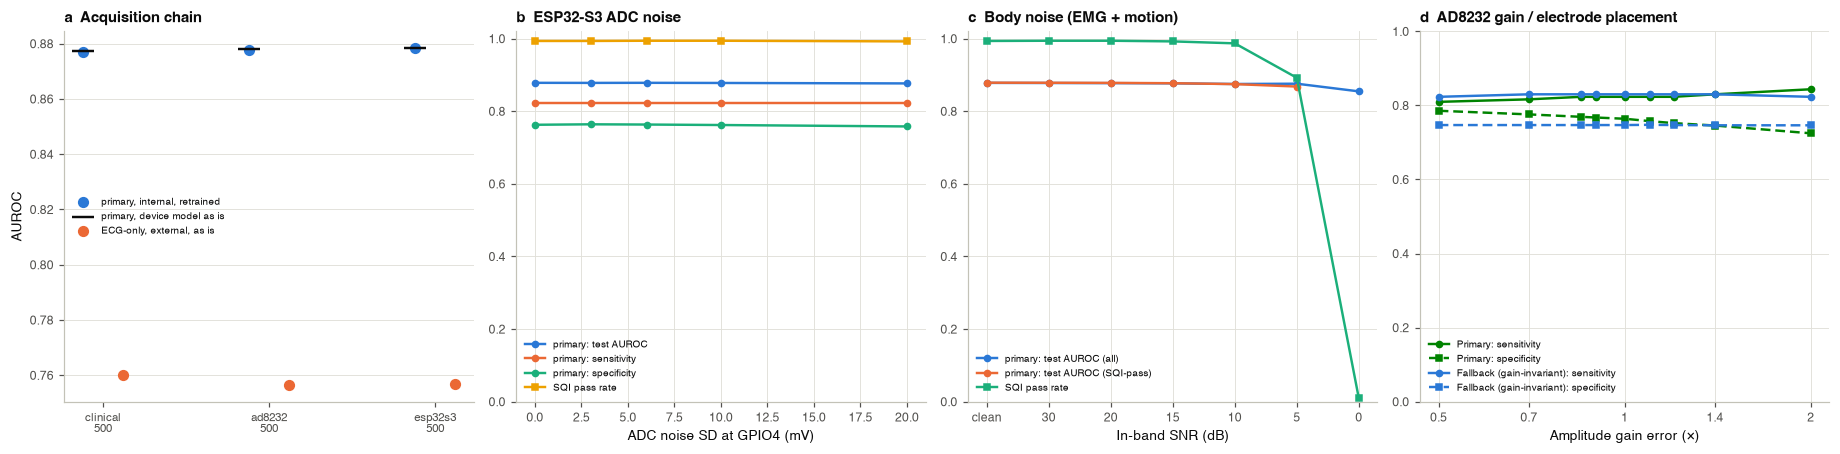

In [32]:
n_pan = 5 if rob_bp is not None else 4
fig, axes = plt.subplots(1, n_pan, figsize=(4.2 * n_pan, 4.2))
ax = axes[0]
xs = np.arange(len(rob_acq))
ax.scatter(xs - 0.12, rob_acq["primary: test AUROC, retrained"], color=C.SERIES[0], s=40, label="primary, internal, retrained", zorder=3)
ax.scatter(xs - 0.12, rob_acq["primary: test AUROC, device model as is"], marker="_", s=200, color=C.INK["primary"], label="primary, device model as is", zorder=4)
ax.scatter(xs + 0.12, rob_acq["ECG-only: external AUROC, device model as is"], color=C.SERIES[1], s=40, label="ECG-only, external, as is", zorder=3)
ax.set_xticks(xs, [c.replace("_", "\n") for c in rob_acq.index], fontsize=7.5); ax.grid(axis="x", visible=False)
ax.set_ylabel("AUROC"); ax.legend(fontsize=6.5, loc="center left"); ax.set_title("a  Acquisition chain", loc="left")
ax = axes[1]
for c, col in [("primary: test AUROC", C.SERIES[0]), ("primary: sensitivity", C.SERIES[1]), ("primary: specificity", C.SERIES[2])]:
    ax.plot(rob_adc["ADC noise SD at GPIO4 (mV)"], rob_adc[c], marker="o", ms=4, color=col, label=c)
ax.plot(rob_adc["ADC noise SD at GPIO4 (mV)"], rob_adc["SQI pass %"] / 100, marker="s", ms=4, color=C.SERIES[3], label="SQI pass rate")
ax.set(xlabel="ADC noise SD at GPIO4 (mV)", ylim=(0, 1.02)); ax.legend(fontsize=6.5, loc="lower left")
ax.set_title("b  ESP32-S3 ADC noise", loc="left")
ax = axes[2]
xn = np.arange(len(rob_noise))
for c, col in [("primary: test AUROC (all)", C.SERIES[0]), ("primary: test AUROC (SQI-pass)", C.SERIES[1])]:
    ax.plot(xn, rob_noise[c], marker="o", ms=4, color=col, label=c)
ax.plot(xn, rob_noise["SQI pass %"] / 100, marker="s", ms=4, color=C.SERIES[2], label="SQI pass rate")
ax.set_xticks(xn, rob_noise["in-band SNR (dB)"].astype(str)); ax.set(xlabel="In-band SNR (dB)", ylim=(0, 1.02))
ax.legend(fontsize=6.5, loc="lower left"); ax.set_title("c  Body noise (EMG + motion)", loc="left")
ax = axes[3]
for (name, d), col in zip(rob_gain.groupby("model", sort=False), [ROLE_COLORS["primary"], ROLE_COLORS["fallback"]]):
    ax.plot(d.gain, d.sensitivity, color=col, marker="o", ms=4, label=f"{name}: sensitivity")
    ax.plot(d.gain, d.specificity, color=col, marker="s", ms=4, ls=(0, (4, 2)), label=f"{name}: specificity")
ax.set_xscale("log", base=2); ax.set_xticks([0.5, 0.7, 1, 1.4, 2], ["0.5", "0.7", "1", "1.4", "2"])
ax.set(xlabel="Amplitude gain error (×)", ylim=(0, 1)); ax.legend(fontsize=6.5, loc="lower left")
ax.set_title("d  AD8232 gain / electrode placement", loc="left")
if rob_bp is not None:
    ax = axes[4]
    for c, col in [("test AUROC (mean of 20 draws)", C.SERIES[0]), ("sensitivity", C.SERIES[1]), ("specificity", C.SERIES[2])]:
        ax.plot(rob_bp["BP error SD (mmHg)"], rob_bp[c], marker="o", ms=4, color=col, label=c)
    ax.set(xlabel="Blood-pressure error SD (mmHg)", ylim=(0, 1)); ax.legend(fontsize=6.5, loc="lower left")
    ax.set_title("e  Cuffless BP error", loc="left")
fig.tight_layout()
P.savefig(fig, "fig13_hardware_robustness")
plt.show()

**Interpretation (Section 12): hardware requirements derived from the data.**
- **(a) The low-cost chain costs nothing.** Retrained test AUROC is 0.877 on the clinical ECG, 0.878 after the AD8232 filters and 0.878 after the ESP32-S3 ADC. Using the 500 Hz ESP32-S3 ADC directly, without an external ADC, is sufficient.
- **(b) ADC noise is not critical.** Up to 20 mV SD at GPIO4 (≈ 18 µV at the electrodes, about six times the assumed noise), the test AUROC is 0.877 and specificity changes by < 1 point.
- **(c) Body noise is handled by the quality gate.**
  - AUROC stays ≥ 0.875 down to 5 dB in-band SNR (EMG + electrode motion).
  - The SQI passes 98.7 % of recordings at 10 dB and 89 % at 5 dB. At 0 dB it passes < 1 %, and the device asks for a repeat instead of guessing.
  - Specificity drifts from 76.5 % to 72.9 % at 10 dB, as RR-variability features are inflated by noise. The median over three windows mitigates this.
- **(d) Amplitude gain matters only moderately for the primary model.**

  | Gain error | Sensitivity | Specificity |
  |---|---|---|
  | 0.5× | 81 % | 78.5 % |
  | 1× | 82 % | 76.4 % |
  | 2× | 84 % | 72.5 % |

  AUROC does not change. The gain-invariant fallback is immune by construction (83 % / 74.7 % at every gain) and almost as accurate. The ECG-only model is far more gain-sensitive (Section 10's natural experiment).
- **Recommendations:**
  1. Calibrate the AD8232 gain once with a 1 mV sine.
  2. Use the fallback until then (the firmware does this automatically).
  3. Place the electrodes on the wrists for true lead I.
  4. Record three 10-s windows and use the median.

  Blood pressure is not a model input, so its error does not affect the risk.

## 13. Explainability and physiological plausibility
The primary model's predictions on the internal test set are explained with SHAP values:
- exact TreeSHAP for tree models;
- a permutation explainer otherwise.

Importance is the share of the mean |SHAP| value, the convention of Koga *et al.* The shares are also grouped by input type, to show how much of the decision rests on the ECG versus the profile.

,share of mean |SHAP| (%)
"Profile (age, sex, BMI)",52.3
ECG: timing and heart-rate variability,28.1
ECG: amplitudes,17.2
ECG: T/R amplitude ratio,2.4


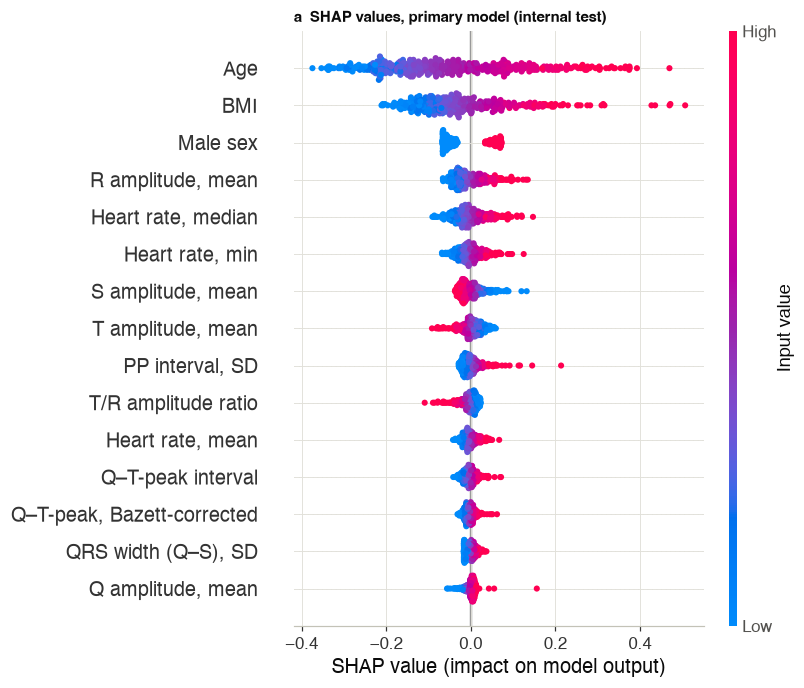

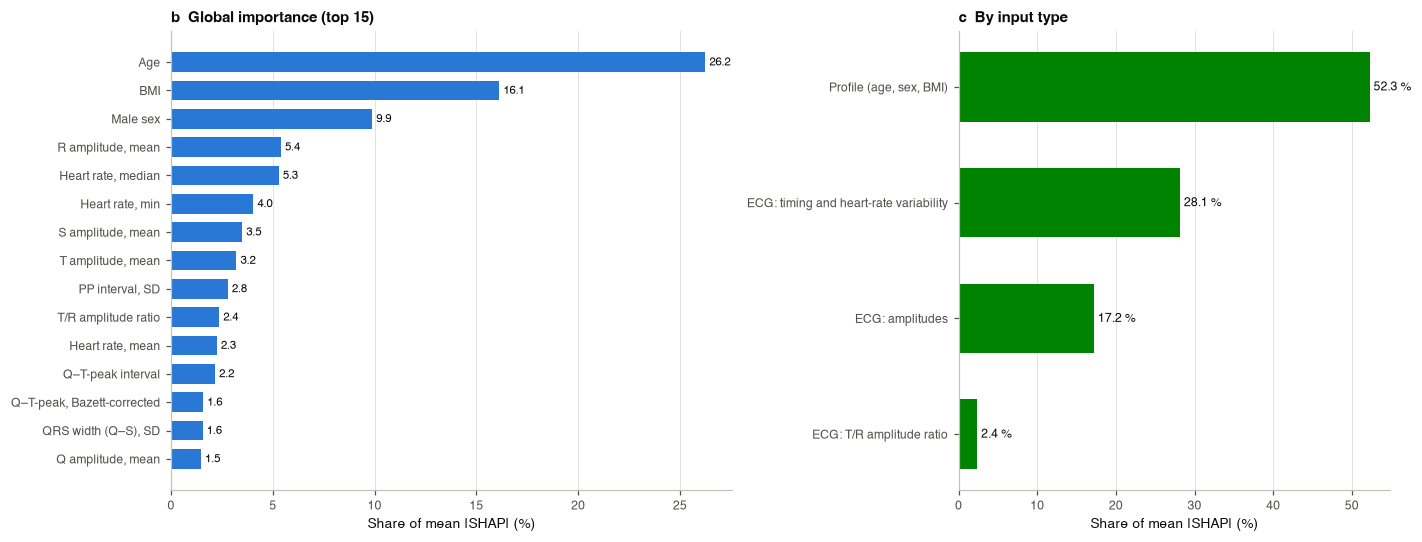

In [33]:
def imputer_of(model):
    return model.named_steps["impute"] if hasattr(model, "named_steps") else model.imputer_


Xt_raw = pri["X"]["test"]
imp_ = imputer_of(pri["model"])
if pri["kind"] in ("lgbm", "xgb", "rf"):
    Xi = imp_.transform(Xt_raw)
    sv = shap.TreeExplainer(pri["model"].named_steps["clf"]).shap_values(Xi)
    sv = sv[1] if isinstance(sv, list) else sv
    sv = sv[..., 1] if np.ndim(sv) == 3 else sv
else:
    rng_s = np.random.default_rng(C.SEED)
    bg = imp_.transform(pri["X"]["dev"][rng_s.choice(len(pri["X"]["dev"]), 200, replace=False)])
    sub = rng_s.choice(len(Xt_raw), min(400, len(Xt_raw)), replace=False)
    Xi = imp_.transform(Xt_raw[sub])
    expl = shap.PermutationExplainer(lambda Z: pri["model"].predict_proba(Z)[:, 1], shap.maskers.Independent(bg))
    sv = expl(Xi, silent=True).values
imp = pd.Series(np.abs(sv).mean(0), index=pri["cols"])
imp_pct = (100 * imp / imp.sum()).sort_values(ascending=False)


def input_group(c):
    if c in C.CLINICAL:
        return "Profile (age, sex, BMI)"
    if c in C.BLOOD_PRESSURE:
        return "Blood pressure"
    if c in C.LIFESTYLE:
        return "Lifestyle"
    if c == "t_r_ratio":
        return "ECG: T/R amplitude ratio"
    if c in ef.AMPLITUDE_FEATURES:
        return "ECG: amplitudes"
    return "ECG: timing and heart-rate variability"


grp = imp_pct.groupby(imp_pct.index.map(input_group)).sum().sort_values(ascending=False)
save_table(imp_pct.rename("mean |SHAP| (%)").to_frame().assign(group=lambda d: d.index.map(input_group)), "table17_shap_importance")
display(grp.round(1).to_frame("share of mean |SHAP| (%)"))

shap.summary_plot(sv, pd.DataFrame(Xi, columns=[pretty(c) for c in pri["cols"]]), max_display=15, show=False,
                  plot_size=(7.5, 6.2), color_bar_label="Input value")
plt.title("a  SHAP values, primary model (internal test)", loc="left", fontsize=10, fontweight="bold")
P.savefig(plt.gcf(), "fig14a_shap_beeswarm")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5.0), gridspec_kw={"width_ratios": [1.3, 1]})
top = imp_pct.iloc[:15][::-1]
axes[0].barh([pretty(f) for f in top.index], top.values, color=C.SERIES[0], height=0.7)
for i, v in enumerate(top.values):
    axes[0].text(v + 0.2, i, f"{v:.1f}", va="center", fontsize=7.5, color=C.INK["primary"])
axes[0].set_xlabel("Share of mean |SHAP| (%)"); axes[0].grid(axis="y", visible=False)
axes[0].set_title("b  Global importance (top 15)", loc="left")
axes[1].barh(grp.index[::-1], grp.values[::-1], color=C.SERIES[5], height=0.6)
for i, v in enumerate(grp.values[::-1]):
    axes[1].text(v + 0.5, i, f"{v:.1f} %", va="center", fontsize=8, color=C.INK["primary"])
axes[1].set_xlabel("Share of mean |SHAP| (%)"); axes[1].grid(axis="y", visible=False)
axes[1].set_title("c  By input type", loc="left")
fig.tight_layout()
P.savefig(fig, "fig14bc_shap_importance", data=imp_pct.rename("share").reset_index())
plt.show()

**Interpretation (Section 13): what the primary model relies on, and is it plausible?**
- **Split of mean |SHAP|:**
  - **52 %** profile: age 26 %, BMI 16 %, sex 10 %;
  - **48 %** ECG: timing and HRV 28 %, amplitudes 17 %, T/R ratio 2 %.

  The ECG is half of the decision, consistent with the significant IDI/NRI in Section 9.
- **Leading ECG predictors** and their direction in the (standardised) logistic model. Coefficients of correlated features are conditional on each other and should be read as a group.

  | Feature | Direction in prediabetes/diabetes | Plausible mechanism | Literature |
  |---|---|---|---|
  | Mean R amplitude (5.4 %) | higher → higher risk | left-ventricular mass increases with insulin resistance; R in I/aVL tracks LV mass | top feature in Koga *et al.* (2025) |
  | Heart rate (median 5.3 %, minimum 4.0 %, mean 2.3 %) | higher → higher risk | sympathetic predominance, early autonomic dysfunction | Koga *et al.* (2025); Zeng *et al.* (2026) |
  | S amplitude (3.5 %) | deeper S → higher risk | QRS-axis / LV-voltage changes | S-wave amplitude among Koga *et al.*'s top features |
  | T amplitude and T/R ratio (3.2 %, 2.4 %) | relatively flatter T → higher risk | repolarisation changes with hyperglycaemia | Zeng *et al.* (2026) |
  | HRV (RMSSD, SD of HR) | lower → higher risk | reduced vagal tone, already present in prediabetes | Zeng *et al.* (2026) |
  | Q→T-peak interval (2.2 %) | longer → higher risk | QT prolongation with dysglycaemia | Zeng *et al.* (2026) |

- **Clinical credibility.** The features can be explained to a clinician, which a raw-waveform black box cannot offer.

## 14. Model size, ESP32-S3 N16R8 budget and the deployment decision
**ESP32-S3 resources:**
- dual-core Xtensa LX7 at 240 MHz, with a single-precision FPU;
- 512 KB SRAM;
- on the **N16R8** module, 16 MB flash and 8 MB octal PSRAM.

**Arduino settings used by DiaGnostix:** partition scheme `app3M_fat9M_16MB` (3 MB application), PSRAM = OPI.

Two questions decide the deployment:
1. Does the trained model fit, and does it need TensorFlow Lite Micro?
2. Where does the feature extraction run?

,inputs,role,structure,flash (KB),inference RAM (B),operations,OOF AUROC,test AUROC
model,,,,,,,,
LightGBM (compact),ECG + profile,MCU candidate,"220 trees, 660 splits",16.387,344.0,220 tree walks,0.843,0.883
Logistic regression,ECG + profile,selected family,36 coefficients,1.102,280.0,35 MACs,0.845,0.878
MLP,ECG + profile,MCU candidate,"35-64-32-1 (4,417 weights)",18.074,792.0,"4,320 MACs",0.842,0.878
XGBoost,ECG + profile,reference,"450 trees, 1,349 splits",33.212,344.0,450 tree walks,0.842,0.884
Random forest,ECG + profile,reference,"100 trees, 10,036 splits",207.262,344.0,100 tree walks,0.835,0.876
LightGBM (unconstrained),ECG + profile,reference,"825 trees, 2,475 splits",60.698,344.0,825 tree walks,0.843,0.883
Logistic regression: Fallback (gain-invariant),Gain-invariant ECG + profile,deployed,26 coefficients,0.789,200.0,25 MACs,0.844,0.876
LightGBM (compact): ECG-only,ECG,deployed,"230 trees, 920 splits",21.812,320.0,230 tree walks,0.784,0.845
DiaCardia lead I (published),28 NeuroKit2 features (not MCU-computable),benchmark,"10 × LightGBM, 3791 trees, 219,526 splits",4546.424,NaN,3791 tree walks,NaN,0.844


,ESP32-S3 N16R8,DiaGnostix-ECG use
resource,,
Flash: application partition,3 MB of 16 MB,three models 23.7 KB; whole sketch ≈ 1.1–1.3 MB
SRAM,512 KB,"model inference < 1 KB; Wi-Fi, web server and ..."
PSRAM (octal),8 MB,feature-extractor work buffers 304 KB (double ...
ECG capture buffer,PSRAM,up to 60 s × 500 Hz × int16 = 59 KB (default s...
Compute per 10-s window,240 MHz LX7,"band-pass (2 × 6000 samples × 2 biquads), R-pe..."


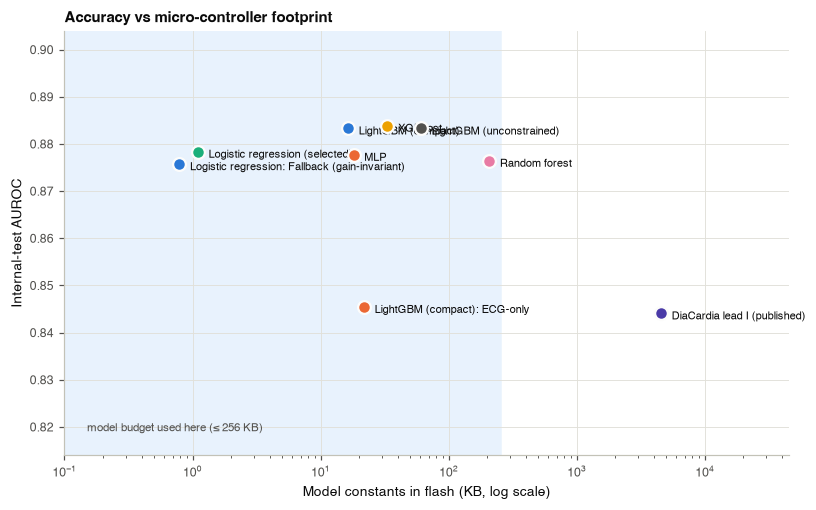

In [34]:
size_rows = []
for n, f in fam.items():
    size_rows.append({"model": n, "inputs": PRIMARY_SET, "role": "selected family" if n == FAMILY else ("MCU candidate" if n in MCU else "reference"),
                      "structure": f["structure"], "flash (KB)": f["flash_bytes"] / 1024, "inference RAM (B)": f["ram_bytes"],
                      "operations": f["ops"], "OOF AUROC": f["cv_auc"], "test AUROC": roc_auc_score(y["test"], f["test"])})
for role in ("fallback", "ecg_only"):
    f = final[role]
    size_rows.append({"model": f"{f['family']}: {ROLE_LABEL[role]}", "inputs": f["set"], "role": "deployed", "structure": f["structure"],
                      "flash (KB)": f["flash_bytes"] / 1024, "inference RAM (B)": f["ram_bytes"], "operations": f["ops"],
                      "OOF AUROC": f["cv_auc"], "test AUROC": roc_auc_score(y["test"], f["test"])})
t_, i_, l_ = ensemble_size(pub1)
size_rows.append({"model": "DiaCardia lead I (published)", "inputs": "28 NeuroKit2 features (not MCU-computable)", "role": "benchmark",
                  "structure": f"10 × LightGBM, {t_} trees, {i_:,} splits", "flash (KB)": M.lgbm_flash_bytes(i_, l_, t_) / 1024,
                  "inference RAM (B)": np.nan, "operations": f"{t_} tree walks", "OOF AUROC": np.nan,
                  "test AUROC": roc_auc_score(y["test"], pub_pred["test"])})
size_tab = save_table(pd.DataFrame(size_rows).set_index("model"), "table18_model_size")
display(size_tab.round(3))

N_WIN = int(C.RECORD_SECONDS * C.FS_DEVICE)
PAD = int(ef.PAD_S * C.FS_DEVICE)
N_SEG = N_WIN // 2 + 1
# work buffers of firmware/DiaGnostixECG/ecg_features.h (EcgFeatureExtractor::kWorkBytes):
# input, padded/filtered, |gradient|, 2 boxcars, cumulative sum, segment slopes + scratch (double); segment bounds (int)
work_bytes = 8 * (4 * N_WIN + (N_WIN + 2 * PAD) + (N_WIN + round(ef.AVG_S * C.FS_DEVICE) + 1) + 2 * N_SEG) + 4 * 2 * N_SEG
models_kb = sum(final[r]["flash_bytes"] for r in final) / 1024
budget = save_table(pd.DataFrame([
    ("Flash: application partition", "3 MB of 16 MB", f"three models {models_kb:.1f} KB; whole sketch ≈ 1.1–1.3 MB"),
    ("SRAM", "512 KB", "model inference < 1 KB; Wi-Fi, web server and sensor tasks use most of the rest"),
    ("PSRAM (octal)", "8 MB", f"feature-extractor work buffers {work_bytes / 1024:.0f} KB (double precision, ps_malloc)"),
    ("ECG capture buffer", "PSRAM", f"up to 60 s × {C.FS_DEVICE} Hz × int16 = {60 * C.FS_DEVICE * 2 / 1024:.0f} KB (default session: three 10-s windows)"),
    ("Compute per 10-s window", "240 MHz LX7", f"band-pass (2 × {N_WIN + 2 * PAD} samples × 2 biquads), R-peak detection, delineation and one model call: O(N); measured on the device in milliseconds"),
], columns=["resource", "ESP32-S3 N16R8", "DiaGnostix-ECG use"]).set_index("resource"), "table19_esp32s3_budget")
display(budget)

fig, ax = plt.subplots(figsize=(8.5, 5))
pcol = {**FAM_COLORS, "DiaCardia lead I (published)": C.MODEL_COLORS["DiaCardia (published)"]}
for n, r_ in size_tab.iterrows():
    col = pcol.get(n, ROLE_COLORS["fallback"] if "Fallback" in n else ROLE_COLORS["ecg_only"])
    ax.scatter(r_["flash (KB)"], r_["test AUROC"], s=70, color=col, edgecolor=C.INK["surface"], linewidth=1.5, zorder=3)
    ax.annotate(n + (" (selected)" if n == FAMILY else ""), (r_["flash (KB)"], r_["test AUROC"]), xytext=(7, -4),
                textcoords="offset points", fontsize=7.2, color=C.INK["primary"])
lo_, hi_ = size_tab["test AUROC"].min(), size_tab["test AUROC"].max()
ax.set_ylim(lo_ - 0.03, hi_ + 0.02)
ax.axvspan(1e-2, 256, color="#e8f2fd", zorder=0)
ax.text(0.15, lo_ - 0.025, "model budget used here (≤ 256 KB)", fontsize=7.5, color=C.INK["secondary"])
ax.set_xscale("log"); ax.set_xlim(0.1, size_tab["flash (KB)"].max() * 10)
ax.set(xlabel="Model constants in flash (KB, log scale)", ylabel="Internal-test AUROC")
ax.set_title("Accuracy vs micro-controller footprint", loc="left")
P.savefig(fig, "fig15_size_vs_auroc", data=size_tab.reset_index())
plt.show()

**Deployment decision (Section 14).**
- **Size.** The three deployed models need **23.7 KB** of flash in total:
  - primary logistic regression: 1.1 KB;
  - fallback logistic regression: 0.8 KB;
  - ECG-only compact LightGBM (230 trees): 21.8 KB.

  The published DiaCardia lead-I ensemble would need ≈ 4.4 MB as a C node table, and its features cannot be computed on a micro-controller.
- **Firmware footprint** (`firmware/DiaGnostixECG`, arduino-cli, esp32 core 3.3.12, N16R8 settings):
  - 1.15 MB of flash, 36 % of the 3 MB application partition;
  - 69 KB of static RAM;
  - 304 KB of feature-extractor work buffers and up to 59 KB of ECG capture in the 8 MB PSRAM.
- **No TensorFlow Lite Micro.** The models are evaluated in a few hundred operations by dependency-free C. The C headers reproduce Python to 3 × 10⁻¹⁶ (Section 15) and need no library. TFLite Micro would add a runtime and an arena for no benefit.
- **The `.h5` export is still provided.** The Keras MLP of the comparison is saved as `.h5` and `.keras` and converted to TFLite float32 and int8 (int8: 98.9 % identical tiers) for the phone app and the cloud. A future raw-waveform CNN would need this path.
- **No cloud for a result.** Inference is local and the result is immediate; the cloud tier is reserved for opt-in longitudinal analysis and the clinician view.
- **The other sensors are not model inputs.** The training data contain no SpO₂, skin temperature or room conditions, so these sensors are validity and safety gates instead:
  - lead-off detection;
  - SQI;
  - fever warning;
  - low-SpO₂ alert.

## 15. Export for the firmware (Arduino IDE) and parity verification
**What is exported**

| File | Content | Used by |
|---|---|---|
| `dgx_model_primary.h`, `dgx_model_fallback.h`, `dgx_model_ecg_only.h` | dependency-free C (`DGX_PRI`, `DGX_FB`, `DGX_ECG`): input names, medians, model, Platt calibration, tier thresholds | the ESP32-S3 sketch |
| `dgx_models.h` | version string + includes the three headers | the sketch |
| `dgx_dsp_spec.h` | 500 Hz band-pass biquads and every extractor constant | `ecg_features.h` |
| `golden_vectors/` | device-domain ECG streams (µV), expected features, profiles and model scores | host test of the C++ extractor and models |
| `dgx_selftest_vector.h` | one 10-s window as integer mV + its expected features and ECG-only score | boot self-test on the ESP32-S3 |
| `../models/dgx_mlp.h5`, `.keras` | the Keras MLP of the family comparison | training / cloud |
| `../models/dgx_mlp_fp32.tflite`, `dgx_mlp_int8.tflite`, `dgx_mlp_int8_tflite.h` | the same MLP for TFLite (phone, cloud) and TFLite Micro | optional paths |
| `dgx_model_mlp.h` | the same MLP as plain C (no TFLite needed) | optional |
| `../models/feature_spec.json`, `model_card.json` | everything the Flutter app or a cloud service needs to reproduce a result | app / cloud |

**About the `.h5` file.** HDF5 is a training-time format; a C/C++ sketch on an ESP32 cannot parse it. The Arduino IDE therefore receives the model as C source, reached by one of two routes:
- `.h5` → TFLite → C byte array, run by TFLite Micro;
- weights → C arrays, as `dgx_model_mlp.h`.

The deployed models need no `.h5` at all: they are exported directly as C.

In [35]:
DEP = C.DEPLOY_DIR
VERSION = "2.0.0"
meta_base = {"project": "DiaGnostix-ECG prediabetes/diabetes risk (lead-I ECG + profile)",
             "endpoint": "FPG>=110 mg/dL or HbA1c>=6.0 % or diabetes treatment (Koga et al. 2025)",
             "acquisition": "AD8232 lead I (RA right wrist, LA left wrist, RL right leg) -> ESP32-S3 ADC1 GPIO4, 500 Hz, 10-s window, amplitudes in uV",
             "training data": f"Koga et al. 2025 (Zenodo 16416031) development set, n={len(dev)}",
             "version": VERSION}


def export_c(info, path, prefix, meta):
    kind, m, cols = info["kind"], info["model"], info["cols"]
    thr = {"youden": info["thr"]["youden"], "sens90": info["thr"]["sens90"]}
    platt = (info["platt"].a_, info["platt"].b_)
    if kind == "lgbm":
        return E.lgbm_to_c(m.named_steps["clf"].booster_, path, cols, m.named_steps["impute"].statistics_, platt, thr, meta, prefix=prefix)
    if kind == "lr":
        return E.lr_to_c(m, path, cols, platt, thr, meta, prefix=prefix)
    if kind == "mlp":
        return E.mlp_to_c(m, path, cols, platt, thr, meta, prefix=prefix)
    raise ValueError(kind)


exp_info = {}
for role, f in final.items():
    meta = {**meta_base, "model family": f["family"], "role": f"{role}: used when {f['use']}", "inputs": f"{len(f['cols'])} ({f['set']})",
            "internal test AUROC": f"{roc_auc_score(y['test'], f['test']):.3f}"}
    if role == "ecg_only":
        meta["external AUROC"] = f"{roc_auc_score(y['ext'], f['ext']):.3f}"
    exp_info[role] = export_c(f, DEP / f["header"], f["prefix"], meta)
E.dsp_spec_header(DEP / "dgx_dsp_spec.h", fs_list=(C.FS_DEVICE,))
(DEP / "dgx_models.h").write_text(
    E.HEADER_NOTE.format(date=time.strftime("%Y-%m-%d"))
    + "/* DiaGnostix-ECG model bundle: include this one header in the sketch. */\n"
    + "#ifndef DGX_MODELS_H\n#define DGX_MODELS_H\n"
    + f'#define DGX_MODEL_VERSION "{VERSION}"\n#define DGX_MODEL_FAMILY "primary {pri["family"]}, fallback {fb["family"]}, ECG-only {eo["family"]}"\n'
    + f'#define DGX_PRIMARY_INPUT_SET "{PRIMARY_SET}"\n'
    + f"#define DGX_MODEL_FS_HZ {C.FS_DEVICE}\n#define DGX_MODEL_WINDOW_S {C.RECORD_SECONDS!r}\n"
    + "".join(f'#include "{f["header"]}"\n' for f in final.values()) + "#endif /* DGX_MODELS_H */\n")

# Keras MLP of the family comparison -> .h5 / .keras -> TFLite float32 + int8 -> C
mlp_f = fam["MLP"]
mlp = mlp_f["model"]
mlp.model_.save(C.MODEL_DIR / "dgx_mlp.h5")
mlp.model_.save(C.MODEL_DIR / "dgx_mlp.keras")
mlp_c = E.mlp_to_c(mlp, DEP / "dgx_model_mlp.h", mlp_f["cols"], (mlp_f["platt"].a_, mlp_f["platt"].b_),
                   {"youden": mlp_f["thr"]["youden"], "sens90": mlp_f["thr"]["sens90"]},
                   {**meta_base, "role": "MLP of the model-family comparison (Keras .h5 -> plain C); optional", "inputs": PRIMARY_SET},
                   prefix="DGX_MLP")
rep_idx = np.random.default_rng(C.SEED).choice(len(mlp_f["X"]["dev"]), 1000, replace=False)
tfl = E.keras_to_tflite(mlp.model_, mlp.transform_inputs(mlp_f["X"]["dev"][rep_idx]), C.MODEL_DIR / "dgx_mlp_fp32.tflite",
                        C.MODEL_DIR / "dgx_mlp_int8.tflite")
Xt_std = mlp.transform_inputs(mlp_f["X"]["test"])
p_keras = mlp.model_.predict(Xt_std, verbose=0).ravel()
p_h5 = tf.keras.models.load_model(C.MODEL_DIR / "dgx_mlp.h5", compile=False).predict(Xt_std, verbose=0).ravel()
p_fp32, _, _ = E.tflite_predict(C.MODEL_DIR / "dgx_mlp_fp32.tflite", Xt_std)
p_int8, q_in, q_out = E.tflite_predict(C.MODEL_DIR / "dgx_mlp_int8.tflite", Xt_std)
E.tflite_to_c_array(C.MODEL_DIR / "dgx_mlp_int8.tflite", DEP / "dgx_mlp_int8_tflite.h", meta={**meta_base, "inputs": PRIMARY_SET},
                    quant=(q_in, q_out))
json.dump({"features": mlp_f["cols"], "median": list(mlp.imputer_.statistics_), "mean": list(mlp.scaler_.mean_),
           "scale": list(mlp.scaler_.scale_), "clip": mlp.CLIP, "platt": [mlp_f["platt"].a_, mlp_f["platt"].b_],
           "thresholds": mlp_f["thr"], "tflite_input_quant": list(q_in), "tflite_output_quant": list(q_out)},
          open(C.MODEL_DIR / "dgx_mlp_preprocessing.json", "w"), indent=1)

# Python artefacts of the deployed models
for role, f in final.items():
    if f["kind"] == "mlp":
        f["model"].model_.save(C.MODEL_DIR / f"model_{role}.keras")
        joblib.dump({"imputer": f["model"].imputer_, "scaler": f["model"].scaler_}, C.MODEL_DIR / f"model_{role}_preprocessing.joblib")
    else:
        joblib.dump(f["model"], C.MODEL_DIR / f"model_{role}.joblib")
    if f["kind"] == "lgbm":
        f["model"].named_steps["clf"].booster_.save_model(str(C.MODEL_DIR / f"model_{role}_booster.txt"))

art = pd.DataFrame([(f["header"], f"{ROLE_LABEL[r]} ({f['prefix']}), {f['set']}", exp_info[r]["flash_bytes"], f["structure"]) for r, f in final.items()]
                   + [("dgx_model_mlp.h", "MLP, plain C (optional)", mlp_c["flash_bytes"], f"widths {mlp_c['widths']}"),
                      ("dgx_mlp_int8_tflite.h", "MLP, TFLite int8 flatbuffer (optional)", tfl["int8_bytes"], f"input q {q_in}, output q {q_out}"),
                      ("../models/dgx_mlp_fp32.tflite", "MLP, TFLite float32 (phone / cloud)", tfl["fp32_bytes"], ""),
                      ("../models/dgx_mlp.h5", "Keras HDF5 model", (C.MODEL_DIR / "dgx_mlp.h5").stat().st_size, ""),
                      ("dgx_dsp_spec.h", "500 Hz biquads + extractor constants", (DEP / "dgx_dsp_spec.h").stat().st_size, "")],
                   columns=["file", "content", "bytes", "details"])
save_table(art, "table20_export_artifacts", index=False)
syntax = {h.name: subprocess.run(["clang", "-std=c99", "-Wall", "-Wextra", "-fsyntax-only", "-x", "c", str(h)],
                                 capture_output=True, text=True).returncode == 0 for h in sorted(DEP.glob("*.h"))}
print("clang -std=c99 -Wall -Wextra syntax check:", syntax)
art

Summary on the non-converted ops:
---------------------------------
 * Accepted dialects: tfl, builtin, func
 * Non-Converted Ops: 6, Total Ops 13, % non-converted = 46.15 %
 * 6 ARITH ops

- arith.constant:    6 occurrences  (f32: 6)



  (f32: 3)
  (f32: 1)


Summary on the non-converted ops:
---------------------------------
 * Accepted dialects: tfl, builtin, func
 * Non-Converted Ops: 6, Total Ops 13, % non-converted = 46.15 %
 * 6 ARITH ops

- arith.constant:    6 occurrences  (f32: 6)



  (f32: 3)
  (f32: 1)
fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


clang -std=c99 -Wall -Wextra syntax check: {'dgx_dsp_spec.h': True, 'dgx_mlp_int8_tflite.h': True, 'dgx_model_ecg_only.h': True, 'dgx_model_fallback.h': True, 'dgx_model_mlp.h': True, 'dgx_model_primary.h': True, 'dgx_models.h': True, 'dgx_selftest_vector.h': True}


,file,content,bytes,details
0,dgx_model_primary.h,"Primary (DGX_PRI), ECG + profile",1128,36 coefficients
1,dgx_model_fallback.h,"Fallback (gain-invariant) (DGX_FB), Gain-invar...",808,26 coefficients
2,dgx_model_ecg_only.h,"ECG-only (DGX_ECG), ECG",22336,"230 trees, 920 splits"
3,dgx_model_mlp.h,"MLP, plain C (optional)",18508,"widths [35, 64, 32, 1]"
4,dgx_mlp_int8_tflite.h,"MLP, TFLite int8 flatbuffer (optional)",7120,"input q (0.03921568766236305, -1), output q (0..."
5,../models/dgx_mlp_fp32.tflite,"MLP, TFLite float32 (phone / cloud)",19688,
6,../models/dgx_mlp.h5,Keras HDF5 model,92056,
7,dgx_dsp_spec.h,500 Hz biquads + extractor constants,1179,


In [36]:
headers = [(f["header"], f["prefix"], len(f["cols"])) for f in final.values()] + [("dgx_model_mlp.h", "DGX_MLP", len(mlp_f["cols"]))]
feats32 = {f["prefix"]: f["X"]["test"].astype(np.float32) for f in final.values()}
feats32["DGX_MLP"] = mlp_f["X"]["test"].astype(np.float32)
c_out, c_warn = E.compile_and_run_parity(DEP, headers, feats32)
par_rows = []
for f in list(final.values()) + [{**mlp_f, "prefix": "DGX_MLP", "header": "dgx_model_mlp.h", "role": "MLP (optional)"}]:
    X64 = feats32[f["prefix"]].astype(float)
    py = f["model"].predict_proba(X64)[:, 1]
    c = c_out[f["prefix"]]
    par_rows.append({"check": f"{f['header']} ({f['role']}) vs Python", "max |Δ score|": np.max(np.abs(py - c[:, 0])),
                     "max |Δ calibrated risk|": np.max(np.abs(f["platt"].transform(py) - c[:, 1])),
                     "same risk tier %": 100 * np.mean(tier_of(py, f) == tier_of(c[:, 0], f)),
                     "AUROC Python": roc_auc_score(y["test"], py), "AUROC C": roc_auc_score(y["test"], c[:, 0])})
for name, p_ in [("Keras in memory vs dgx_mlp.h5 reloaded", p_h5), ("Keras vs TFLite float32", p_fp32), ("Keras vs TFLite int8", p_int8)]:
    par_rows.append({"check": name, "max |Δ score|": np.max(np.abs(p_keras - p_)), "max |Δ calibrated risk|": np.nan,
                     "same risk tier %": 100 * np.mean(tier_of(p_keras, mlp_f) == tier_of(p_, mlp_f)),
                     "AUROC Python": roc_auc_score(y["test"], p_keras), "AUROC C": roc_auc_score(y["test"], p_)})
parity = save_table(pd.DataFrame(par_rows).set_index("check"), "table21_export_parity")
print("compiler warnings:", c_warn.strip() or "none")
parity

compiler warnings: none


,max |Δ score|,max |Δ calibrated risk|,same risk tier %,AUROC Python,AUROC C
check,,,,,
dgx_model_primary.h (primary) vs Python,3.331e-16,9.992e-16,100.000,0.878,0.878
dgx_model_fallback.h (fallback) vs Python,2.776e-16,1.443e-15,100.000,0.876,0.876
dgx_model_ecg_only.h (ecg_only) vs Python,0.000e+00,5.551e-17,100.000,0.845,0.845
dgx_model_mlp.h (MLP (optional)) vs Python,1.167e-07,3.028e-07,100.000,0.878,0.878
Keras in memory vs dgx_mlp.h5 reloaded,0.000e+00,NaN,100.000,0.878,0.878
Keras vs TFLite float32,1.192e-07,NaN,100.000,0.878,0.878
Keras vs TFLite int8,1.940e-02,NaN,98.866,0.878,0.878


In [37]:
# Golden vectors: the device-domain stream (uV at the electrodes, after the simulated ESP32-S3 ADC) -> features -> scores.
# firmware/test checks the C++ extractor and the model headers against these before the device is used.
t_ok = EI.loc[idx["test"], "sqi_ok"].astype(bool)
pos_ids = [i for i in idx["test"] if pc.loc[i, C.LABEL] and t_ok[i]][:8]
neg_ids = [i for i in idx["test"] if not pc.loc[i, C.LABEL] and t_ok[i]][:8]
bad_ids = [i for i in idx["test"] if not t_ok[i]][:4]
gold_int, gold_ext = pos_ids + neg_ids + bad_ids, list(idx["ext"][:2])
sig, feats_g = [], []
for gid, internal in [(i, True) for i in gold_int] + [(i, False) for i in gold_ext]:
    k = pc.index.get_loc(gid) if internal else ext.index.get_loc(gid)
    f_, dbg = ef.process_record(raw_int[k] if internal else raw_ext[k], uv_per_lsb=C.UV_PER_LSB if internal else C.UV_PER_LSB_EXTERNAL,
                                fs_dev=C.FS_DEVICE, seed=k, return_debug=True, **CONDITIONS[DEV_COND])
    sig.append(dbg["x"])
    feats_g.append(f_)
ids_g = gold_int + gold_ext
Fg = pd.DataFrame(feats_g, index=pd.Index(ids_g, name="ecg_id"))
ref_g = pd.concat([EI.loc[gold_int], EX.loc[gold_ext]])
assert np.allclose(Fg[ef.EDGE_ALL].to_numpy(float), ref_g[ef.EDGE_ALL].to_numpy(float), equal_nan=True), "golden path != training path"
gold_dir = DEP / "golden_vectors"
E.write_golden_vectors(gold_dir, ids_g, np.vstack(sig), Fg, C.FS_DEVICE)
prof = pd.DataFrame(np.nan, index=Fg.index, columns=NONECG)
prof.loc[gold_int, NONECG] = pc.loc[gold_int, NONECG].astype(float).to_numpy()
prof.to_csv(gold_dir / "profiles.csv", float_format="%.17g", na_rep="nan")
sc = pd.DataFrame(index=Fg.index)
for role, f in final.items():
    Xr = Fg[ef.EDGE_ALL].join(prof)[f["cols"]].to_numpy(dtype=float).astype(np.float32).astype(float)   # the device feeds float32
    sc[role] = f["model"].predict_proba(Xr)[:, 1]
sc.to_csv(gold_dir / "scores.csv", float_format="%.17g")

# The firmware receives integer mV from analogReadMilliVolts(); check that every golden uV stream maps back to exact
# integers, so the host test can replay the ADC path bit for bit: uV = (mV - REF) * 1000 / gain.
mv_g = np.round(np.vstack(sig) * C.AD8232_GAIN / 1000.0 + C.ADC_REF_MV)
assert np.array_equal((mv_g - C.ADC_REF_MV) * 1000.0 / C.AD8232_GAIN, np.vstack(sig)), "golden uV are not integer-mV ADC values"
# One record as a self-test vector compiled into the sketch: the ESP32-S3 checks its extractor and ECG-only model at boot.
st_id = pos_ids[0]
j = ids_g.index(st_id)
with open(DEP / "dgx_selftest_vector.h", "w") as fh:
    fh.write(E.HEADER_NOTE.format(date=time.strftime("%Y-%m-%d"))
             + f"/* Boot self-test: one 10-s lead-I window (record {st_id}) as analogReadMilliVolts() values at gain "
             f"{C.AD8232_GAIN:g}, REF {C.ADC_REF_MV:g} mV,\n   with the features and ECG-only score computed in Python. */\n"
             + "#ifndef DGX_SELFTEST_VECTOR_H\n#define DGX_SELFTEST_VECTOR_H\n#include <stdint.h>\n"
             + f"#define DGX_SELFTEST_GAIN {C.AD8232_GAIN!r}\n#define DGX_SELFTEST_REF_MV {C.ADC_REF_MV!r}\n"
             + f"#define DGX_SELFTEST_N_BEATS {int(Fg.loc[st_id, 'n_beats'])}\n#define DGX_SELFTEST_ECG_SCORE {sc.loc[st_id, 'ecg_only']!r}\n"
             + E.c_array("int16_t", "DGX_SELFTEST_MV", mv_g[j].astype(int), "int", 20)
             + E.c_array("double", "DGX_SELFTEST_FEATURES", Fg.loc[st_id, ef.EDGE_ALL].to_numpy(float), "double", 4)
             + "#endif\n")
for p_ in gold_dir.iterdir():
    shutil.copy(p_, FW_GOLDEN / p_.name)
for h in [f["header"] for f in final.values()] + ["dgx_models.h", "dgx_dsp_spec.h", "dgx_selftest_vector.h"]:
    shutil.copy(DEP / h, SKETCH / h)
print(f"golden vectors: {len(ids_g)} records ({len(pos_ids)} events, {len(neg_ids)} non-events, {len(bad_ids)} SQI failures, "
      f"{len(gold_ext)} external) -> {FW_GOLDEN.relative_to(C.REPO_DIR)}")
print(f"model headers copied to {SKETCH.relative_to(C.REPO_DIR)}")
sc.join(Fg[["sqi_ok", "n_beats", "hr_mean_bpm"]]).round(4)

golden vectors: 22 records (8 events, 8 non-events, 4 SQI failures, 2 external) -> firmware/test/golden
model headers copied to firmware/DiaGnostixECG


,primary,fallback,ecg_only,sqi_ok,n_beats,hr_mean_bpm
ecg_id,,,,,,
000260_20220111,0.924,0.932,0.212,True,13,76.633
000260_20221129,0.881,0.892,0.219,True,12,71.093
000412_20221229,0.748,0.741,0.200,True,12,73.715
000553_20220117,0.847,0.867,0.213,True,13,75.165
000777_20220121,0.760,0.656,0.270,True,11,65.172
000792_20220121,0.508,0.530,0.208,True,14,83.322
000792_20221213,0.570,0.562,0.179,True,15,89.808
000839_20220122,0.858,0.870,0.177,True,13,80.450
000021_20220104,0.283,0.267,0.050,True,9,52.001


In [38]:
RISK_MESSAGES = {
    "High": "Raised risk of prediabetes or diabetes. Please visit a clinic or hospital for a fasting plasma glucose or HbA1c blood test.",
    "Elevated": "Moderately raised risk. Ask for a fasting glucose or HbA1c test at your next check-up, or within the next few months.",
    "Low": "Low risk on this screen. It does not rule out diabetes; keep your regular health check-ups.",
    "No result": "The ECG signal quality was too low for a result. Sit still, check the electrodes and measure again.",
}
spec = {
    "version": VERSION, "endpoint": meta_base["endpoint"], "sampling_rate_hz": C.FS_DEVICE, "window_s": C.RECORD_SECONDS,
    "session": "30-s recording = three 10-s windows; risk = median model score of the windows that pass the SQI (at least two)",
    "units": {"ecg": "uV at the electrodes (ADC mV - REF) * 1000 / AD8232 gain", "age": "years", "male_sex": "0/1",
              "BMI": "kg/m2", "sBP": "mmHg", "dBP": "mmHg", "smoking": "0/1", "drinking": "1 rarely, 2 occasionally, 3 regularly"},
    "models": {role: {"header": f["header"], "prefix": f["prefix"], "used_when": f["use"], "family": f["family"], "inputs": f["cols"],
                      "medians": [float(v) for v in imputer_of(f["model"]).statistics_],
                      "thresholds_on_score": {"youden": f["thr"]["youden"], "sens90": f["thr"]["sens90"]},
                      "tiers_on_score": {"elevated": tiers(f)[0], "high": tiers(f)[1]},
                      "platt": {"a": f["platt"].a_, "b": f["platt"].b_}} for role, f in final.items()},
    "risk_messages": RISK_MESSAGES,
}
json.dump(spec, open(C.MODEL_DIR / "feature_spec.json", "w"), indent=1)
perf = lambda s_: {k: float(s_.loc[k, "estimate"]) for k in ["sensitivity", "specificity", "PPV", "NPV"]}
model_card = {
    "name": "DiaGnostix-ECG prediabetes/diabetes risk models", "version": VERSION, "date": time.strftime("%Y-%m-%d"),
    "intended_use": "Pre-test triage of adults: flag those whose 10-s resting lead-I ECG and profile suggest impaired glucose "
                    "metabolism and advise a laboratory FPG/HbA1c test. Not a diagnostic device.",
    "not_intended_for": ["diagnosis of diabetes", "glucose monitoring or insulin dosing", "children or pregnant women",
                         "people with pacemakers, atrial fibrillation or other arrhythmias (not evaluated)"],
    "endpoint": meta_base["endpoint"], "training_data": meta_base["training data"],
    "acquisition": meta_base["acquisition"], "primary_input_set": PRIMARY_SET,
    "models": {role: {"family": f["family"], "inputs": f["cols"], "used_when": f["use"], "oof_auroc": f["cv_auc"],
                      "internal_test_auroc": list(S.auc_delong_ci(y["test"], f["test"]))} for role, f in final.items()},
    "performance_primary": {"internal_test_high_tier": perf(summ["youden"]), "internal_test_elevated_or_high": perf(summ["sens90"])},
    "performance_ecg_only_external": {"auroc": list(S.auc_delong_ci(y["ext"], eo["ext"])),
                                      "high_tier": perf(summ_eo["external"]["youden"])},
    "limitations": ["Japanese check-up cohorts only", "simulated AD8232/ESP32-S3 front-end; no recordings from the physical device yet",
                    "composite endpoint includes diabetes; no OGTT", "external validation possible for the ECG-only model only",
                    "requires local recalibration where prevalence or criteria differ (e.g., Taiwan, ADA)"],
}
json.dump(model_card, open(C.MODEL_DIR / "model_card.json", "w"), indent=1, default=float)
print(json.dumps(model_card["performance_primary"], indent=1))

{
 "internal_test_high_tier": {
  "sensitivity": 0.8231292517006803,
  "specificity": 0.76324395029431,
  "PPV": 0.2505175983436853,
  "NPV": 0.9782062028499581
 },
 "internal_test_elevated_or_high": {
  "sensitivity": 0.9183673469387755,
  "specificity": 0.6245912361020275,
  "PPV": 0.19040902679830748,
  "NPV": 0.9875904860392968
 }
}


## 16. Results summary
The next cell writes the key numbers to `outputs/RESULTS_SUMMARY.md`. All numbers are regenerated whenever the notebook is re-run.

In [39]:
def ci(a):
    return f"{a[0]:.3f} (95 % CI {a[1]:.3f}–{a[2]:.3f})"


a_pub, a_pub_e = S.auc_delong_ci(y["test"], pub_pred["test"]), S.auc_delong_ci(y["ext"], pub_pred["ext"])
a_ext_eo = S.auc_delong_ci(y["ext"], eo["ext"])
d_int, p_int = S.delong_test(y["test"], p_test, pub_pred["test"])
sy, ss = summ["youden"], summ["sens90"]
st_i = strata_tab.loc[("Primary", "Internal test")]
st_e = strata_tab.loc[("ECG-only", "External")]
hl, el = "flagged % (high tier)", "flagged % (elevated or high)"
gain_tab = rob_gain.set_index(["model", "gain"])
txt = f'''# DiaGnostix-ECG: key results (auto-generated {time.strftime('%Y-%m-%d')})

## Data and design
- Internal cohort: {len(pc):,} ECGs from {pc.participant_id.nunique():,} adults; {pc[C.LABEL].sum():,} ({100 * pc[C.LABEL].mean():.1f} %) prediabetes/diabetes.
- Participant-disjoint split: development {len(dev):,} ({y['dev'].sum():,} events) / internal test {len(test):,} ({y['test'].sum()} events); 10-fold grouped CV inside development.
- External cohort (other hospital and ECG vendor): {len(ext):,} ECGs, {y['ext'].sum()} events ({100 * y['ext'].mean():.1f} %); no age, sex, BMI or BP.
- Device simulation: AD8232 filters → ESP32-S3 ADC (integer mV, gain 1100, 3 mV noise) at {C.FS_DEVICE} Hz; {headroom_tab.loc['internal', 'records reaching the ADC limit (%)']:.2f} % of internal records reach the ADC limit.

## Benchmark
- Published DiaCardia lead-I ensemble, internal test AUROC {ci(a_pub)}; external {ci(a_pub_e)}.

## Inputs and model (pre-specified rules, development data only)
- Input selection: ''' + "; ".join(f"{r['step']}: {r['gain']:+.3f} → {r['decision']}" for r in steps) + f'''.
- Primary input set: **{PRIMARY_SET}** ({len(PRIMARY_COLS)} inputs). Model family: **{FAMILY}** ({pri['structure']}, {pri['flash_bytes'] / 1024:.1f} KB).
- Same rule per deployed model: fallback **{fb['family']}** ({fb['structure']}); ECG-only **{eo['family']}** ({eo['structure']}).
- Development OOF AUROC: primary {pri['cv_auc']:.3f}; fallback {fb['cv_auc']:.3f}; ECG-only {eo['cv_auc']:.3f}; profile only (no ECG) {dev_sets['Profile']['cv_auc']:.3f}.
- Riley minimum sample size (p = {len(PRIMARY_COLS)}): {int(riley_tab.iloc[:3]['records needed'].max()):,} records needed vs {len(dev):,} available.

## Internal test (primary model)
- AUROC {ci(a_pri)}; vs published DiaCardia lead I ΔAUROC {d_int:+.3f} (DeLong P = {p_int:.3g}).
- High tier (Youden): sensitivity {S.fmt_ci(sy.loc['sensitivity'], pct=True)} %, specificity {S.fmt_ci(sy.loc['specificity'], pct=True)} %, PPV {100 * sy.loc['PPV', 'estimate']:.1f} %, NPV {100 * sy.loc['NPV', 'estimate']:.1f} %.
- Elevated or high (90 %-sensitivity): sensitivity {S.fmt_ci(ss.loc['sensitivity'], pct=True)} %, specificity {S.fmt_ci(ss.loc['specificity'], pct=True)} %, NPV {100 * ss.loc['NPV', 'estimate']:.1f} %.
- Calibration after Platt: intercept {cal['Platt-recalibrated']['calibration_intercept']:+.2f}, slope {cal['Platt-recalibrated']['calibration_slope']:.2f}, Brier {cal['Platt-recalibrated']['Brier']:.4f}.
- Reclassification: ''' + "; ".join(f"{k.split(':')[0]}: IDI {v['IDI']}, cfNRI {v['cfNRI']}" for k, v in recl.iterrows()) + f'''.
- Flagged high (internal): normoglycaemia {st_i.loc['Normoglycaemia', hl]} %; prediabetes range {st_i.loc['Prediabetes range', hl]} %; untreated diabetes range {st_i.loc['Diabetes range, untreated', hl]} %.
- Prediabetes range vs normoglycaemia AUROC: {sens_tab.loc[('Primary', 'Internal test'), 'AUROC prediabetes range vs normoglycaemia']}.

## External validation (ECG-only model)
- AUROC {ci(a_ext_eo)}; vs published DiaCardia lead I ΔAUROC {d_ext:+.3f} (P = {p_ext_delong:.3g}).
- High tier: sensitivity {100 * summ_eo['external']['youden'].loc['sensitivity', 'estimate']:.1f} %, specificity {100 * summ_eo['external']['youden'].loc['specificity', 'estimate']:.1f} %.
- Calibration-in-the-large intercept {cal_ext['calibration_intercept']:+.2f} (mean predicted {cal_ext['mean_predicted']:.3f} vs observed {cal_ext['observed_rate']:.3f}).
- Prediabetes range vs normoglycaemia AUROC: {sens_tab.loc[('ECG-only', 'External'), 'AUROC prediabetes range vs normoglycaemia']}; flagged high: prediabetes range {st_e.loc['Prediabetes range', hl]} %.

## Hardware robustness
- Acquisition chain (primary, retrained test AUROC): ''' + "; ".join(f"{i} {r['primary: test AUROC, retrained']:.3f}" for i, r in rob_acq.iterrows()) + f'''.
- ADC noise 20 mV at the pin: test AUROC {rob_adc.set_index('ADC noise SD at GPIO4 (mV)').loc[20.0, 'primary: test AUROC']:.3f}.
- Body noise at 10 dB in-band SNR: test AUROC {rob_noise.set_index('in-band SNR (dB)').loc[10, 'primary: test AUROC (all)']:.3f}, SQI pass {rob_noise.set_index('in-band SNR (dB)').loc[10, 'SQI pass %']:.1f} %.
- Gain error 1.2×: primary sensitivity/specificity {100 * gain_tab.loc[('Primary', 1.2), 'sensitivity']:.1f}/{100 * gain_tab.loc[('Primary', 1.2), 'specificity']:.1f} %; fallback {100 * gain_tab.loc[('Fallback (gain-invariant)', 1.2), 'sensitivity']:.1f}/{100 * gain_tab.loc[('Fallback (gain-invariant)', 1.2), 'specificity']:.1f} % (calibrated gain: {100 * gain_tab.loc[('Primary', 1.0), 'sensitivity']:.1f}/{100 * gain_tab.loc[('Primary', 1.0), 'specificity']:.1f} %).

## Deployment on the ESP32-S3 N16R8
- Three plain-C models, {models_kb:.1f} KB of flash in total; C vs Python max |Δ score| {parity.iloc[:3]['max |Δ score|'].max():.1e}; risk tiers identical in {parity.iloc[:3]['same risk tier %'].min():.2f} % of test records.
- Keras MLP exported as .h5 → TFLite: float32 max |Δ| {parity.loc['Keras vs TFLite float32', 'max |Δ score|']:.1e}; int8 max |Δ| {parity.loc['Keras vs TFLite int8', 'max |Δ score|']:.3f}.
- Published DiaCardia lead-I ensemble as a C node table: ≈ {M.lgbm_flash_bytes(i_, l_, t_) / 1024 / 1024:.1f} MB, and its features cannot be computed on a micro-controller.
'''
(C.OUT_DIR / "RESULTS_SUMMARY.md").write_text(txt)
display(Markdown(txt))

# DiaGnostix-ECG: key results (auto-generated 2026-10-17)

## Data and design
- Internal cohort: 16,766 ECGs from 16,339 adults; 1,447 (8.6 %) prediabetes/diabetes.
- Participant-disjoint split: development 15,090 (1,300 events) / internal test 1,676 (147 events); 10-fold grouped CV inside development.
- External cohort (other hospital and ECG vendor): 2,456 ECGs, 366 events (14.9 %); no age, sex, BMI or BP.
- Device simulation: AD8232 filters → ESP32-S3 ADC (integer mV, gain 1100, 3 mV noise) at 500 Hz; 1.06 % of internal records reach the ADC limit.

## Benchmark
- Published DiaCardia lead-I ensemble, internal test AUROC 0.844 (95 % CI 0.811–0.877); external 0.746 (95 % CI 0.721–0.772).

## Inputs and model (pre-specified rules, development data only)
- Input selection: ECG → ECG + profile: +0.059 → add; ECG + profile → ECG + profile + BP: -0.000 → do not add; ECG + profile → ECG + profile + BP + lifestyle: -0.000 → do not add.
- Primary input set: **ECG + profile** (35 inputs). Model family: **Logistic regression** (36 coefficients, 1.1 KB).
- Same rule per deployed model: fallback **Logistic regression** (26 coefficients); ECG-only **LightGBM (compact)** (230 trees, 920 splits).
- Development OOF AUROC: primary 0.845; fallback 0.844; ECG-only 0.784; profile only (no ECG) 0.828.
- Riley minimum sample size (p = 35): 2,389 records needed vs 15,090 available.

## Internal test (primary model)
- AUROC 0.878 (95 % CI 0.853–0.903); vs published DiaCardia lead I ΔAUROC +0.034 (DeLong P = 0.0042).
- High tier (Youden): sensitivity 82.3 (76.2–88.5) %, specificity 76.3 (74.2–78.5) %, PPV 25.1 %, NPV 97.8 %.
- Elevated or high (90 %-sensitivity): sensitivity 91.8 (87.2–96.0) %, specificity 62.5 (60.0–65.0) %, NPV 98.8 %.
- Calibration after Platt: intercept -0.04, slope 1.16, Brier 0.0622.
- Reclassification: Primary vs Profile: IDI +0.053 (+0.035 to +0.072), cfNRI +0.278 (+0.120 to +0.442); Primary vs ECG-only: IDI +0.067 (+0.041 to +0.096), cfNRI +0.533 (+0.377 to +0.706); ECG-only vs Profile: IDI -0.014 (-0.043 to +0.012), cfNRI -0.352 (-0.535 to -0.184).
- Flagged high (internal): normoglycaemia 23.7 (21.6–25.9) %; prediabetes range 72.5 (61.0–81.6) %; untreated diabetes range 87.5 (71.9–95.0) %.
- Prediabetes range vs normoglycaemia AUROC: 0.837 (0.795–0.879).

## External validation (ECG-only model)
- AUROC 0.757 (95 % CI 0.732–0.782); vs published DiaCardia lead I ΔAUROC +0.010 (P = 0.0591).
- High tier: sensitivity 73.8 %, specificity 65.2 %.
- Calibration-in-the-large intercept +0.55 (mean predicted 0.098 vs observed 0.149).
- Prediabetes range vs normoglycaemia AUROC: 0.727 (0.693–0.761); flagged high: prediabetes range 69.0 (62.3–75.0) %.

## Hardware robustness
- Acquisition chain (primary, retrained test AUROC): clinical_500 0.877; ad8232_500 0.878; esp32s3_500 0.878.
- ADC noise 20 mV at the pin: test AUROC 0.877.
- Body noise at 10 dB in-band SNR: test AUROC 0.875, SQI pass 98.7 %.
- Gain error 1.2×: primary sensitivity/specificity 82.3/75.2 %; fallback 83.0/74.7 % (calibrated gain: 82.3/76.4 %).

## Deployment on the ESP32-S3 N16R8
- Three plain-C models, 23.7 KB of flash in total; C vs Python max |Δ score| 3.3e-16; risk tiers identical in 100.00 % of test records.
- Keras MLP exported as .h5 → TFLite: float32 max |Δ| 1.2e-07; int8 max |Δ| 0.019.
- Published DiaCardia lead-I ensemble as a C node table: ≈ 4.4 MB, and its features cannot be computed on a micro-controller.


## 17. Limitations and next steps
**Limitations**
1. **Simulated, not real, device data.** The AD8232 front-end, the ESP32-S3 ADC, noise and gain errors were simulated on clinical ECGs. Before any claim about the physical device, a **paired validation study** is needed: simultaneous clinical 12-lead and DiaGnostix-ECG recordings, with same-day FPG and HbA1c, approved by an ethics committee (IRB).
2. **Population.** Japanese check-up cohorts only, mostly healthy adults with a low prevalence of dysglycaemia. In Taiwan, or under ADA criteria, prevalence is higher: PPV rises, but calibration must be updated locally.
3. **External validation is partial.** The external cohort has no age, sex, BMI or blood pressure, so only the ECG-only model could be validated externally. The primary (multimodal) model is validated internally only.
4. **Composite endpoint and imperfect reference.** There was no OGTT, and HbA1c is missing in about a third of records. Some "normoglycaemic" controls may therefore be misclassified, which biases specificity downwards.
5. **Cross-sectional design.** The model detects *current* dysglycaemia; it does not predict incident diabetes.
6. **Blood-pressure error was assumed, not measured.** The 10 mmHg SD of the cuffless estimate is an assumption; it should be measured against a cuff on the real device.
7. **Shared signal with age and adiposity.** Part of the ECG signal overlaps with age and BMI. Koga *et al.* showed by propensity matching that an ECG-specific signal remains.
8. **Not a medical device.** Regulatory clearance (e.g., TFDA/FDA SaMD) would require prospective validation and a quality-management system.

**Next steps**
1. Build the firmware (`firmware/DiaGnostixECG/`) and run its host tests against `firmware/test/golden/`.
2. Calibrate the AD8232 gain of each board with a 1 mV reference signal (`calibrate_gain` command). Until then the device uses the fallback model.
3. Record a pilot dataset with the real device, then re-estimate the calibration intercept and the BP error.
4. Retrain with ADA labels on a Taiwanese cohort, and connect the Flutter app and the cloud service using `feature_spec.json`.